# QBUS6810 Group Assignment: Cook County Sale-Price Model

**Required packages (versions used for the reported results).** Python 3.9.13, numpy 1.21.5, pandas 1.4.4, scipy 1.9.1, scikit-learn 1.0.2, statsmodels 0.13.2, matplotlib 3.5.2, seaborn 0.11.2, tabulate 0.8.10 (the Anaconda 2022.10 versions). The modelling cells call `OneHotEncoder(sparse=True)`, which scikit-learn removed in version 1.4, so use the versions above. One way to create the environment:

`conda create -n qbus6810 -c conda-forge python=3.9.13 numpy=1.21.5 pandas=1.4.4 scipy=1.9.1 scikit-learn=1.0.2 statsmodels=0.13.2 matplotlib=3.5.2 seaborn=0.11.2 tabulate=0.8.10 ipykernel`

**How to run.** Keep this notebook in the project folder next to `data/`, which must contain `sales.csv`, `properties_2022.csv`, `variable_dictionary.csv` and `featureengineer.csv`. Start Jupyter from the project folder and run all cells in order (Restart & Run All); there are no manual steps. All paths are relative and random seeds are fixed (`random_state=42`). A full run takes about 1.5 to 3 hours on a 12-thread Windows laptop, depending on CPU power settings, and needs about 4.5 GB of free memory; the refined Lasso grid in Section 3f (cell 140) is the slowest step.

**Outputs.** Split membership and feature snapshots are written to `data/split/` and validation results to `data/result/linear_models/`. The 2025 test outcomes are not used for model development or selection.

In [1]:
import numpy as np
import scipy
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split
import math
import scipy.stats as stats
import matplotlib.ticker as mtick
from pathlib import Path

# Every figure shown below is also saved as a PNG in data/result/figures.
figure_dir = Path("data") / "result" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

def save_figure(name):
    plt.gcf().savefig(figure_dir / f"{name}.png", dpi=150, bbox_inches="tight")

Read 3 csv from documents

In [2]:
property = pd.read_csv(
    "data/properties_2022.csv",
    dtype={"property_id": "string"},
    low_memory=False,
)
sales = pd.read_csv(
    "data/sales.csv",
    dtype={"property_id": "string", "transaction_id": "string"},
    low_memory=False,
)
var_dict = pd.read_csv("data/variable_dictionary.csv")

property["property_id"] = property["property_id"].str.strip()
sales["property_id"] = sales["property_id"].str.strip()
sales["transaction_id"] = sales["transaction_id"].str.strip()


Check the circumstance of missing value in property and
sales csv. Check whether the missing value fraction in
property csv approximately equals to that in dictionary

初步检查两份文件的数据，包括日期的合理性、price的合理性、缺失值情况


In [3]:
print (property.info())
print ("\nThe shape of property dataset is: {}\n".format(property.shape))

act_missing = property.drop(columns='property_id').isnull().mean()

var_dict["actual_missing_fraction"] = var_dict["variable"].map(act_missing)
difference = (var_dict["actual_missing_fraction"] - var_dict["missing_fraction"])
great_diff = difference[difference>1e-6]

unmatched = act_missing.index[~act_missing.index.isin(var_dict["variable"])]

if great_diff.empty and unmatched.empty:
  print ("All null fraction in property csv can match with that in dictionary\n and features are all included in dictionary")
else:
  print (great_diff)
  print (unmatched)

value_null = property.isnull().sum().sort_values(ascending=False)
cols_with_missing = property.isnull().any(axis=0).sum()
print ("\nNumber of columns with missing values in property csv: ",cols_with_missing)
print ("\nSum of missing value:\n", value_null[value_null!=0])


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 98899 entries, 0 to 98898
Data columns (total 98 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   property_id                                            98899 non-null  string 
 1   loc_property_city                                      98897 non-null  object 
 2   loc_property_zip                                       98517 non-null  float64
 3   loc_longitude                                          98899 non-null  float64
 4   loc_latitude                                           98899 non-null  float64
 5   char_yrblt                                             98898 non-null  float64
 6   char_bldg_sf                                           98899 non-null  float64
 7   char_land_sf                                           98899 non-null  float64
 8   char_beds                                     

上述property csv中，所有feature均已被dictionary涵盖，且missing fraction与dictionary基本一致。
总计样本数98899，总feature数量为97+1（1为property_id），含缺失值的feature总共有39个

In [4]:
print (sales.info())
print ("\nThe shape of property dataset is: {}\n".format(sales.shape))
value_null2 = sales.isnull().sum().sort_values(ascending=False)

if value_null2.empty:
  print ("No missing value in sales csv")
else:
  print (value_null2[value_null2!=0])


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 109307 entries, 0 to 109306
Data columns (total 4 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   property_id     109307 non-null  string 
 1   transaction_id  109307 non-null  string 
 2   sale_date       109307 non-null  object 
 3   sale_price      109307 non-null  float64
dtypes: float64(1), object(1), string(2)
memory usage: 3.3+ MB
None

The shape of property dataset is: (109307, 4)

Series([], dtype: int64)


上述Sales csv中总计109307个样本，feature数量为3+1（包含1个property_id）。没有missing value

According to the above, there are a large amount of missing
value in property csv, and their fraction can match to
that in dictionary. No missing value exist in sales csv.


---


Confirm whether there are records out of required time

In [5]:
sales['sale_date'] = pd.to_datetime(sales['sale_date'])

# Confirm whether there are records out of required time
outoftime = sales[(sales['sale_date'] >= '2026-01-01')|(sales['sale_date'] <= '2022-12-31')]

if outoftime.empty:
  print ('All records in sale csv fall within 2023 and 2025\n')
else:
  print ('There are sale records out of specified time:\n{}'.format(outoftime))

print("char_yrblt range:", property["char_yrblt"].min(),property["char_yrblt"].max())
print("Later than 2022 char_built:",(property["char_yrblt"]>2022).sum())
print("Null or negative record:",(property["char_yrblt"] <= 0).sum())
print("Too early (<1800) :", (property["char_yrblt"]< 1800).sum())

print("\nRange of year Median Occupied Household:",property["acs5_median_household_total_occupied_year_built"].min(),
      property["acs5_median_household_total_occupied_year_built"].max())
print("Later than 2022 Median Occupied Household:",
 (property["acs5_median_household_total_occupied_year_built"] > 2022).sum())

illegal_price = sales[sales['sale_price']<=0]

if illegal_price.empty:
  print ('\nAll records in sale csv have proper price\n')
else:
  print ('There are sale records within illegal price:\n{}'.format(illegal_price))


All records in sale csv fall within 2023 and 2025

char_yrblt range: 1847.0 2021.0
Later than 2022 char_built: 0
Null or negative record: 0
Too early (<1800) : 0

Range of year Median Occupied Household: 1940.0 2007.0
Later than 2022 Median Occupied Household: 0

All records in sale csv have proper price



All records in sales csv and property csv are correctly
recorded.

上述时间检查中，sales和property中的records的时间，均被记录在正确范围内。
对于sales csv中的价格数据，均在0值以上，没有非法数据记录。

---


We then test whether duplicate records and repeated
sales of the same property exist or not.

:

In [6]:
duplicate_trans_id = sales['transaction_id'].value_counts()
duplicate_list = duplicate_trans_id[duplicate_trans_id>1]
if duplicate_list.empty:
  print ('No duplicated transaction id exist.')
else:
  print ('There are duplicated transaction id existing:\n{}'.format(duplicate_list))

print ("Number of unique transaction id in sales csv: ",sales['transaction_id'].nunique())
print ("Number of unique property id in sales csv: ",sales['property_id'].nunique())
print ("Number of unique property id in property csv: ",property['property_id'].nunique())

print ("Sales shape: ",sales.shape)
print ("Property shape: ",property.shape)


No duplicated transaction id exist.
Number of unique transaction id in sales csv:  109307
Number of unique property id in sales csv:  98899
Number of unique property id in property csv:  98899
Sales shape:  (109307, 4)
Property shape:  (98899, 98)


From the above, we can find that in the property csv,
all of the property id is unique. However, in the sales
csv, the number of property id does not equal to the
row number, which means that there are duplicated property id
existing. Transaction id is unique. This means that one
property id may match mulitple transaction id, which is
compliant.

上述检查中，sales csv中的transaction id的独立值数量总计109307，与行数一致，故transaction是完全相互独立，不存在重复销售的情况。

property csv中的property id的独立值总计98899，和csv的行数一致，不存在重复的property信息被记录的情况。

而sales csv中的property id的独立值数量总计为98899，小于109307，故存在同一property有着多笔交易的出现，这符合实际情况和预期。而其独立值数量与property csv的数量一致，初步判断两边property id的独立值在数量和value上是相等的，还需进一步判断


---


Set the first column 'property_id' as index

In [7]:
property = property.set_index ('property_id')
print (property.head())
sales = sales.set_index ('property_id')
print (sales.head())

               loc_property_city  loc_property_zip  loc_longitude  \
property_id                                                         
01011000170000        BARRINGTON           60010.0     -88.140521   
01011000190000        BARRINGTON           60010.0     -88.140083   
01011000250000        BARRINGTON           60010.0     -88.138667   
01011000430000        BARRINGTON           60010.0     -88.138708   
01011000460000        BARRINGTON           60010.0     -88.137997   

                loc_latitude  char_yrblt  char_bldg_sf  char_land_sf  \
property_id                                                            
01011000170000     42.153671      1893.0        1584.0        9027.0   
01011000190000     42.153577      1940.0         807.0        6699.0   
01011000250000     42.153573      1930.0        1248.0        5040.0   
01011000430000     42.153038      1935.0        1366.0        8712.0   
01011000460000     42.153036      1888.0        1823.0        7933.0   

           

下面进一步检测sales中的property id独立值是否与property csv中的独立值一致，不存在哪一边有对方不存在的独立值

In [8]:
unmatched_index = sales.index[~sales.index.isin(property.index)]
unmatched_index2 = property.index[~property.index.isin(sales.index)]

if unmatched_index.empty and unmatched_index2.empty:
  print ("\nAll property_id can be matched between property csv and sales csv. \n")
else:
  print (unmatched_index)
  print (unmatched_index2)


All property_id can be matched between property csv and sales csv. 



上述检测可得出，property_id在sales和property csv中独立值完全一致。

通过上述所有的检验，我们进行两表的合并，以sales csv为主表，将property数据匹配插入

In [ ]:
property_for_merge = property.reset_index()
sales_for_merge = sales.reset_index()
assert property_for_merge["property_id"].is_unique, "properties_2022.csv must contain one row per property."
assert sales_for_merge["transaction_id"].is_unique, "sales.csv must contain unique transaction IDs."

property_list = sales_for_merge.merge(
    property_for_merge,
    on="property_id",
    how="left",
    validate="many_to_one",
    sort=False,
    indicator=True,
)
assert property_list["_merge"].eq("both").all(), "Some sales did not match a property record."
property_list = property_list.drop(columns="_merge")
assert len(property_list) == len(sales_for_merge)
assert property_list["transaction_id"].equals(
    sales_for_merge["transaction_id"].reset_index(drop=True)
)

print(f"Merged transactions and properties: {property_list.shape}")
print("Join key: property_id (many sales to one archived property record)")


In [ ]:
print (property_list.head())

      property_id transaction_id  sale_date  sale_price loc_property_city  \
0  04211120100000     2301313139 2023-01-01    880000.0        NORTHBROOK   
1  18023090540000     2303045332 2023-01-01    337900.0             LYONS   
2  23013140100000     2306216036 2023-01-01    228000.0     HICKORY HILLS   
3  25112030810000     2304629012 2023-01-01    110000.0           CHICAGO   
4  27144070010000     2301941242 2023-01-01    375000.0       ORLAND PARK   

   loc_property_zip  loc_longitude  loc_latitude  char_yrblt  char_bldg_sf  \
0           60062.0     -87.845137     42.103258      1976.0        3232.0   
1           60534.0     -87.838682     41.808332      1962.0        1350.0   
2           60457.0     -87.811034     41.719381      1955.0        1199.0   
3           60628.0     -87.593844     41.719670      1944.0        1015.0   
4           60462.0     -87.819826     41.605940      1978.0        2342.0   

   ...  acs5_median_household_owner_occupied_value  \
0  ...        

合并后的表格行数109307，和sales一致；columns数据为102=97+2+3，其中97和3分别为property和sales的features数量，2为property中新增的两列用于标识重复交易的property

---


将合并后的表格，除了sales原本的columns外，property的feature部分，根据dictionary规定的variable type进行数据类型转换

①提供检查dictionary中是否存在codes的feature都为categorical；

②假设满足codes都为categorical的情况，对完整数据进行以下转换：主要包含的类别为 一般的连续型数据float（dictionary中规定类别为numeric，但数据内容为连续型），离散型数据int（dictionary中规定类别为numeric，但数据内容为离散的），binary型（仅为0/1），字符串str型（dictionary中规定类别为categocial）。

③使用astype('Int64').astype('string') 这类语句进行转换，以保证空值以<NA>的形式保存下来，便于在当列数据可以转为正确的数据格式后，仍然用fillna填充

In [ ]:
# 1. 检查字典中是否存在 codes 但 type 不是 categorical 的异常列
bad_dict_entries = var_dict[
    (var_dict['codes'].notna()) &
    (var_dict['type'] != 'categorical')
]

if bad_dict_entries.empty:
    print("✅ 检查通过：字典中所有带有 codes 定义的列，其 type 均已被正确标记为 'categorical'。")
else:
    print("⚠️ 警告：以下列在字典中有 codes，但 type 不是 categorical：")
    print(bad_dict_entries[['variable', 'type', 'codes']])

✅ 检查通过：字典中所有带有 codes 定义的列，其 type 均已被正确标记为 'categorical'。


In [ ]:
import re

property_list = property_list.copy()
exclude_cols = ['sale_price', 'sale_date', 'transaction_id', 'property_id']
all_cols = [c for c in property_list.columns if c not in exclude_cols]

type_map = var_dict.set_index('variable')['type'].to_dict()
codes_map = var_dict.set_index('variable')['codes'].to_dict()

yes_no_cols = []       # 1=Yes, 2=No   → 1→1, 2→0
no_yes_cols = []       # 1=No,  2=Yes  → 1→0, 2→1

for _, row in var_dict[var_dict['codes'].notna()].iterrows():
    col_name = row['variable']
    codes_str = str(row['codes']).lower()
    if re.search(r'1\s*=\s*yes', codes_str) and re.search(r'2\s*=\s*no', codes_str):
        yes_no_cols.append(col_name)
    elif re.search(r'1\s*=\s*no', codes_str) and re.search(r'2\s*=\s*yes', codes_str):
        no_yes_cols.append(col_name)

# 映射表：原编码 → 目标 0/1
yes_no_map = {c: {1: 1, 2: 0} for c in yes_no_cols}
yes_no_map.update({c: {1: 0, 2: 1} for c in no_yes_cols})
yes_no_cols_all = set(yes_no_cols) | set(no_yes_cols)

print(f"\n✅ 识别出 1=Yes/2=No 特征 {len(yes_no_cols)} 个：{yes_no_cols}")
print(f"✅ 识别出 1=No/2=Yes 特征 {len(no_yes_cols)} 个：{no_yes_cols}")


✅ 识别出 1=Yes/2=No 特征 3 个：['char_tp_dsgn', 'char_gar1_att', 'char_gar1_area']
✅ 识别出 1=No/2=Yes 特征 0 个：[]


In [ ]:
numeric_features = []
discrete_int_features = []
binary_features = []
cat_str_features = []
cat_codes_features = []

print("\n开始进行数据类型转换与分类 ...")

for col in all_cols:
    col_type = type_map.get(col, 'unknown')
    has_codes = pd.notna(codes_map.get(col))

    unique_vals = property_list[col].dropna().unique()
    n_unique = len(unique_vals)

    # --- 优先级 0：字典里明确是 1=Yes/2=No 的列，强制归为 binary ---
    if col in yes_no_cols_all:
        binary_features.append(col)
        continue

    # --- 优先级 1：基于 Nunique 拦截自然二值特征 ---
    if n_unique <= 2:
        binary_features.append(col)
        continue

    # --- 优先级 2：严格遵循 Dictionary ---
    if col_type == 'numeric':
        if n_unique > 0 and n_unique <= 15 and all(float(x).is_integer() for x in unique_vals):
            discrete_int_features.append(col)
        else:
            numeric_features.append(col)

    elif col_type == 'categorical':
        if has_codes:
            cat_codes_features.append(col)
        else:
            cat_str_features.append(col)

    # --- 优先级 3：字典未收录的兜底 ---
    else:
        if pd.api.types.is_numeric_dtype(property_list[col]):
            numeric_features.append(col)
        else:
            cat_str_features.append(col)

# ==========================================
# 2. 执行类型转换
# ==========================================

# 1. 连续型 → float64
for col in numeric_features:
    property_list[col] = pd.to_numeric(property_list[col], errors='coerce').astype('float64')

# 2. Binary 型 → Nullable Int64
for col in binary_features:
    # 2a. 字典里 1=Yes/2=No 的列，先做 1↔0 重映射
    if col in yes_no_cols_all:
        raw = pd.to_numeric(property_list[col], errors='coerce')
        bad = raw.dropna()[~raw.dropna().isin([1, 2])]
        if len(bad):
          print(f"⚠️ {col} 出现非 1/2 值：{bad.unique()[:5]}（共 {len(bad)} 条）")
        # 先统一成数值，再做映射；无法识别的值变 NaN（保留缺失）
        s = raw.map(yes_no_map[col]).astype('Int64')
        property_list[col] = s
        continue

    # 2b. 原本是布尔字符串
    if property_list[col].dtype == 'object' or property_list[col].dtype == 'string':
        property_list[col] = property_list[col].replace(
            {'True': 1, 'False': 0, 'true': 1, 'false': 0}
        )
    property_list[col] = pd.to_numeric(property_list[col], errors='coerce').astype('Int64')

# 3. 离散型 → Nullable Int64
for col in discrete_int_features:
    property_list[col] = pd.to_numeric(property_list[col], errors='coerce').round(0).astype('Int64')

# 4. 带代码的类别 → string（这些列不含 yes/no 列，因为已被优先级 0 拦截）
for col in cat_codes_features:
    property_list[col] = property_list[col].astype('Int64').astype('string')



# 5. 纯字符串类别 → string
for col in cat_str_features:
    property_list[col] = property_list[col].astype('string')

print("✅ 转换完成！所有空值均已被保留（Float 显示 NaN，Int64/String 显示 <NA>）。")

print("\n转换后的 dtype 分布：")
print(property_list[all_cols].dtypes.value_counts())

print("\n抽查空值显示状态：")
print(property_list[cat_codes_features[:2]].head())

# 抽查 yes/no 列的转换结果
if yes_no_cols_all:
    sample = list(yes_no_cols_all)[:3]
    print(f"\n抽查 1=Yes/2=No 列转换结果（{sample}）：")
    print(property_list[sample].head())


开始进行数据类型转换与分类 ...


✅ 转换完成！所有空值均已被保留（Float 显示 NaN，Int64/String 显示 <NA>）。

转换后的 dtype 分布：
float64    52
string     29
Int64      16
dtype: int64

抽查空值显示状态：
  char_type_resd char_cnst_qlty
0              2              2
1              1              2
2              1              2
3              1              2
4              4              1

抽查 1=Yes/2=No 列转换结果（['char_gar1_att', 'char_tp_dsgn', 'char_gar1_area']）：
   char_gar1_att  char_tp_dsgn  char_gar1_area
0              1             0               0
1              0             0               0
2              0          <NA>               0
3              0          <NA>               0
4              1          <NA>               0


再次检查合并后表格的missing value 情况

In [ ]:
value_null3 = property_list.isnull().sum().sort_values(ascending=False)
print (value_null3[value_null3!=0])

value_null_frac = property_list.isnull().mean().sort_values(ascending=False)
print ('\n',value_null_frac[value_null_frac!=0])

loc_tax_special_service_area_num                    106181
loc_school_unified_district_geoid                   105378
loc_tax_tif_district_num                            100073
loc_chicago_ward_num                                 65215
loc_chicago_community_area_name                      65215
char_tp_dsgn                                         58644
char_tp_plan                                         30998
prox_avg_school_rating_in_half_mile                  27086
acs5_median_household_total_occupied_year_built      24145
char_gar1_cnst                                       17977
other_school_district_elementary_avg_rating           4250
other_school_district_secondary_avg_rating            4057
loc_school_secondary_district_geoid                   3929
loc_school_elementary_district_geoid                  3929
acs5_median_household_renter_occupied_gross_rent      2770
char_apts                                              969
prox_num_foreclosure_per_1000_pin_past_5_years         8


 loc_tax_special_service_area_num                    0.971402
loc_school_unified_district_geoid                   0.964055
loc_tax_tif_district_num                            0.915522
loc_chicago_ward_num                                0.596622
loc_chicago_community_area_name                     0.596622
char_tp_dsgn                                        0.536507
char_tp_plan                                        0.283587
prox_avg_school_rating_in_half_mile                 0.247797
acs5_median_household_total_occupied_year_built     0.220892
char_gar1_cnst                                      0.164463
other_school_district_elementary_avg_rating         0.038881
other_school_district_secondary_avg_rating          0.037116
loc_school_secondary_district_geoid                 0.035945
loc_school_elementary_district_geoid                0.035945
acs5_median_household_renter_occupied_gross_rent    0.025341
char_apts                                           0.008865
prox_num_foreclosure_p

根据dictionary内的定义来预先进行structural imputation

①处理char_type_resd的missing定义

In [ ]:
# match codes with variables that have missing value
match_code = (
    var_dict
    .set_index("variable")
    .reindex(value_null_frac.index)[["type", "codes", "definition", "missing_fraction"]]
)
print (match_code[match_code["codes"].notna()]["codes"])

# char_type_resd, dictionary provides 9.9 = Missing
property_list['char_type_resd'] = property_list['char_type_resd'].fillna('9.9')


char_tp_dsgn                                         1 = Yes; 2 = No
char_tp_plan                           1 = Architect; 2 = Stock Plan
char_gar1_cnst     1 = Frame; 2 = Masonry; 3 = Frame + Masonry; 4...
char_apts          1 = Two; 2 = Three; 3 = Four; 4 = Five; 5 = Si...
char_gar1_att                                        1 = Yes; 2 = No
char_gar1_area                                       1 = Yes; 2 = No
char_type_resd     1 = 1 Story; 2 = 2 Story; 3 = 3 Story +; 4 = S...
char_porch         0 = None; 1 = Frame Enclosed; 2 = Masonry Encl...
char_attic_fnsh               1 = Living Area; 2 = Partial; 3 = None
char_heat          1 = Warm Air Furnace; 2 = Hot Water Steam; 3 =...
char_bsmt_fin      1 = Formal Rec Room; 2 = Apartment; 3 = Unfini...
char_air                         1 = Central A/C; 2 = No Central A/C
char_gar1_size     1 = 1 cars; 2 = 1.5 cars; 3 = 2 cars; 4 = 2.5 ...
char_bsmt                 1 = Full; 2 = Slab; 3 = Partial; 4 = Crawl
char_roof_cnst     1 = Shingle + A

②处理definition对feature的missing有定义的部分

验证ward_num和chicago_community_loc的missing value sample的一致
验证property_city和ward_num对于是否chicago上并非一致

In [ ]:
# match definition with variables that have missing value
print ('\n',match_code[match_code["definition"].notna()]["definition"])

# missing in loc_chicago_ward_num means outside Chicago
# meanwhile, loc_property_city provide located city, including Chicago
# Also, we check loc_chicago_community_area_name's relation with loc_chicago_ward_num, since both have same fraction
diff2 = property_list["loc_chicago_ward_num"].notna().equals(property_list["loc_chicago_community_area_name"].notna())
print ('\nWhether missing value rows are the same between loc_chicago_ward_num and loc_chicago_community_area_name: ',diff2)

# So both missing value can use a similar rule to fill
# However, for loc_property_city and loc_chicago_ward_num, one shows Chicago but the other is not
identify1 = property_list["loc_chicago_ward_num"].notna()
identify2 = property_list["loc_property_city"].notna()
diff3 = property_list[identify1 & identify2]["loc_property_city"] == 'CHICAGO'
print ('\nWhether loc_chicago_ward_num notna value rows have CHICAGO label in loc_property_city: ',diff3.all())




 loc_tax_special_service_area_num                                    Special Service Area Number
loc_school_unified_district_geoid                                 School Unified District GEOID
loc_tax_tif_district_num                                                    TIF District Number
loc_chicago_ward_num                          Chicago ward code. Usually missing outside Chi...
loc_chicago_community_area_name                                     Chicago Community Area Name
                                                                    ...                        
prox_nearest_bike_trail_dist_ft                              Nearest Bike Trail Distance (Feet)
prox_nearest_cemetery_dist_ft                                  Nearest Cemetery Distance (Feet)
prox_nearest_cta_route_dist_ft                                Nearest CTA Route Distance (Feet)
prox_nearest_cta_stop_dist_ft                                  Nearest CTA Stop Distance (Feet)
loc_env_ohare_noise_contour_no_buffer_


Whether loc_chicago_ward_num notna value rows have CHICAGO label in loc_property_city:  False


In [ ]:
#Check whether loc_chicago_community_area_name and loc_chicago_ward_num have a very high correlation
geo_check_df = property_list[['loc_chicago_community_area_name', 'loc_chicago_ward_num']].copy()

# delete NaN value
valid_geo = geo_check_df.dropna(subset=['loc_chicago_community_area_name', 'loc_chicago_ward_num'])

print(f"Full samples: {len(geo_check_df)}")
print(f"Samples include both loc_chicago_community_area_name and loc_chicago_ward_num: {len(valid_geo)}")

# 3. Calculate Cramér's V
# Create a contingency table (crosstab)
confusion_matrix = pd.crosstab(valid_geo['loc_chicago_community_area_name'], valid_geo['loc_chicago_ward_num'])

# Calculate the chi-square value and Cramér's V
chi2 = stats.chi2_contingency(confusion_matrix)[0]
n = confusion_matrix.sum().sum()
phi2 = chi2 / n
r, k = confusion_matrix.shape
# Calculate Cramér's V
cramers_v = np.sqrt(phi2 / min(k - 1, r - 1))

print(f"\n[Statistic test] Cramér's V: {cramers_v:.4f}")

# 4. Advise
if cramers_v > 0.8:
    print("\n⚠️ Conclude: Highly redundant (V > 0.8)。")
else:
    print("\n✅ Conclusion: Moderate correlation (V ≤ 0.8)。")


Full samples: 109307
Samples include both loc_chicago_community_area_name and loc_chicago_ward_num: 44092



[Statistic test] Cramér's V: 0.6917

✅ Conclusion: Moderate correlation (V ≤ 0.8)。


由于ward_num和property_city都能代表Chicago相关，根据两边共同建立is_Chicago的missing indicator并且判断。通过crosstab判断ward_num显示缺失与“is_Chicago”是否高度重合

In [ ]:
# we combine loc_chicago_ward_num and loc_property_city to set a new column identifier is_Chicago
is_Chicago = (property_list["loc_chicago_ward_num"].notna()
| (property_list["loc_property_city"].str.strip().str.lower() == 'chicago'))

property_list['is_Chicago'] = is_Chicago.astype(int)

pd.crosstab(
    property_list["is_Chicago"],
    property_list["loc_chicago_ward_num"].isna(),
    margins=True
)



loc_chicago_ward_num,False,True,All
is_Chicago,,,
0,0,65147,65147
1,44092,68,44160
All,44092,65215,109307


对property_city,ward_num,chicago_community_area的missing value进行填补

In [ ]:
# Since loc_property_city only has 2 missing value, we replace it with CHICAGO or Unknown
city = property_list["loc_property_city"].astype("object")

mask_city_missing = city.isnull()
city[mask_city_missing & (property_list["is_Chicago"] == 1)] = "CHICAGO"
city[mask_city_missing & (property_list["is_Chicago"] == 0)] = "UNKNOWN"

property_list["loc_property_city"] = city

# Since loc_chicago_ward_num has 59% missing fraction, we have 2 choices to replace NaN
ward = property_list["loc_chicago_ward_num"].astype("object")

mask_A = ward.isnull() & (property_list["is_Chicago"] == 1)
ward[mask_A] = "Chicago-Unknown"
mask_B = ward.isnull() & (property_list["is_Chicago"] == 0)
ward[mask_B] = "Non-Chicago"

property_list["loc_chicago_ward_num"] = ward

# Similarly, loc_chicago_community_area_name can follow the same rule to replace NaN
Area = property_list["loc_chicago_community_area_name"].astype("object")

mask_A = Area.isnull() & (property_list["is_Chicago"] == 1)
Area[mask_A] = "Chicago-Unknown"
mask_B = Area.isnull() & (property_list["is_Chicago"] == 0)
Area[mask_B] = "Non-Chicago"

property_list["loc_chicago_community_area_name"] = Area



以上missing value填补采用的是Structural Imputation，不存在leakage问题。后续我们优先对DF进行split，再预先EDA分析，最后进行miss value 填补

我们先对目前的dataframe进行切分split，而后对training set中的sales price进行EDA分析

先观察每个时间维度下，各个区间的样本量分布情况

In [ ]:
sales_property = property_list.copy()

sales_property['sale_year'] = sales_property['sale_date'].dt.year
sales_property['sale_quarter'] = sales_property['sale_date'].dt.quarter
sales_property['sale_month'] = sales_property['sale_date'].dt.month

year_counts = sales_property.groupby('sale_year').size()

print("Transactions by year:")
print(year_counts,'\n')

quarter_counts = sales_property.groupby(
    ['sale_year', 'sale_quarter']
).size().unstack(fill_value=0)

print(quarter_counts,'\n')

month_counts = sales_property.groupby(
    ['sale_year', 'sale_month']
).size().unstack(fill_value=0)

print(month_counts,'\n')

# month_counts.plot(kind='bar')
# plt.title('Number of Transactions by Year')
# plt.xlabel('Sale Year')
# plt.ylabel('Number of Transactions')
# plt.xticks(rotation=0)
# plt.show()


Transactions by year:
sale_year
2023    37520
2024    35465
2025    36322
dtype: int64 

sale_quarter     1      2      3     4
sale_year                             
2023          7552  11211  10360  8397
2024          7308  10025   9768  8364
2025          7074  10563  10094  8591 

sale_month    1     2     3     4     5     6     7     8     9     10    11  \
sale_year                                                                      
2023        1973  2274  3305  3217  3847  4147  3529  3682  3149  3101  2686   
2024        2044  2377  2887  3186  3478  3361  3485  3297  2986  3087  2701   
2025        2190  2221  2663  3376  3530  3657  3602  3411  3081  3203  2551   

sale_month    12  
sale_year         
2023        2610  
2024        2576  
2025        2837   



时间轴完整性检验：
为确认切分后的各子集有足够的样本量且时间连贯，我们对 sale_date 按年度、季度、月度进行了分组统计。结果显示，年度、季度、月度下每个区间都存有数据，且样本量的数量级一致。


---


我们按照Train	2023-01 至 2024-06（共 18 个月），Val	2024-07 至 2024-12（共 6 个月），Test	2025-01 至 2025-12（共 12 个月）的时间区间进行数据集的划分

依据为：
1. 任务的时间因果结构

业务目标定义为“已知历史交易数据，预测未来房产的交易售价”。任务本质是时序外推，因此训练集必须在时间上早于评估集。这是时序建模的先验约束，不依赖任何 label 分布，也不依赖 EDA 结果。

2. 时间轴完整性检验

① 时间轴无断层。36 个自然月全部有数据，无任何空月度、无断层、无断崖式跌落；
② 切分边界的具体时刻。结论：时间轴无断层，月度样本量均衡，可以安全按业务定义的时间窗口切分。
③ 各子集样本量充足性

3. 切分点的时间合理性

选择 2025 全年（12 个自然月）作为 test：2025 是数据集中最新、最完整的自然年，12 个月全覆盖，与 2024H2 之间有清晰的时间边界（2024-12-31 → 2025-01-01），符合“预测未来”的业务语义。按月切分的粒度进一步保证了 test 覆盖了全年的季节性变化，避免因只切在某几个月而偏离全年的市场分布。

选择 2024H2（6 个自然月）作为 val：与 test 紧邻，涵盖 2024 年下半年的完整季节性（含 Q3 高点、Q4 回落），是最贴近未来分布的历史数据；与 train 之间有清晰的时间边界（2024-06-30 → 2024-07-01），不会时间重叠。

选择 2023-01 至 2024-06（18 个自然月）作为 train：涵盖完整 1.5 年历史样本（包括 2023 和 2024 各自的前半年），样本量充足（5.4 万），且覆盖了至少一次完整的季节循环（2023 全年 + 2024 H1 的季节模式），与 val 的时间边界清晰。

In [ ]:
sale_train = (sales_property['sale_year'] == 2023) | ((sales_property['sale_year'] == 2024) & (sales_property['sale_month']<=6))
train_data = sales_property[sale_train].copy()

sale_vali = (sales_property['sale_year'] == 2024) & (sales_property['sale_month']>=7)
val_data = sales_property[sale_vali].copy()

sale_test = (sales_property['sale_year'] == 2025)
test_data = sales_property[sale_test].copy()

# Verify the row number of each sets
print(f"Train rows: {len(train_data)}")
print(f"Val rows:   {len(val_data)}")
print(f"Test rows:  {len(test_data)}")

# Verify whether there is any cross dataset existing
print("\n--- Verify each set's time range ---")
print("Train year+month:", train_data.groupby(['sale_year', 'sale_month']).size().index.tolist())
print("Validation year+month:  ", val_data.groupby(['sale_year', 'sale_month']).size().index.tolist())
print("Test year+month: ", test_data.groupby(['sale_year', 'sale_month']).size().index.tolist())



Train rows: 54853
Val rows:   18132
Test rows:  36322

--- Verify each set's time range ---
Train year+month: [(2023, 1), (2023, 2), (2023, 3), (2023, 4), (2023, 5), (2023, 6), (2023, 7), (2023, 8), (2023, 9), (2023, 10), (2023, 11), (2023, 12), (2024, 1), (2024, 2), (2024, 3), (2024, 4), (2024, 5), (2024, 6)]
Validation year+month:   [(2024, 7), (2024, 8), (2024, 9), (2024, 10), (2024, 11), (2024, 12)]
Test year+month:  [(2025, 1), (2025, 2), (2025, 3), (2025, 4), (2025, 5), (2025, 6), (2025, 7), (2025, 8), (2025, 9), (2025, 10), (2025, 11), (2025, 12)]


接下来对training set的数据，sale price做EDA分析，以初步了解response的变量分布情况

           count       mean    median        std      min         max
sale_year                                                            
2023       37520  406135.87  315000.0  382418.53  10650.0  12500000.0
2024       17333  445232.43  340000.0  408305.77  10639.0   5750000.0


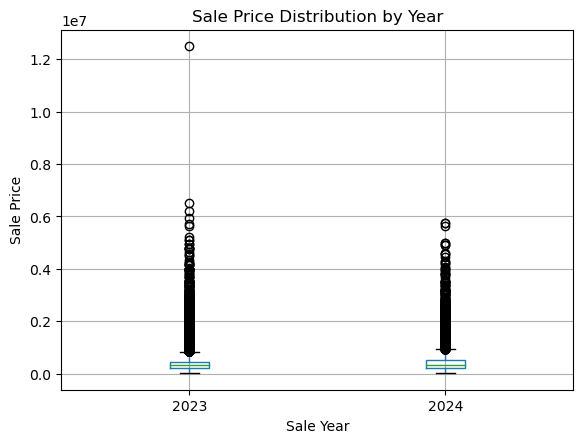

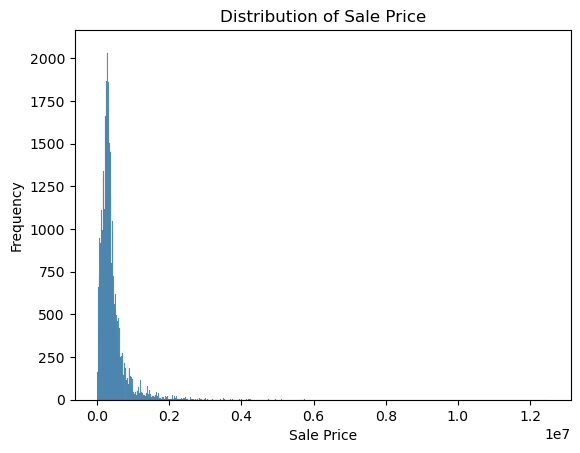

In [ ]:
year_price_summary = train_data.groupby('sale_year')['sale_price'].agg(
    count='count',
    mean='mean',
    median='median',
    std='std',
    min='min',
    max='max'
)

print(year_price_summary.round(2))

# Draw the boxplot to find
train_data.boxplot(
    column='sale_price',
    by='sale_year'
)

plt.title('Sale Price Distribution by Year')
plt.suptitle('')
plt.xlabel('Sale Year')
plt.ylabel('Sale Price')
save_figure("01_sale_price_boxplot_by_year")
plt.show()


sns.histplot(train_data['sale_price'])
plt.title('Distribution of Sale Price')
plt.xlabel('Sale Price')
plt.ylabel('Frequency')
save_figure("02_sale_price_histogram")
plt.show()

从上述结果看出，23年到24年中期之间sale price的中位数和均值都有着明显的上涨，且都存在极端值影响的情况以及右尾分布，这将影响我们进一步EDA的分析，因而我们下面采用log transform来抵消极端值产生的影响

           count   mean  median   std   min    max
sale_year                                         
2023       37520  12.63   12.66  0.77  9.27  16.34
2024       17333  12.72   12.74  0.76  9.27  15.56


<Figure size 900x500 with 0 Axes>

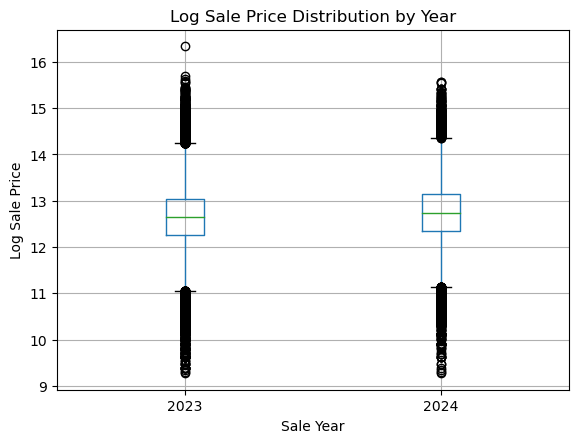

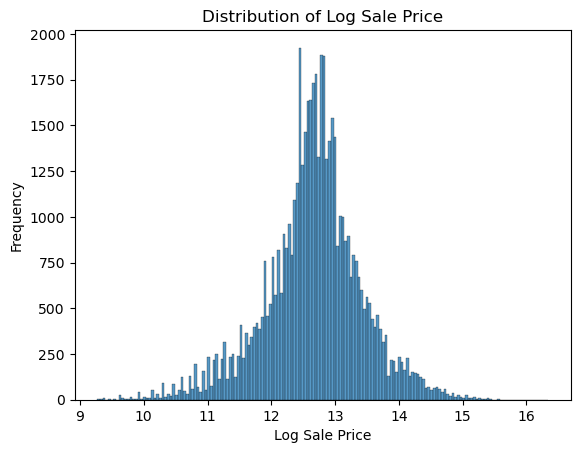

In [ ]:
# Already checked that all sale prices are larger than 0
# use log transform to offset the influence of extreme value
train_data['log_sale_price'] = np.log1p(train_data['sale_price'])

year_logprice_summary = train_data.groupby('sale_year')['log_sale_price'].agg(
    count='count',
    mean='mean',
    median='median',
    std='std',
    min='min',
    max='max'
)

plt.figure(figsize=(9, 5))

print(year_logprice_summary.round(2))

# Draw the boxplot to find
train_data.boxplot(
    column='log_sale_price',
    by='sale_year'
)

plt.title('Log Sale Price Distribution by Year')
plt.suptitle('')
plt.xlabel('Sale Year')
plt.ylabel('Log Sale Price')
save_figure("03_log_sale_price_boxplot_by_year")
plt.show()

sns.histplot(train_data['log_sale_price'])
plt.title('Distribution of Log Sale Price')
plt.xlabel('Log Sale Price')
plt.ylabel('Frequency')
save_figure("04_log_sale_price_histogram")
plt.show()

Form the above

从上图看出，采用log变换后，极端值的影响减小，sale price的分布更加偏向正态。我们通过对training set的response variable发现及log变换，应用到其余两个set中。


In [ ]:
val_data['log_sale_price'] = np.log1p(val_data['sale_price'])
test_data['log_sale_price'] = np.log1p(test_data['sale_price'])


Organizing feature types

我们对每个不同类型的feature index进行归集，分成不同list，便于后续EDA分析

In [ ]:
# Filter the feature that have missing value
missing_count_train = train_data.isnull().sum()
missing_fraction_train = train_data.isnull().mean()

missing_report = pd.DataFrame({
    'Count': missing_count_train,
    'Fraction': missing_fraction_train
})

missing_report = missing_report[missing_report['Count'] > 0].sort_values('Fraction', ascending=False)
print(missing_report)


                                                  Count  Fraction
loc_tax_special_service_area_num                  53291  0.971524
loc_school_unified_district_geoid                 52899  0.964378
loc_tax_tif_district_num                          50204  0.915246
char_tp_dsgn                                      29566  0.539004
char_tp_plan                                      15620  0.284761
prox_avg_school_rating_in_half_mile               13549  0.247006
acs5_median_household_total_occupied_year_built   12204  0.222486
char_gar1_cnst                                     9119  0.166244
other_school_district_elementary_avg_rating        2110  0.038466
other_school_district_secondary_avg_rating         2010  0.036643
loc_school_secondary_district_geoid                1954  0.035622
loc_school_elementary_district_geoid               1954  0.035622
acs5_median_household_renter_occupied_gross_rent   1377  0.025103
char_apts                                           487  0.008878
prox_num_f

检查miss value fraction比例在1%以内的feature，判断这些微小缺失值对应的样本数据是否对price有着较大影响



In [ ]:
# Handle features whose missing value fractions are under 1%
# Extract features whose missing value fractions are under 1%
low_missing_cols = missing_report[missing_report['Fraction'] < 0.01].index
low_missing_cols_list = low_missing_cols.tolist()

print("Feature having missing fraction between 0% and 1% has amount", len(low_missing_cols_list), " ：")
print(low_missing_cols_list,'\n')

# Compare median sales price in missing value part to that in non-missing part
mnar_candidates = []

for col in low_missing_cols_list:
    missing_group = train_data[train_data[col].isnull()]["sale_price"]
    non_missing_group = train_data[train_data[col].notna()]["sale_price"]

    med_miss = missing_group.median()
    med_non_miss = non_missing_group.median()

    # If notna group's median not equal to 0, calculate diff percentage
    if med_non_miss > 0 and med_miss > 0:
        diff_pct = abs(med_miss - med_non_miss) / med_non_miss

        print(f"--- {col} ---")
        print(f"Missing median: {med_miss:.0f} | Non-missing median: {med_non_miss:.0f} | Diff: {diff_pct:.2%}")

        # if median's diff percentage outweigh 10%, identified as MNAR
        if diff_pct > 0.10:
            mnar_candidates.append(col)

print(f"\nFeatures identified as MNAR (price diff > 10%): {mnar_candidates}")



Feature having missing fraction between 0% and 1% has amount 19  ：
['char_apts', 'prox_num_foreclosure_per_1000_pin_past_5_years', 'loc_property_zip', 'acs5_median_household_owner_occupied_value', 'meta_cdu', 'loc_env_flood_fs_factor', 'loc_env_flood_fs_risk_direction', 'char_frpl', 'other_tax_bill_rate', 'char_gar1_area', 'char_gar1_att', 'char_porch', 'char_bsmt_fin', 'char_heat', 'char_attic_fnsh', 'char_gar1_size', 'loc_access_cmap_walk_nta_score', 'loc_access_cmap_walk_total_score', 'char_bsmt'] 

--- char_apts ---
Missing median: 242000 | Non-missing median: 325000 | Diff: 25.54%
--- prox_num_foreclosure_per_1000_pin_past_5_years ---
Missing median: 695000 | Non-missing median: 324000 | Diff: 114.51%


--- loc_property_zip ---
Missing median: 415000 | Non-missing median: 325000 | Diff: 27.69%
--- acs5_median_household_owner_occupied_value ---
Missing median: 203000 | Non-missing median: 325000 | Diff: 37.54%
--- meta_cdu ---
Missing median: 680000 | Non-missing median: 325000 | Diff: 109.23%
--- loc_env_flood_fs_factor ---
Missing median: 499500 | Non-missing median: 325000 | Diff: 53.69%


--- loc_env_flood_fs_risk_direction ---
Missing median: 499500 | Non-missing median: 325000 | Diff: 53.69%
--- char_frpl ---
Missing median: 669500 | Non-missing median: 325000 | Diff: 106.00%
--- other_tax_bill_rate ---
Missing median: 590000 | Non-missing median: 325000 | Diff: 81.54%


--- char_gar1_area ---
Missing median: 448271 | Non-missing median: 325000 | Diff: 37.93%
--- char_gar1_att ---
Missing median: 448271 | Non-missing median: 325000 | Diff: 37.93%
--- char_porch ---
Missing median: 768750 | Non-missing median: 325000 | Diff: 136.54%


--- char_bsmt_fin ---
Missing median: 712500 | Non-missing median: 325000 | Diff: 119.23%
--- char_heat ---
Missing median: 707000 | Non-missing median: 325000 | Diff: 117.54%
--- char_attic_fnsh ---
Missing median: 684500 | Non-missing median: 325000 | Diff: 110.62%


--- char_gar1_size ---
Missing median: 2395000 | Non-missing median: 325000 | Diff: 636.92%
--- loc_access_cmap_walk_nta_score ---
Missing median: 1802500 | Non-missing median: 325000 | Diff: 454.62%
--- loc_access_cmap_walk_total_score ---
Missing median: 1802500 | Non-missing median: 325000 | Diff: 454.62%
--- char_bsmt ---
Missing median: 689000 | Non-missing median: 325000 | Diff: 112.00%

Features identified as MNAR (price diff > 10%): ['char_apts', 'prox_num_foreclosure_per_1000_pin_past_5_years', 'loc_property_zip', 'acs5_median_household_owner_occupied_value', 'meta_cdu', 'loc_env_flood_fs_factor', 'loc_env_flood_fs_risk_direction', 'char_frpl', 'other_tax_bill_rate', 'char_gar1_area', 'char_gar1_att', 'char_porch', 'char_bsmt_fin', 'char_heat', 'char_attic_fnsh', 'char_gar1_size', 'loc_access_cmap_walk_nta_score', 'loc_access_cmap_walk_total_score', 'char_bsmt']


由于这些微小缺失比率的特征值，对比非特征值缺失的样本和特征值缺失样本的price中位数差异超过10%的，在以上列表的都满足。我们对缺失值数额超过50的进行missing indicator+众数/中位数进行填补，对小于50的特征值用简单插补法填补

In [ ]:
# Select those feature having less than 50 missing value to replace by mode or median
# 1. 提取微小缺失和中低缺失列
tiny_missing_cols_list = missing_report[missing_report['Count'] <= 50].index.tolist()
mnar_list = [col for col in low_missing_cols_list if col not in tiny_missing_cols_list]

medians_dict = {}
modes_dict = {}
boolean_cols = [] # 就地记录哪些是二值列

for col in tiny_missing_cols_list + mnar_list:
    if col not in train_data.columns: continue

    # --- 就地识别 Boolean (非空取值 <= 2) ---
    unique_vals = train_data[col].dropna().unique()
    if len(unique_vals) <= 2 and len(unique_vals) > 0:
        boolean_cols.append(col)
        # 对 Boolean 用众数填
        mode_series = train_data[col].mode()
        medians_dict[col] = mode_series.iloc[0] if not mode_series.empty else 0
        continue # 跳过后续的普通数值/字符串判断

    # --- 原有逻辑 ---
    if pd.api.types.is_numeric_dtype(train_data[col]):
        median_val = train_data[col].median()
        medians_dict[col] = median_val if pd.notna(median_val) else 0
    else:
        mode_series = train_data[col].mode()
        modes_dict[col] = mode_series.iloc[0] if not mode_series.empty else "Unknown"


def fill_datasets(df):
    df = df.copy()

    for col in tiny_missing_cols_list:
        if col not in df.columns: continue

        if col in boolean_cols:
            # 拯救 Boolean：填补并强制保留 Int64 格式
            df[col] = df[col].fillna(medians_dict[col]).astype('Int64')
        elif col in medians_dict:
            df[col] = df[col].astype(float).fillna(medians_dict[col])
        elif col in modes_dict:
            df[col] = df[col].fillna(modes_dict[col])

    for col in mnar_list:
        if col not in df.columns: continue

        ind_col = f"{col}_missing"
        df[ind_col] = df[col].isna().astype(int)

        if col in boolean_cols:
            df[col] = df[col].fillna(medians_dict[col]).astype('Int64')
        elif col in medians_dict:
            df[col] = df[col].astype(float).fillna(medians_dict[col])
        elif col in modes_dict:
            df[col] = df[col].fillna(modes_dict[col])

    return df

# 执行填补
train_data = fill_datasets(train_data)
val_data = fill_datasets(val_data)
test_data = fill_datasets(test_data)


# 检查填补后是否还有极低缺失
remaining_missing = train_data[tiny_missing_cols_list + mnar_list].isnull().sum().sum()
print(f"填补后 train_data 剩余缺失值数量: {remaining_missing}")

填补后 train_data 剩余缺失值数量: 0


In [ ]:
for col in tiny_missing_cols_list + mnar_list:
    if col in medians_dict and property_list[col].notna().all(): # 确认没有空值了
        train_data[col] = train_data[col].astype('int64')

针对missing fraction占比超过90%的feature

In [ ]:
cols_to_fill = [
    'loc_tax_special_service_area_num',
    'loc_school_unified_district_geoid',
    'loc_tax_tif_district_num'
]

for df in [train_data, val_data, test_data]:
    for col in cols_to_fill:
        # 1. 先定义缺失指示器 (必须加上，因为这 90% 的缺失本身就是特征)
        df[f"{col}_is_missing"] = df[col].isnull().astype(int)

        # 2. 填补缺失值 (将原本的 NaN 填补为 "Unknown")
        # 使用 .astype('string') 而不是 str，是为了保证如果是其他缺失值（<NA>）仍然能被识别
        df[col] = df[col].fillna("Unknown").astype('string')

        # 3. (可选) 转为 category 类型。对于高基数的字符串，转化为 category 可以让 LightGBM 直接作为类别特征处理，节省内存并提高效率
        df[col] = df[col].astype('category')


In [ ]:
high_missing_cols_list = missing_report[missing_report['Fraction'] >= 0.01].index.tolist()

cols_already_handled = [
    'loc_tax_special_service_area_num',
    'loc_school_unified_district_geoid',
    'loc_tax_tif_district_num'
]
high_missing_cols_list = [c for c in high_missing_cols_list if c not in cols_already_handled]

# 先对原始 dtype 做快照（避免后续 fillna/astype 改变判断依据）
original_dtypes = {col: train_data[col].dtype for col in high_missing_cols_list}

high_medians = {}
high_modes = {}
geoid_cols = ['loc_school_elementary_district_geoid', 'loc_school_secondary_district_geoid']

# 布尔型 / 0-1 型列的识别（Int64、boolean、以及取值子集为 {0,1} 的整数列）
def is_boolean_like(col):
    s = train_data[col]
    if pd.api.types.is_bool_dtype(s):
        return True
    if pd.api.types.is_integer_dtype(s):
        uniq = set(s.dropna().unique().tolist())
        return uniq.issubset({0, 1})
    return False

bool_like_cols = {c for c in high_missing_cols_list if is_boolean_like(c)}

# 2. 提取中位数和众数（带防崩溃机制）
for col in high_missing_cols_list:
    if col in geoid_cols:
        continue
    if col in bool_like_cols:
        continue  # 布尔型不取中位数/众数，走单独分支

    if pd.api.types.is_numeric_dtype(train_data[col]):
        med = train_data[col].median()
        high_medians[col] = med if pd.notna(med) else 0.0
    else:
        mode_series = train_data[col].mode()
        if not mode_series.empty and pd.notna(mode_series.iloc[0]):
            high_modes[col] = mode_series.iloc[0]
        else:
            high_modes[col] = "Unknown"

# 3. 定义高缺失率填补函数
def fill_high_missing(df, cols_list, medians_map, modes_map, geoids, bool_cols, orig_dtypes):
    df = df.copy()

    for col in cols_list:
        # A. 缺失指示器（加去重保护，防止重复调用）
        miss_col = f"{col}_missing"
        if miss_col not in df.columns:
            df[miss_col] = df[col].isna().astype(int)

        # B. 按列性质分类填补
        if col in geoids:
            # 学区代码：填 Unknown，保持 string
            df[col] = df[col].fillna("Unknown").astype('string')

        elif col in bool_cols:
            # 布尔/0-1 列：不参与数值中位数，填 0 或 False，保持 Int64/boolean
            orig_dtype = orig_dtypes.get(col)
            if pd.api.types.is_bool_dtype(orig_dtype):
                df[col] = df[col].fillna(False).astype('boolean')
            else:
                # 原本是 Int64 的 0/1 列：填 0，保持 Int64，不转 float
                df[col] = df[col].fillna(0).astype('Int64')

        elif col in medians_map:
            # 真·数值型：安全转数值后填中位数
            df[col] = pd.to_numeric(df[col], errors='coerce')
            df[col] = df[col].fillna(medians_map[col]).astype(float)

        elif col in modes_map:
            orig_dtype = orig_dtypes.get(col)
            if pd.api.types.is_integer_dtype(orig_dtype):
                # 其他整数型类别列：-1 表示 Unknown
                df[col] = df[col].fillna(-1).astype('Int64')
            else:
                df[col] = df[col].fillna(modes_map[col]).astype('string')

    return df

# 4. 执行（显式传参，避免全局变量陷阱）
train_data = fill_high_missing(
    train_data, high_missing_cols_list, high_medians, high_modes, geoid_cols, bool_like_cols, original_dtypes
)
val_data = fill_high_missing(
    val_data, high_missing_cols_list, high_medians, high_modes, geoid_cols, bool_like_cols, original_dtypes
)
test_data = fill_high_missing(
    test_data, high_missing_cols_list, high_medians, high_modes, geoid_cols, bool_like_cols, original_dtypes
)

In [ ]:
# Check again whether there is any missing value left

check_miss_train = train_data.isnull().sum().sort_values(ascending=False)
check_miss_vali = val_data.isnull().sum().sort_values(ascending=False)
check_miss_test = test_data.isnull().sum().sort_values(ascending=False)

check_miss_train = check_miss_train[check_miss_train > 0]
check_miss_vali = check_miss_vali[check_miss_vali > 0]
check_miss_test = check_miss_test[check_miss_test > 0]

print ('train missing value left: \n',check_miss_train)
print ('\nvali missing value left: \n',check_miss_vali)
print ('\ntest missing value left: \n',check_miss_test)

train missing value left: 
 Series([], dtype: int64)

vali missing value left: 
 char_air      2
char_yrblt    1
dtype: int64

test missing value left: 
 char_air                                  1
acs5_median_income_household_past_year    1
dtype: int64


我们检查到，training set中已经不存在missing value的情况，但是在validation set 和test set仍然存在，这是因为这一部分的missing value按照年度+季度划分时仅仅被包含在后两者dataset中。同时由于missing value非常少，使得training set中并未观测出缺失的现象。 为了防止leakage的产生，同时这三类待填补的missing value的数量非常稀少，我们采用simple imputation的方法，从training set中的对应feature获取mode或median数据进行填补。

In [ ]:
# 1. 获取缺失列
missing_cols = set(val_data.columns[val_data.isnull().any()]) | \
               set(test_data.columns[test_data.isnull().any()])

# 2. 定义安全填补函数
def safe_fill_missing(train_df, target_df, col):
    # 如果 train 里没这一列，或者全为空，就不填了
    if col not in train_df.columns or train_df[col].isnull().all():
        return target_df

    train_dtype = train_df[col].dtype
    target_dtype = target_df[col].dtype

    # ==========================================
    # 情形 A：类别/字符串型 (string, object, category) -> 绝不转数值，用众数填
    # ==========================================
    if pd.api.types.is_string_dtype(train_dtype) or \
       pd.api.types.is_object_dtype(train_dtype) or \
       isinstance(train_dtype, pd.CategoricalDtype):

        mode_series = train_df[col].mode()
        fill_val = mode_series.iloc[0] if not mode_series.empty else "Unknown"

        # 如果是 category 类型，需先添加新的类别
        if isinstance(target_dtype, pd.CategoricalDtype):
            if fill_val not in target_df[col].cat.categories:
                target_df[col] = target_df[col].cat.add_categories([fill_val])

        target_df[col] = target_df[col].fillna(fill_val)

    # ==========================================
    # 情形 B：可空整数型 (Int64) -> 填补其众数，保持 Int64
    # ==========================================
    elif pd.api.types.is_integer_dtype(train_dtype):
        # 整数类别的填补通常用众数，而不是中位数（避免出现 2.5 这种无意义小数）
        mode_series = train_df[col].mode()
        fill_val = mode_series.iloc[0] if not mode_series.empty else 0

        # 填补并保持 Int64
        target_df[col] = target_df[col].fillna(fill_val).astype('Int64')

    # ==========================================
    # 情形 C：纯连续数值型 (float) -> 用中位数填
    # ==========================================
    elif pd.api.types.is_numeric_dtype(train_dtype):
        fill_val = train_df[col].median()
        if pd.isna(fill_val):
            fill_val = 0.0
        # 直接按 float 填
        target_df[col] = pd.to_numeric(target_df[col], errors='coerce').astype('float64').fillna(fill_val)

    # ==========================================
    # 情形 D：其他兜底
    # ==========================================
    else:
        mode_series = train_df[col].mode()
        fill_val = mode_series.iloc[0] if not mode_series.empty else "Unknown"
        target_df[col] = target_df[col].fillna(fill_val)

    return target_df

# 3. 循环填补
for col in missing_cols:
    print(f"Feature [{col:50s}] -> 尝试用 Train 的统计量填补 Val 和 Test...")
    val_data = safe_fill_missing(train_data, val_data, col)
    test_data = safe_fill_missing(train_data, test_data, col)

# 4. 最终验证
print("\n--- Final check ---")
print("train missing:", train_data.isnull().sum().sum())
print("val missing:  ", val_data.isnull().sum().sum())
print("test missing: ", test_data.isnull().sum().sum())

# 强制类型对齐（可选，确保三套数据集类型一致）
for col in missing_cols:
    if col in train_data.columns:
        # 对齐 Int64
        if pd.api.types.is_integer_dtype(train_data[col]):
            val_data[col] = val_data[col].round().astype('Int64')
            test_data[col] = test_data[col].round().astype('Int64')
        # 对齐 string
        elif pd.api.types.is_string_dtype(train_data[col]) or isinstance(train_data[col].dtype, pd.CategoricalDtype):
            val_data[col] = val_data[col].astype(train_data[col].dtype)
            test_data[col] = test_data[col].astype(train_data[col].dtype)

Feature [char_yrblt                                        ] -> 尝试用 Train 的统计量填补 Val 和 Test...
Feature [char_air                                          ] -> 尝试用 Train 的统计量填补 Val 和 Test...
Feature [acs5_median_income_household_past_year            ] -> 尝试用 Train 的统计量填补 Val 和 Test...

--- Final check ---


train missing: 0
val missing:   0
test missing:  0


注意以上的对training set之外其余两个set中发现的存有缺失值的特征，我们进行了简单填补，虽然有年份类的特征值数据，但在我们training set没发现的情况下，以及缺失量非常小的情况，我们评估使用简单插补（利用中位数or众数）填补是合理的

Before we set packages for different types of features, we firstly do EDA to analyze price/ log price change over time and across locations

Training-only temporal sale-price diagnostic

Monthly training-period summary
 sale_year  sale_month  transactions  mean_price  median_price      p25      p75 sale_ym
      2023           1          1973   349771.98      275000.0 175000.0 395000.0 2023-01
      2023           2          2274   367060.27      288000.0 185000.0 420000.0 2023-02
      2023           3          3305   391969.52      300000.0 200000.0 450000.0 2023-03
      2023           4          3217   405212.99      320000.0 210000.0 457500.0 2023-04
      2023           5          3847   420153.53      327500.0 220000.0 479900.0 2023-05
      2023           6          4147   448046.70      340000.0 224850.0 525000.0 2023-06
      2023           7          3529   430020.59      335000.0 225000.0 500000.0 2023-07
      2023           8          3682   421039.75      330000.0 223312.5 480000.0 2023-08
      2023           9          3149   412149.97      319900.0 218000.0 475000.0 2023-09
      2023          10          

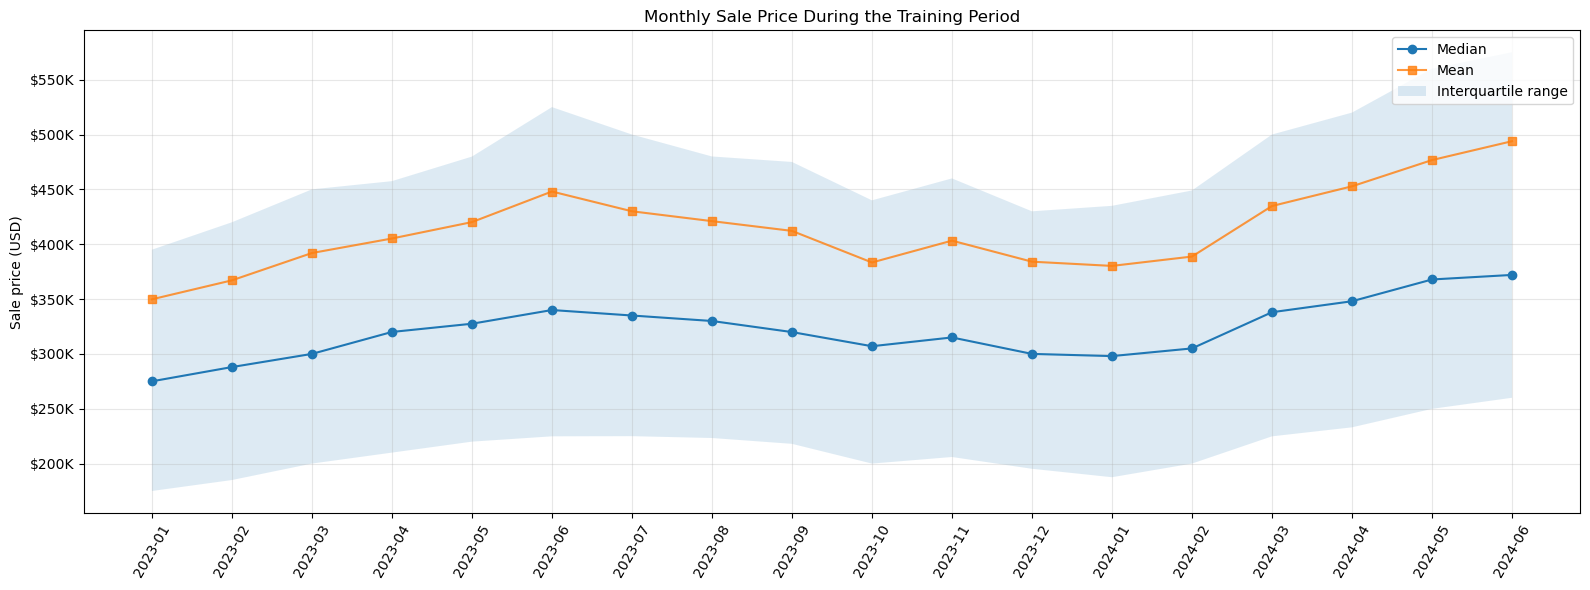


Comparable January-June year summary
           transactions  mean_price  median_price
sale_year                                        
2023              18763  404,956.82    313,000.00
2024              17333  445,232.43    340,000.00
January-June median change from 2023 to 2024: +8.63%

Same-month median comparison
sale_year        2023       2024  change_percent
sale_month                                      
1          275,000.00 298,000.00            8.36
2          288,000.00 305,000.00            5.90
3          300,000.00 338,000.00           12.67
4          320,000.00 348,000.00            8.75
5          327,500.00 367,850.00           12.32
6          340,000.00 372,000.00            9.41

Interpretation guardrail: these are descriptive transaction-price patterns. They may reflect market timing and changes in the mix of properties sold; they do not establish a causal seasonal premium.


In [ ]:
print("=" * 80)
print("Training-only temporal sale-price diagnostic")
print("=" * 80)

time_price_summary = (
    train_data.groupby(["sale_year", "sale_month"])["sale_price"]
    .agg(
        transactions="count",
        mean_price="mean",
        median_price="median",
        p25=lambda values: values.quantile(0.25),
        p75=lambda values: values.quantile(0.75),
    )
    .reset_index()
)
time_price_summary["sale_ym"] = (
    time_price_summary["sale_year"].astype(str)
    + "-"
    + time_price_summary["sale_month"].astype(str).str.zfill(2)
)

print("\nMonthly training-period summary")
print(time_price_summary.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(16, 6))
ax.plot(
    time_price_summary["sale_ym"],
    time_price_summary["median_price"],
    marker="o",
    label="Median",
)
ax.plot(
    time_price_summary["sale_ym"],
    time_price_summary["mean_price"],
    marker="s",
    label="Mean",
    alpha=0.8,
)
ax.fill_between(
    time_price_summary["sale_ym"],
    time_price_summary["p25"],
    time_price_summary["p75"],
    alpha=0.15,
    label="Interquartile range",
)
ax.set_title("Monthly Sale Price During the Training Period")
ax.set_ylabel("Sale price (USD)")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda value, _: f"${value/1e3:.0f}K"))
ax.tick_params(axis="x", rotation=60)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
save_figure("05_monthly_sale_price_training")
plt.show()

# Compare like-for-like calendar months because the training data contain only
# January-June for 2024 but all twelve months for 2023.
comparable_period = train_data.loc[train_data["sale_month"].between(1, 6)].copy()
comparable_year_summary = (
    comparable_period.groupby("sale_year")["sale_price"]
    .agg(transactions="count", mean_price="mean", median_price="median")
)
jan_jun_2023 = comparable_year_summary.loc[2023, "median_price"]
jan_jun_2024 = comparable_year_summary.loc[2024, "median_price"]
comparable_change = (jan_jun_2024 / jan_jun_2023 - 1) * 100

same_month_medians = comparable_period.pivot_table(
    index="sale_month",
    columns="sale_year",
    values="sale_price",
    aggfunc="median",
)
same_month_medians["change_percent"] = (
    same_month_medians[2024] / same_month_medians[2023] - 1
) * 100

print("\nComparable January-June year summary")
print(comparable_year_summary.to_string(float_format=lambda value: f"{value:,.2f}"))
print(f"January-June median change from 2023 to 2024: {comparable_change:+.2f}%")
print("\nSame-month median comparison")
print(same_month_medians.to_string(float_format=lambda value: f"{value:,.2f}"))
print(
    "\nInterpretation guardrail: these are descriptive transaction-price patterns. "
    "They may reflect market timing and changes in the mix of properties sold; "
    "they do not establish a causal seasonal premium."
)



Training-only spatial sale-price diagnostic
City column: loc_property_city
Non-missing city values: 54,853
Distinct cities: 132


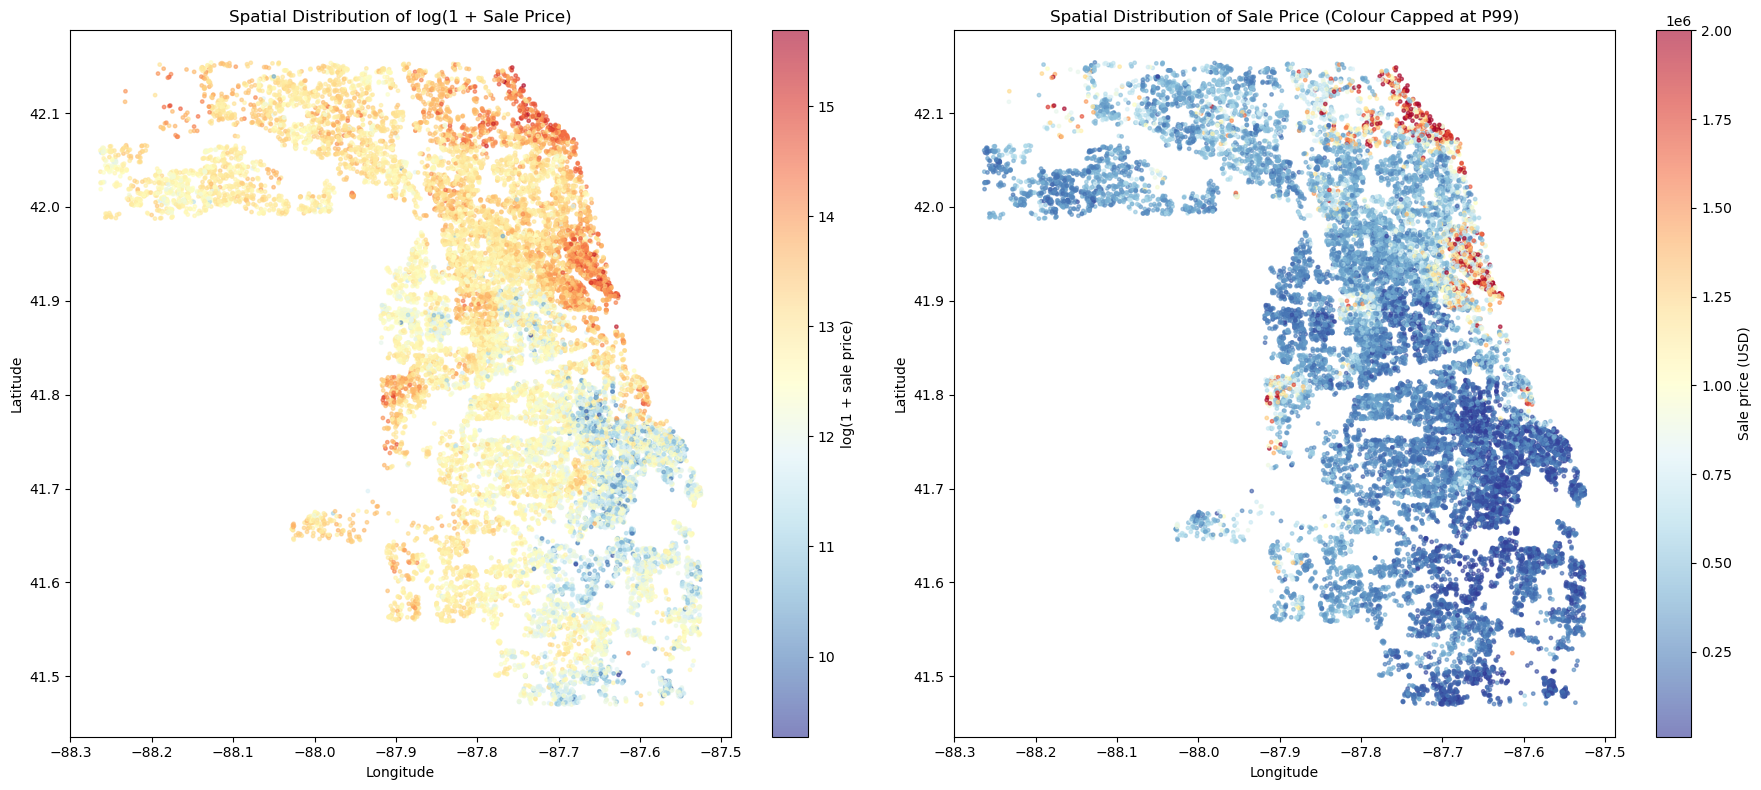

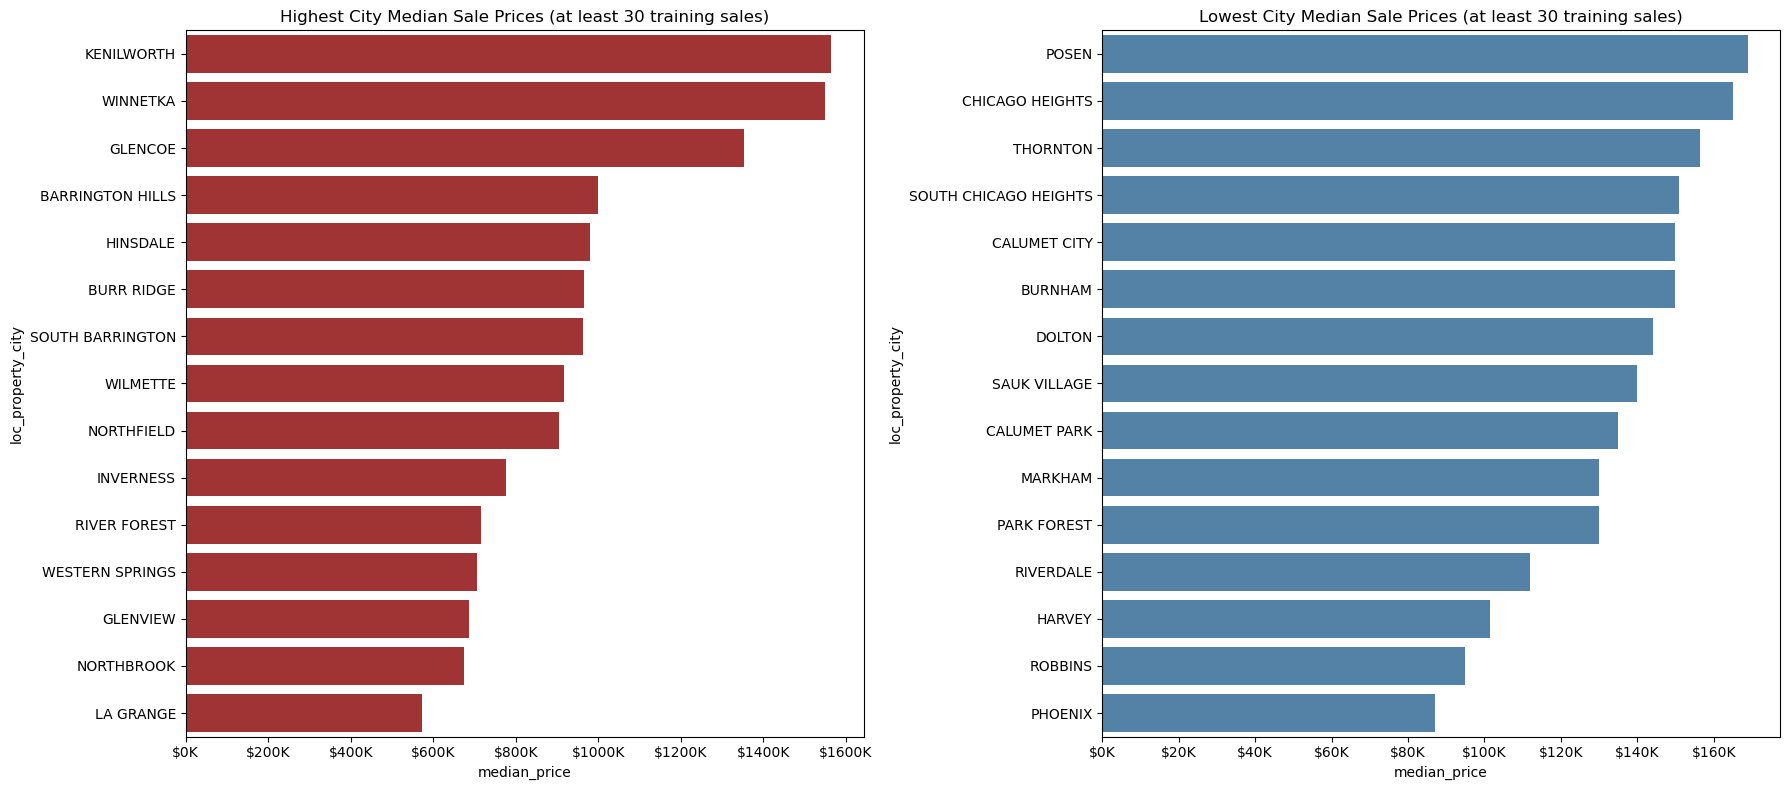


Most frequent cities
                   transactions  mean_price  median_price
loc_property_city                                        
CHICAGO                   22235  421,703.43    310,000.00
ARLINGTON HEIGHTS           981  535,774.36    485,000.00
ORLAND PARK                 923  451,580.93    400,000.00
DES PLAINES                 832  366,691.91    350,000.00
PALATINE                    786  441,564.11    415,000.00
GLENVIEW                    784  818,066.63    687,000.00
OAK PARK                    738  561,564.96    525,000.00
OAK LAWN                    727  306,120.16    301,000.00
SCHAUMBURG                  701  417,919.05    395,000.00
TINLEY PARK                 690  336,830.03    322,000.00

Latitude-decile median ratio: 2.66x
Longitude-decile median ratio: 2.25x
Interpretation guardrail: the maps and grouped medians show spatial association, not a causal location effect. Property type, size, condition, transaction mix and other neighbourhood factors can confound thes

In [ ]:
print("\n" + "=" * 80)
print("Training-only spatial sale-price diagnostic")
print("=" * 80)

city_column = "loc_property_city"
required_columns = {
    city_column,
    "loc_longitude",
    "loc_latitude",
    "sale_price",
}
missing_columns = required_columns - set(train_data.columns)
if missing_columns:
    raise KeyError(f"Missing spatial diagnostic columns: {sorted(missing_columns)}")

spatial_eda = train_data[list(required_columns)].copy()
print(f"City column: {city_column}")
print(f"Non-missing city values: {spatial_eda[city_column].notna().sum():,}")
print(f"Distinct cities: {spatial_eda[city_column].nunique(dropna=True):,}")

plot_sample = spatial_eda.sample(min(20_000, len(spatial_eda)), random_state=42)
display_cap = plot_sample["sale_price"].quantile(0.99)
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

raw_scatter = axes[0].scatter(
    plot_sample["loc_longitude"],
    plot_sample["loc_latitude"],
    c=np.log1p(plot_sample["sale_price"]),
    cmap="RdYlBu_r",
    s=6,
    alpha=0.6,
)
axes[0].set_title("Spatial Distribution of log(1 + Sale Price)")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
plt.colorbar(raw_scatter, ax=axes[0], label="log(1 + sale price)")

clipped_scatter = axes[1].scatter(
    plot_sample["loc_longitude"],
    plot_sample["loc_latitude"],
    c=plot_sample["sale_price"].clip(upper=display_cap),
    cmap="RdYlBu_r",
    s=6,
    alpha=0.6,
)
axes[1].set_title("Spatial Distribution of Sale Price (Colour Capped at P99)")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")
plt.colorbar(clipped_scatter, ax=axes[1], label="Sale price (USD)")
plt.tight_layout()
save_figure("06_spatial_sale_price_maps")
plt.show()

city_summary = (
    spatial_eda.groupby(city_column)["sale_price"]
    .agg(transactions="count", mean_price="mean", median_price="median")
)
city_summary = city_summary.loc[city_summary["transactions"] >= 30]
city_summary = city_summary.sort_values("median_price", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
sns.barplot(
    x=city_summary.head(15)["median_price"],
    y=city_summary.head(15).index,
    ax=axes[0],
    color="firebrick",
)
sns.barplot(
    x=city_summary.tail(15)["median_price"],
    y=city_summary.tail(15).index,
    ax=axes[1],
    color="steelblue",
)
axes[0].set_title("Highest City Median Sale Prices (at least 30 training sales)")
axes[1].set_title("Lowest City Median Sale Prices (at least 30 training sales)")
for axis in axes:
    axis.xaxis.set_major_formatter(
        mtick.FuncFormatter(lambda value, _: f"${value/1e3:.0f}K")
    )
plt.tight_layout()
save_figure("07_city_median_sale_prices")
plt.show()

latitude_bins = pd.qcut(spatial_eda["loc_latitude"], q=10, duplicates="drop")
longitude_bins = pd.qcut(spatial_eda["loc_longitude"], q=10, duplicates="drop")
latitude_medians = spatial_eda.groupby(latitude_bins, observed=True)["sale_price"].median()
longitude_medians = spatial_eda.groupby(longitude_bins, observed=True)["sale_price"].median()

print("\nMost frequent cities")
print(
    city_summary.sort_values("transactions", ascending=False)
    .head(10)
    .to_string(float_format=lambda value: f"{value:,.2f}")
)
print(
    f"\nLatitude-decile median ratio: "
    f"{latitude_medians.max() / latitude_medians.min():.2f}x"
)
print(
    f"Longitude-decile median ratio: "
    f"{longitude_medians.max() / longitude_medians.min():.2f}x"
)
print(
    "Interpretation guardrail: the maps and grouped medians show spatial "
    "association, not a causal location effect. Property type, size, condition, "
    "transaction mix and other neighbourhood factors can confound these patterns."
)


Next, we separate feature according to their data type to do EDA.

In [ ]:
# delete irrelevant columns for training model

drop_cols = ['sale_date', 'sale_quarter','transaction_id']

train_data = train_data.drop(columns=[c for c in drop_cols if c in train_data.columns])
val_data   = val_data.drop(columns=[c for c in drop_cols if c in val_data.columns])
test_data  = test_data.drop(columns=[c for c in drop_cols if c in test_data.columns])

# Verify whether 3 sets' columns still the same
cols_train = set(train_data.columns)
cols_val   = set(val_data.columns)
cols_test  = set(test_data.columns)

print("train vs val diff:", cols_train ^ cols_val)
print("train vs test diff:", cols_train ^ cols_test)
print("All 3 set columns are the same:", cols_train == cols_val == cols_test)

train vs val diff: set()
train vs test diff: set()
All 3 set columns are the same: True


In [ ]:
exclude_cols = ['sale_price', 'log_sale_price','sale_month', 'sale_year']
type_map = var_dict.set_index('variable')['type'].to_dict()
available_features = [c for c in train_data.columns if c not in exclude_cols]

# 初始化四个包
pkg_continuous = []     # 连续数值型 (float)
pkg_discrete = []       # 离散数值型 (int, 计数)
pkg_boolean = []        # 二值/指示器 (严格 0/1)
pkg_category = []       # 类别/标签 (str, 或 1/2 这类非真布尔)

for col in available_features:
    # 1. 获取该列的去重值（转成 set 方便比对，统一转成字符串以防 0 和 '0' 混杂）
    unique_set = set(train_data[col].dropna().astype(str).unique())
    n_unique = len(unique_set)

    # ==========================================
    # 优先级 1：真正的 Boolean / Indicator 类 (严格判定)
    # ==========================================
    # 真正的 boolean 必须是 0/1（或者布尔值转字符串后的 '0'/'1'）
    if n_unique > 0 and unique_set.issubset({'0', '1'}):
        pkg_boolean.append(col)
        continue

    # ==========================================
    # 优先级 2：Categorical / Label 类 (非 0/1 的低基数)
    # ==========================================
    col_type = type_map.get(col, 'unknown')

    # 如果字典里定义为 categorical，或者当前列已经是 string 类型
    if col_type == 'categorical' or pd.api.types.is_string_dtype(train_data[col]) or isinstance(train_data[col].dtype, pd.CategoricalDtype):
        pkg_category.append(col)
        continue

    # ==========================================
    # 优先级 3：Numeric 拆分为 Continuous 和 Discrete
    # ==========================================
    if col_type == 'numeric':
        # 如果是数值，且取值少（<=15），且全是整数
        unique_vals = train_data[col].dropna().unique()
        if n_unique <= 15 and all(float(x).is_integer() for x in unique_vals):
            pkg_discrete.append(col)
        else:
            pkg_continuous.append(col)
        continue

    # ==========================================
    # 优先级 4：字典没有的自定义特征（兜底）
    # ==========================================
    if pd.api.types.is_float_dtype(train_data[col]) and n_unique > 15:
        pkg_continuous.append(col)
    elif n_unique <= 15:
        pkg_discrete.append(col)
    else:
        pkg_category.append(col)

# ==========================================
# 打印结果并拆分 DataFrame
# ==========================================
print(f"✅ 连续数值型 (Continuous, float): {len(pkg_continuous)} 个")
print(f"✅ 离散数值型 (Discrete, int/低基数): {len(pkg_discrete)} 个")
print(f"✅ 布尔/指示器 (Boolean, 0/1): {len(pkg_boolean)} 个")
print(f"✅ 类别/标签 (Category, str): {len(pkg_category)} 个")

# 打印一下被“踢出” Boolean 的列，验证一下是不是 1/2 这种
suspect_cat = [c for c in pkg_category if set(train_data[c].dropna().astype(str).unique()).issubset({'1', '2'})]
if suspect_cat:
    print(f"\n💡 发现 {len(suspect_cat)} 个原本可能被误判为 Boolean 的 1/2 类别列，已被正确归入 Category：{suspect_cat[:5]}")

# 真正切分数据
df_continuous = train_data[pkg_continuous]
df_discrete = train_data[pkg_discrete]
df_boolean = train_data[pkg_boolean]
df_category = train_data[pkg_category]

✅ 连续数值型 (Continuous, float): 52 个
✅ 离散数值型 (Discrete, int/低基数): 7 个
✅ 布尔/指示器 (Boolean, 0/1): 27 个
✅ 类别/标签 (Category, str): 33 个



💡 发现 2 个原本可能被误判为 Boolean 的 1/2 类别列，已被正确归入 Category：['char_use', 'char_air']


对不同类别的feature进行分包后，先对numeric的连续数值型，看缺失率排序以及进行EDA分析，我们对这部分feature建立直方图，与log sale price的关系图，和相关系数热力图

对Continuous的feature集合进行直方图观测分布

In [ ]:
# 1. 筛选出包含类似小数点格式的类别列
decimal_cat_cols = []

for col in pkg_category:
    # 获取去重后的非空值，转成字符串
    unique_vals = train_data[col].dropna().astype(str).unique()

    if len(unique_vals) == 0:
        continue

    # 正则检查：至少有一个值符合 "数字.数字" 的格式 (例如 1.0, 9.9)
    has_decimal = any(re.match(r'^-?\d+\.\d+$', str(val).strip()) for val in unique_vals)

    if has_decimal:
        # 打印前 5 个值看看长什么样
        sample_vals = unique_vals[:5]
        decimal_cat_cols.append(col)
        print(f"⚠️ 列 [{col}] 疑似包含小数点：样本值 = {sample_vals}")

if not decimal_cat_cols:
    print("✅ 未发现包含小数点的类别特征。")
else:
    print(f"\n共计发现 {len(decimal_cat_cols)} 个列包含小数点，需要处理。")

⚠️ 列 [loc_property_zip] 疑似包含小数点：样本值 = ['60062.0' '60534.0' '60457.0' '60628.0' '60462.0']


⚠️ 列 [char_type_resd] 疑似包含小数点：样本值 = ['2' '1' '4' '5' '3']


⚠️ 列 [char_tp_plan] 疑似包含小数点：样本值 = ['2.0' '1.0']
⚠️ 列 [loc_chicago_ward_num] 疑似包含小数点：样本值 = ['Non-Chicago' '8.0' '1.0' '37.0' '28.0']
⚠️ 列 [loc_school_elementary_district_geoid] 疑似包含小数点：样本值 = ['1724420.0' '1723850.0' '1728890.0' '610178.0' '1730220.0']
⚠️ 列 [loc_school_secondary_district_geoid] 疑似包含小数点：样本值 = ['1729010.0' '1726880.0' '1708400.0' '609710.0' '1738970.0']
⚠️ 列 [loc_school_unified_district_geoid] 疑似包含小数点：样本值 = ['Unknown' '1713710.0' '1705050.0' '1714100.0' '1708550.0']
⚠️ 列 [loc_tax_special_service_area_num] 疑似包含小数点：样本值 = ['Unknown' '30050108.0' '31290100.0' '30210150.0' '30820104.0']
⚠️ 列 [loc_tax_tif_district_num] 疑似包含小数点：样本值 = ['Unknown' '30070514.0' '30210561.0' '30210592.0' '30140500.0']

共计发现 9 个列包含小数点，需要处理。


In [ ]:
# 展示前 10 行 + dtype + 缺失统计
cat_sample = train_data[pkg_category].head(10).T  # 转置方便查看

# 附加 dtype 和缺失信息
cat_sample['dtype'] = train_data[pkg_category].dtypes
cat_sample['missing_rate'] = train_data[pkg_category].isnull().mean()

pd.set_option('display.max_rows', None)
pd.set_option('display.width', 300)
print(cat_sample)

                                                   0               1               2               3               4               5                6               7               8               9     dtype  missing_rate
property_id                           04211120100000  18023090540000  23013140100000  25112030810000  27144070010000  29104080390000   32192070200000  02114150230000  08241130090000  13363080100000    string           0.0
loc_property_city                         NORTHBROOK           LYONS   HICKORY HILLS         CHICAGO     ORLAND PARK          DOLTON  CHICAGO HEIGHTS        PALATINE     DES PLAINES         CHICAGO    object           0.0
loc_property_zip                             60062.0         60534.0         60457.0         60628.0         60462.0         60419.0          60411.0         60074.0         60016.0         60647.0    string           0.0
char_type_resd                                     2               1               1               1            

In [ ]:
print("\n🔍 2. 检查所有 Category 特征在 Train/Val/Test 中的 nunique：\n")

datasets = {'Train': train_data, 'Val': val_data, 'Test': test_data}

report_data = []
for col in pkg_category:
    row = {'Feature': col}

    # 统计三个数据集中的 nunique
    for name, df in datasets.items():
        row[f'{name} nunique'] = df[col].nunique() if col in df.columns else None

    # 提取 Train 集中的具体 Unique 值（最多展示前 10 个防刷屏，不足 10 个全展示）
    if col in train_data.columns:
        unique_vals = train_data[col].dropna().unique()
        sample_str = ", ".join([str(x) for x in unique_vals[:10]])
        if len(unique_vals) > 10:
            sample_str += " ..."
        row['Train Unique Values'] = f"[{sample_str}]"
    else:
        row['Train Unique Values'] = "N/A"

    report_data.append(row)

# 转换为 DataFrame 并格式化输出
report_df = pd.DataFrame(report_data)

# 设置 pandas 显示选项，防止列被折叠，防止长字符串被截断
pd.set_option('display.max_rows', 200)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 250)
pd.set_option('display.max_colwidth', 80)

print(report_df.to_string(index=False))


🔍 2. 检查所有 Category 特征在 Train/Val/Test 中的 nunique：



                             Feature  Train nunique  Val nunique  Test nunique                                                                                                                                                  Train Unique Values
                         property_id          51667        17850         34973 [04211120100000, 18023090540000, 23013140100000, 25112030810000, 27144070010000, 29104080390000, 32192070200000, 02114150230000, 08241130090000, 13363080100000 ...]
                   loc_property_city            132          129           132                                            [NORTHBROOK, LYONS, HICKORY HILLS, CHICAGO, ORLAND PARK, DOLTON, CHICAGO HEIGHTS, PALATINE, DES PLAINES, WESTCHESTER ...]
                    loc_property_zip            169          167           169                                                                       [60062.0, 60534.0, 60457.0, 60628.0, 60462.0, 60419.0, 60411.0, 60074.0, 60016.0, 60647.0 ...]
                      ch

In [ ]:
print("🚀 1. 开始对所有类别列进行强制清洗并转换为 string[python] ...")

for col in pkg_category:
    for name, df in datasets.items():
        if col in df.columns:
            # 1. 先全部转成普通字符串（此时 Int64 会变 '1'，float 会变 '1.0'）
            s = df[col].astype(str)

            # 2. 正则去除末尾的 .0（例如 '1.0' -> '1'）
            s = s.str.replace(r'\.0$', '', regex=True)

            # 3. 把原本是空值被转成的 'nan', 'None' 等安全地转回 pandas 的 <NA>
            s = s.replace(['nan', 'NaN', '<NA>', 'None', 'NaT'], pd.NA)

            # 4. 终极强转：转换为纯正的 string[python]
            df[col] = s.astype('string')

🚀 1. 开始对所有类别列进行强制清洗并转换为 string[python] ...


In [ ]:
exclude_cols = ['sale_price', 'log_sale_price']
type_map = var_dict.set_index('variable')['type'].to_dict()
available_features = [c for c in train_data.columns if c not in exclude_cols]

# 初始化四个包
pkg_continuous = []     # 连续数值型 (float)
pkg_discrete = []       # 离散数值型 (int, 计数)
pkg_boolean = []        # 二值/指示器 (严格 0/1)
pkg_category = []       # 类别/标签 (str, 或 1/2 这类非真布尔)

for col in available_features:
    # 1. 获取该列的去重值（转成 set 方便比对，统一转成字符串以防 0 和 '0' 混杂）
    unique_set = set(train_data[col].dropna().astype(str).unique())
    n_unique = len(unique_set)

    # ==========================================
    # 优先级 1：真正的 Boolean / Indicator 类 (严格判定)
    # ==========================================
    # 真正的 boolean 必须是 0/1（或者布尔值转字符串后的 '0'/'1'）
    if n_unique > 0 and unique_set.issubset({'0', '1'}):
        pkg_boolean.append(col)
        continue

    # ==========================================
    # 优先级 2：Categorical / Label 类 (非 0/1 的低基数)
    # ==========================================
    col_type = type_map.get(col, 'unknown')

    # 如果字典里定义为 categorical，或者当前列已经是 string 类型
    if col_type == 'categorical' or pd.api.types.is_string_dtype(train_data[col]) or isinstance(train_data[col].dtype, pd.CategoricalDtype):
        pkg_category.append(col)
        continue

    # ==========================================
    # 优先级 3：Numeric 拆分为 Continuous 和 Discrete
    # ==========================================
    if col_type == 'numeric':
        # 如果是数值，且取值少（<=15），且全是整数
        unique_vals = train_data[col].dropna().unique()
        if n_unique <= 15 and all(float(x).is_integer() for x in unique_vals):
            pkg_discrete.append(col)
        else:
            pkg_continuous.append(col)
        continue

    # ==========================================
    # 优先级 4：字典没有的自定义特征（兜底）
    # ==========================================
    if pd.api.types.is_float_dtype(train_data[col]) and n_unique > 15:
        pkg_continuous.append(col)
    elif n_unique <= 15:
        pkg_discrete.append(col)
    else:
        pkg_category.append(col)

# ==========================================
# 打印结果并拆分 DataFrame
# ==========================================
print(f"✅ 连续数值型 (Continuous, float): {len(pkg_continuous)} 个")
print(f"✅ 离散数值型 (Discrete, int/低基数): {len(pkg_discrete)} 个")
print(f"✅ 布尔/指示器 (Boolean, 0/1): {len(pkg_boolean)} 个")
print(f"✅ 类别/标签 (Category, str): {len(pkg_category)} 个")

# 打印一下被“踢出” Boolean 的列，验证一下是不是 1/2 这种
suspect_cat = [c for c in pkg_category if set(train_data[c].dropna().astype(str).unique()).issubset({'1', '2'})]
if suspect_cat:
    print(f"\n💡 发现 {len(suspect_cat)} 个原本可能被误判为 Boolean 的 1/2 类别列，已被正确归入 Category：{suspect_cat[:5]}")

# 真正切分数据
df_continuous = train_data[pkg_continuous]
df_discrete = train_data[pkg_discrete]
df_boolean = train_data[pkg_boolean]
df_category = train_data[pkg_category]

✅ 连续数值型 (Continuous, float): 52 个
✅ 离散数值型 (Discrete, int/低基数): 9 个
✅ 布尔/指示器 (Boolean, 0/1): 27 个
✅ 类别/标签 (Category, str): 33 个



💡 发现 3 个原本可能被误判为 Boolean 的 1/2 类别列，已被正确归入 Category：['char_use', 'char_air', 'char_tp_plan']


再次检查

In [ ]:
# 展示前 10 行 + dtype + 缺失统计
cat_sample = df_category.head(10).T  # 转置方便查看

# 附加 dtype 和缺失信息
cat_sample['dtype'] = df_category.dtypes
cat_sample['missing_rate'] = df_category.isnull().mean()

pd.set_option('display.max_rows', None)
pd.set_option('display.width', 300)
print(cat_sample)

                                                   0               1               2               3               4               5                6               7               8               9   dtype  missing_rate
property_id                           04211120100000  18023090540000  23013140100000  25112030810000  27144070010000  29104080390000   32192070200000  02114150230000  08241130090000  13363080100000  string           0.0
loc_property_city                         NORTHBROOK           LYONS   HICKORY HILLS         CHICAGO     ORLAND PARK          DOLTON  CHICAGO HEIGHTS        PALATINE     DES PLAINES         CHICAGO  string           0.0
loc_property_zip                               60062           60534           60457           60628           60462           60419            60411           60074           60016           60647  string           0.0
char_type_resd                                     2               1               1               1               4    

In [ ]:
# 1. 筛选出包含类似小数点格式的类别列
decimal_cat_cols = []

for col in pkg_category:
    # 获取去重后的非空值，转成字符串
    unique_vals = train_data[col].dropna().astype(str).unique()

    if len(unique_vals) == 0:
        continue

    # 正则检查：至少有一个值符合 "数字.数字" 的格式 (例如 1.0, 9.9)
    has_decimal = any(re.match(r'^-?\d+\.\d+$', str(val).strip()) for val in unique_vals)

    if has_decimal:
        # 打印前 5 个值看看长什么样
        sample_vals = unique_vals[:5]
        decimal_cat_cols.append(col)
        print(f"⚠️ 列 [{col}] 疑似包含小数点：样本值 = {sample_vals}")

if not decimal_cat_cols:
    print("✅ 未发现包含小数点的类别特征。")
else:
    print(f"\n共计发现 {len(decimal_cat_cols)} 个列包含小数点，需要处理。")

⚠️ 列 [char_type_resd] 疑似包含小数点：样本值 = ['2' '1' '4' '5' '3']



共计发现 1 个列包含小数点，需要处理。


以上对category类别的包检查，并进行了数据类型的再次转换，以便于后续EDA和特征工程的操作。最后再次检测无异常，char_type_resd 结果人工判别是正常情况，因为包含了9.9的str值导致检测出小数点。

Next, set interaction

In [ ]:
from scipy.stats import pearsonr, spearmanr
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import StandardScaler

print("Creating domain-motivated interactions on their physical scales...")

# Average quality is the reference category. The main building-area effect is
# therefore the average-quality slope, while these two interactions estimate
# slope differences for Deluxe and Poor properties.
quality_codes = {"1": "deluxe", "3": "poor"}
quality_interaction_columns = []
for quality_code, quality_label in quality_codes.items():
    column = f"inter_bldg_sf_quality_{quality_label}"
    quality_interaction_columns.append(column)
    for frame in (train_data, val_data, test_data):
        building_area = pd.to_numeric(frame["char_bldg_sf"], errors="coerce")
        construction_quality = frame["char_cnst_qlty"].astype("string").str.strip()
        frame[column] = building_area * construction_quality.eq(quality_code).astype(float)

for frame in (train_data, val_data, test_data):
    land_area = pd.to_numeric(frame["char_land_sf"], errors="coerce").clip(lower=0)
    building_area = pd.to_numeric(frame["char_bldg_sf"], errors="coerce").clip(lower=0)
    frame["inter_log1p_land_bldg_product"] = np.log1p(land_area * building_area)

print("Created building-size slope differences for Deluxe and Poor quality.")
print("Created log1p(land square feet x building square feet).")
print(
    "Construction quality is categorical (1=Deluxe, 2=Average, 3=Poor); "
    "the original numeric-code product is intentionally not used."
)


Creating domain-motivated interactions on their physical scales...


Created building-size slope differences for Deluxe and Poor quality.
Created log1p(land square feet x building square feet).
Construction quality is categorical (1=Deluxe, 2=Average, 3=Poor); the original numeric-code product is intentionally not used.


In [ ]:
print("Interaction association diagnostic on training data only")
print("=" * 80)

def association_diagnostic(frame, feature, target="log_sale_price"):
    values = frame[[feature, target]].apply(pd.to_numeric, errors="coerce")
    values = values.replace([np.inf, -np.inf], np.nan).dropna()
    if len(values) < 10 or values[feature].nunique() < 2:
        return {
            "feature": feature,
            "observations": len(values),
            "spearman": np.nan,
            "pearson": np.nan,
        }
    return {
        "feature": feature,
        "observations": len(values),
        "spearman": spearmanr(values[feature], values[target])[0],
        "pearson": pearsonr(values[feature], values[target])[0],
    }

diagnostic_features = [
    "char_bldg_sf",
    "char_land_sf",
    *quality_interaction_columns,
    "inter_log1p_land_bldg_product",
]
interaction_association_report = pd.DataFrame(
    [association_diagnostic(train_data, feature) for feature in diagnostic_features]
)
print(interaction_association_report.to_string(index=False, float_format=lambda value: f"{value:.4f}"))
print(
    "\nThese correlations are descriptive screening diagnostics only. "
    "They do not establish incremental predictive value, because each interaction "
    "contains information already present in its component features. Validation "
    "performance must determine whether an interaction is retained."
)


Interaction association diagnostic on training data only


                      feature  observations  spearman  pearson
                 char_bldg_sf         54853    0.5664   0.4916
                 char_land_sf         54853    0.1586   0.0976
 inter_bldg_sf_quality_deluxe         54853    0.1214   0.1395
   inter_bldg_sf_quality_poor         54853    0.0057   0.0077
inter_log1p_land_bldg_product         54853    0.4314   0.4266

These correlations are descriptive screening diagnostics only. They do not establish incremental predictive value, because each interaction contains information already present in its component features. Validation performance must determine whether an interaction is retained.


In [ ]:
print("Collinearity diagnostic for the repaired interactions")
print("=" * 80)

def vif_diagnostic(frame, columns):
    numeric = frame[columns].apply(pd.to_numeric, errors="coerce")
    numeric = numeric.replace([np.inf, -np.inf], np.nan).dropna()
    scaled = StandardScaler().fit_transform(numeric)
    return pd.DataFrame(
        {
            "feature": columns,
            "VIF": [variance_inflation_factor(scaled, index) for index in range(len(columns))],
        }
    )

vif_features = [
    "char_bldg_sf",
    "char_land_sf",
    *quality_interaction_columns,
    "inter_log1p_land_bldg_product",
]
interaction_vif_report = vif_diagnostic(train_data, vif_features)
print(interaction_vif_report.to_string(index=False, float_format=lambda value: f"{value:.2f}"))
print(
    "\nLarge VIF values are expected when main effects and their interactions are "
    "included together. They are a stability warning for unregularised coefficients, "
    "not a reason to remove the interaction automatically; Ridge is used for the fair "
    "validation comparison."
)


Collinearity diagnostic for the repaired interactions
                      feature  VIF
                 char_bldg_sf 1.80
                 char_land_sf 1.22
 inter_bldg_sf_quality_deluxe 1.07
   inter_bldg_sf_quality_poor 1.00
inter_log1p_land_bldg_product 2.04

Large VIF values are expected when main effects and their interactions are included together. They are a stability warning for unregularised coefficients, not a reason to remove the interaction automatically; Ridge is used for the fair validation comparison.


In [ ]:
print("Numerical health check for repaired interaction features")
print("=" * 80)

interaction_health_rows = []
for dataset_name, frame in {
    "Train": train_data,
    "Validation": val_data,
    "Test": test_data,
}.items():
    for feature in [*quality_interaction_columns, "inter_log1p_land_bldg_product"]:
        values = pd.to_numeric(frame[feature], errors="coerce")
        interaction_health_rows.append(
            {
                "dataset": dataset_name,
                "feature": feature,
                "missing": int(values.isna().sum()),
                "infinite": int(np.isinf(values.dropna()).sum()),
                "minimum": values.min(),
                "median": values.median(),
                "maximum": values.max(),
            }
        )

interaction_health_report = pd.DataFrame(interaction_health_rows)
print(interaction_health_report.to_string(index=False, float_format=lambda value: f"{value:,.3f}"))
assert interaction_health_report["infinite"].eq(0).all()
print("The log1p transformation limits the extreme scale without clipping luxury properties.")


Numerical health check for repaired interaction features
   dataset                       feature  missing  infinite  minimum  median    maximum
     Train  inter_bldg_sf_quality_deluxe        0         0    0.000   0.000 11,110.000
     Train    inter_bldg_sf_quality_poor        0         0    0.000   0.000  7,950.000
     Train inter_log1p_land_bldg_product        0         0   10.252  15.899     23.112
Validation  inter_bldg_sf_quality_deluxe        0         0    0.000   0.000 11,744.000
Validation    inter_bldg_sf_quality_poor        0         0    0.000   0.000  2,466.000
Validation inter_log1p_land_bldg_product        0         0   13.259  15.907     21.974
      Test  inter_bldg_sf_quality_deluxe        0         0    0.000   0.000 13,380.000
      Test    inter_bldg_sf_quality_poor        0         0    0.000   0.000  4,228.000
      Test inter_log1p_land_bldg_product        0         0    0.000  15.900     21.878
The log1p transformation limits the extreme scale without clipp

set 4 types of features again to include new features

In [ ]:
exclude_cols = ['sale_price', 'log_sale_price']
type_map = var_dict.set_index('variable')['type'].to_dict()
available_features = [c for c in train_data.columns if c not in exclude_cols]

# 初始化四个包
pkg_continuous = []     # 连续数值型 (float)
pkg_discrete = []       # 离散数值型 (int, 计数)
pkg_boolean = []        # 二值/指示器 (严格 0/1)
pkg_category = []       # 类别/标签 (str, 或 1/2 这类非真布尔)

for col in available_features:
    # 1. 获取该列的去重值（转成 set 方便比对，统一转成字符串以防 0 和 '0' 混杂）
    unique_set = set(train_data[col].dropna().astype(str).unique())
    n_unique = len(unique_set)

    # ==========================================
    # 优先级 1：真正的 Boolean / Indicator 类 (严格判定)
    # ==========================================
    # 真正的 boolean 必须是 0/1（或者布尔值转字符串后的 '0'/'1'）
    if n_unique > 0 and unique_set.issubset({'0', '1'}):
        pkg_boolean.append(col)
        continue

    # ==========================================
    # 优先级 2：Categorical / Label 类 (非 0/1 的低基数)
    # ==========================================
    col_type = type_map.get(col, 'unknown')

    # 如果字典里定义为 categorical，或者当前列已经是 string 类型
    if col_type == 'categorical' or pd.api.types.is_string_dtype(train_data[col]) or isinstance(train_data[col].dtype, pd.CategoricalDtype):
        pkg_category.append(col)
        continue

    # ==========================================
    # 优先级 3：Numeric 拆分为 Continuous 和 Discrete
    # ==========================================
    if col_type == 'numeric':
        # 如果是数值，且取值少（<=15），且全是整数
        unique_vals = train_data[col].dropna().unique()
        if n_unique <= 15 and all(float(x).is_integer() for x in unique_vals):
            pkg_discrete.append(col)
        else:
            pkg_continuous.append(col)
        continue

    # ==========================================
    # 优先级 4：字典没有的自定义特征（兜底）
    # ==========================================
    if pd.api.types.is_float_dtype(train_data[col]) and n_unique > 15:
        pkg_continuous.append(col)
    elif n_unique <= 15:
        pkg_discrete.append(col)
    else:
        pkg_category.append(col)

# ==========================================
# 打印结果并拆分 DataFrame
# ==========================================
print(f"✅ 连续数值型 (Continuous, float): {len(pkg_continuous)} 个")
print(f"✅ 离散数值型 (Discrete, int/低基数): {len(pkg_discrete)} 个")
print(f"✅ 布尔/指示器 (Boolean, 0/1): {len(pkg_boolean)} 个")
print(f"✅ 类别/标签 (Category, str): {len(pkg_category)} 个")

# 打印一下被“踢出” Boolean 的列，验证一下是不是 1/2 这种
suspect_cat = [c for c in pkg_category if set(train_data[c].dropna().astype(str).unique()).issubset({'1', '2'})]
if suspect_cat:
    print(f"\n💡 发现 {len(suspect_cat)} 个原本可能被误判为 Boolean 的 1/2 类别列，已被正确归入 Category：{suspect_cat[:5]}")

# 真正切分数据
df_continuous = train_data[pkg_continuous]
df_discrete = train_data[pkg_discrete]
df_boolean = train_data[pkg_boolean]
df_category = train_data[pkg_category]

✅ 连续数值型 (Continuous, float): 55 个
✅ 离散数值型 (Discrete, int/低基数): 9 个
✅ 布尔/指示器 (Boolean, 0/1): 27 个
✅ 类别/标签 (Category, str): 33 个



💡 发现 3 个原本可能被误判为 Boolean 的 1/2 类别列，已被正确归入 Category：['char_use', 'char_air', 'char_tp_plan']


EDA part. use these 4 packages to do EDA individually, and then make feature engineering

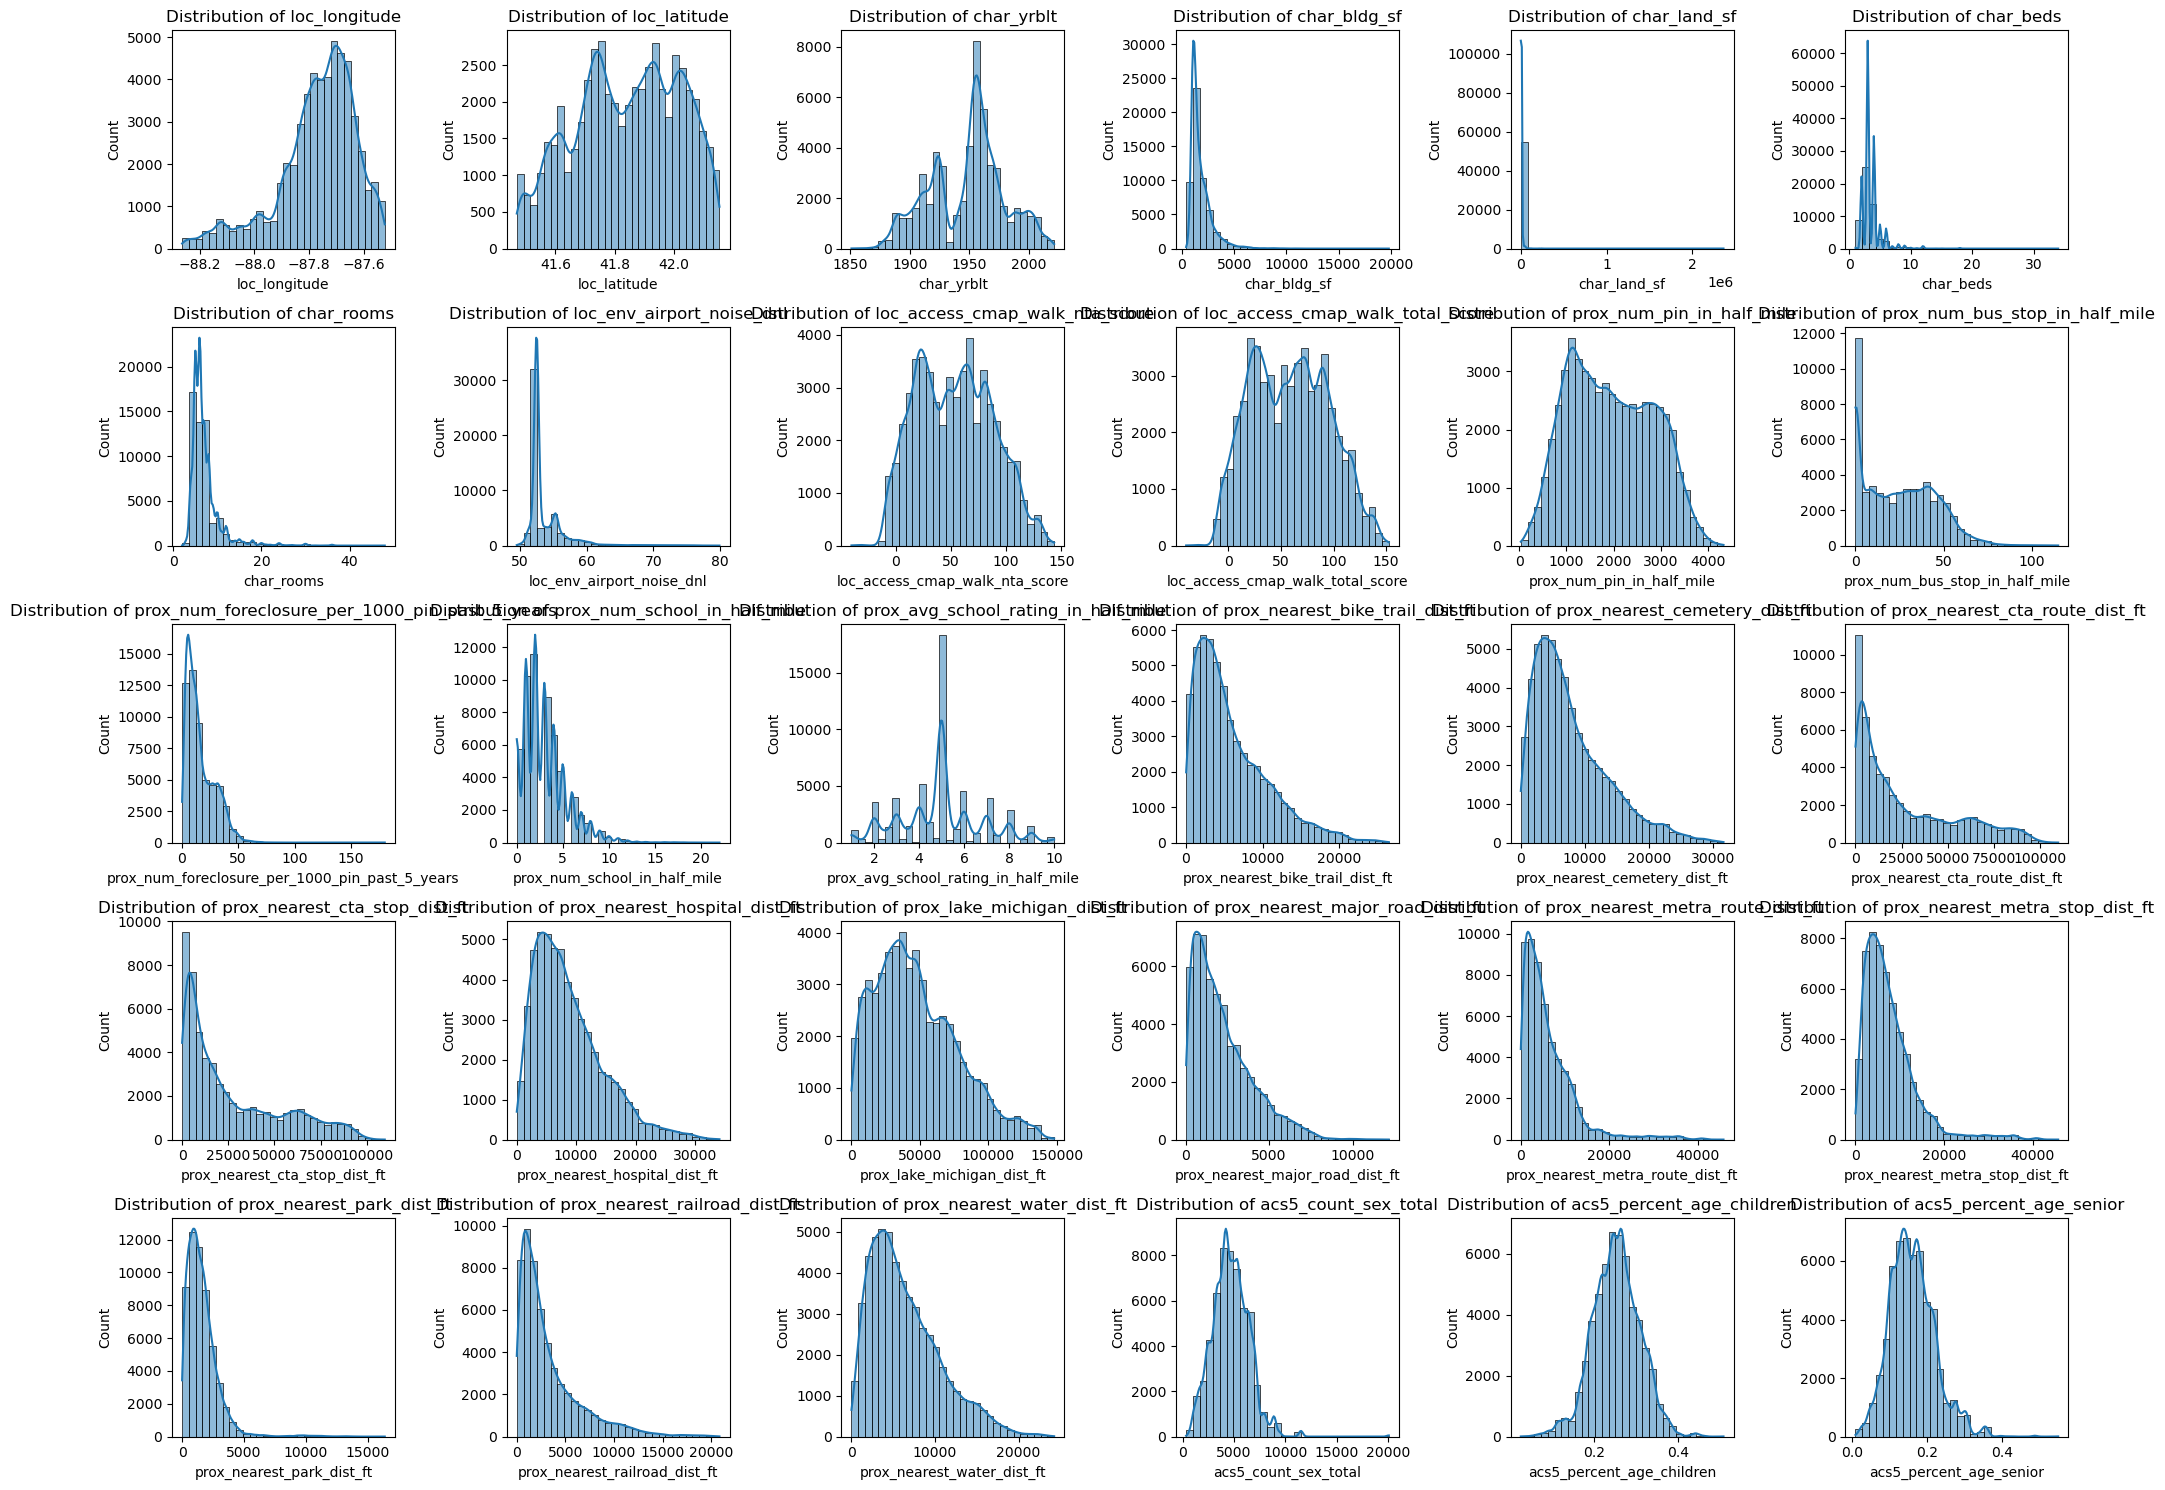

In [ ]:
# histplot to make EDA
fig, axes = plt.subplots(nrows=5, ncols=6, figsize=(20, 15))
axes = axes.flatten()

for i, col in enumerate(pkg_continuous[:30]):
    sns.histplot(train_data[col], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')

plt.tight_layout()
save_figure("08_continuous_feature_distributions_part1")
plt.show()

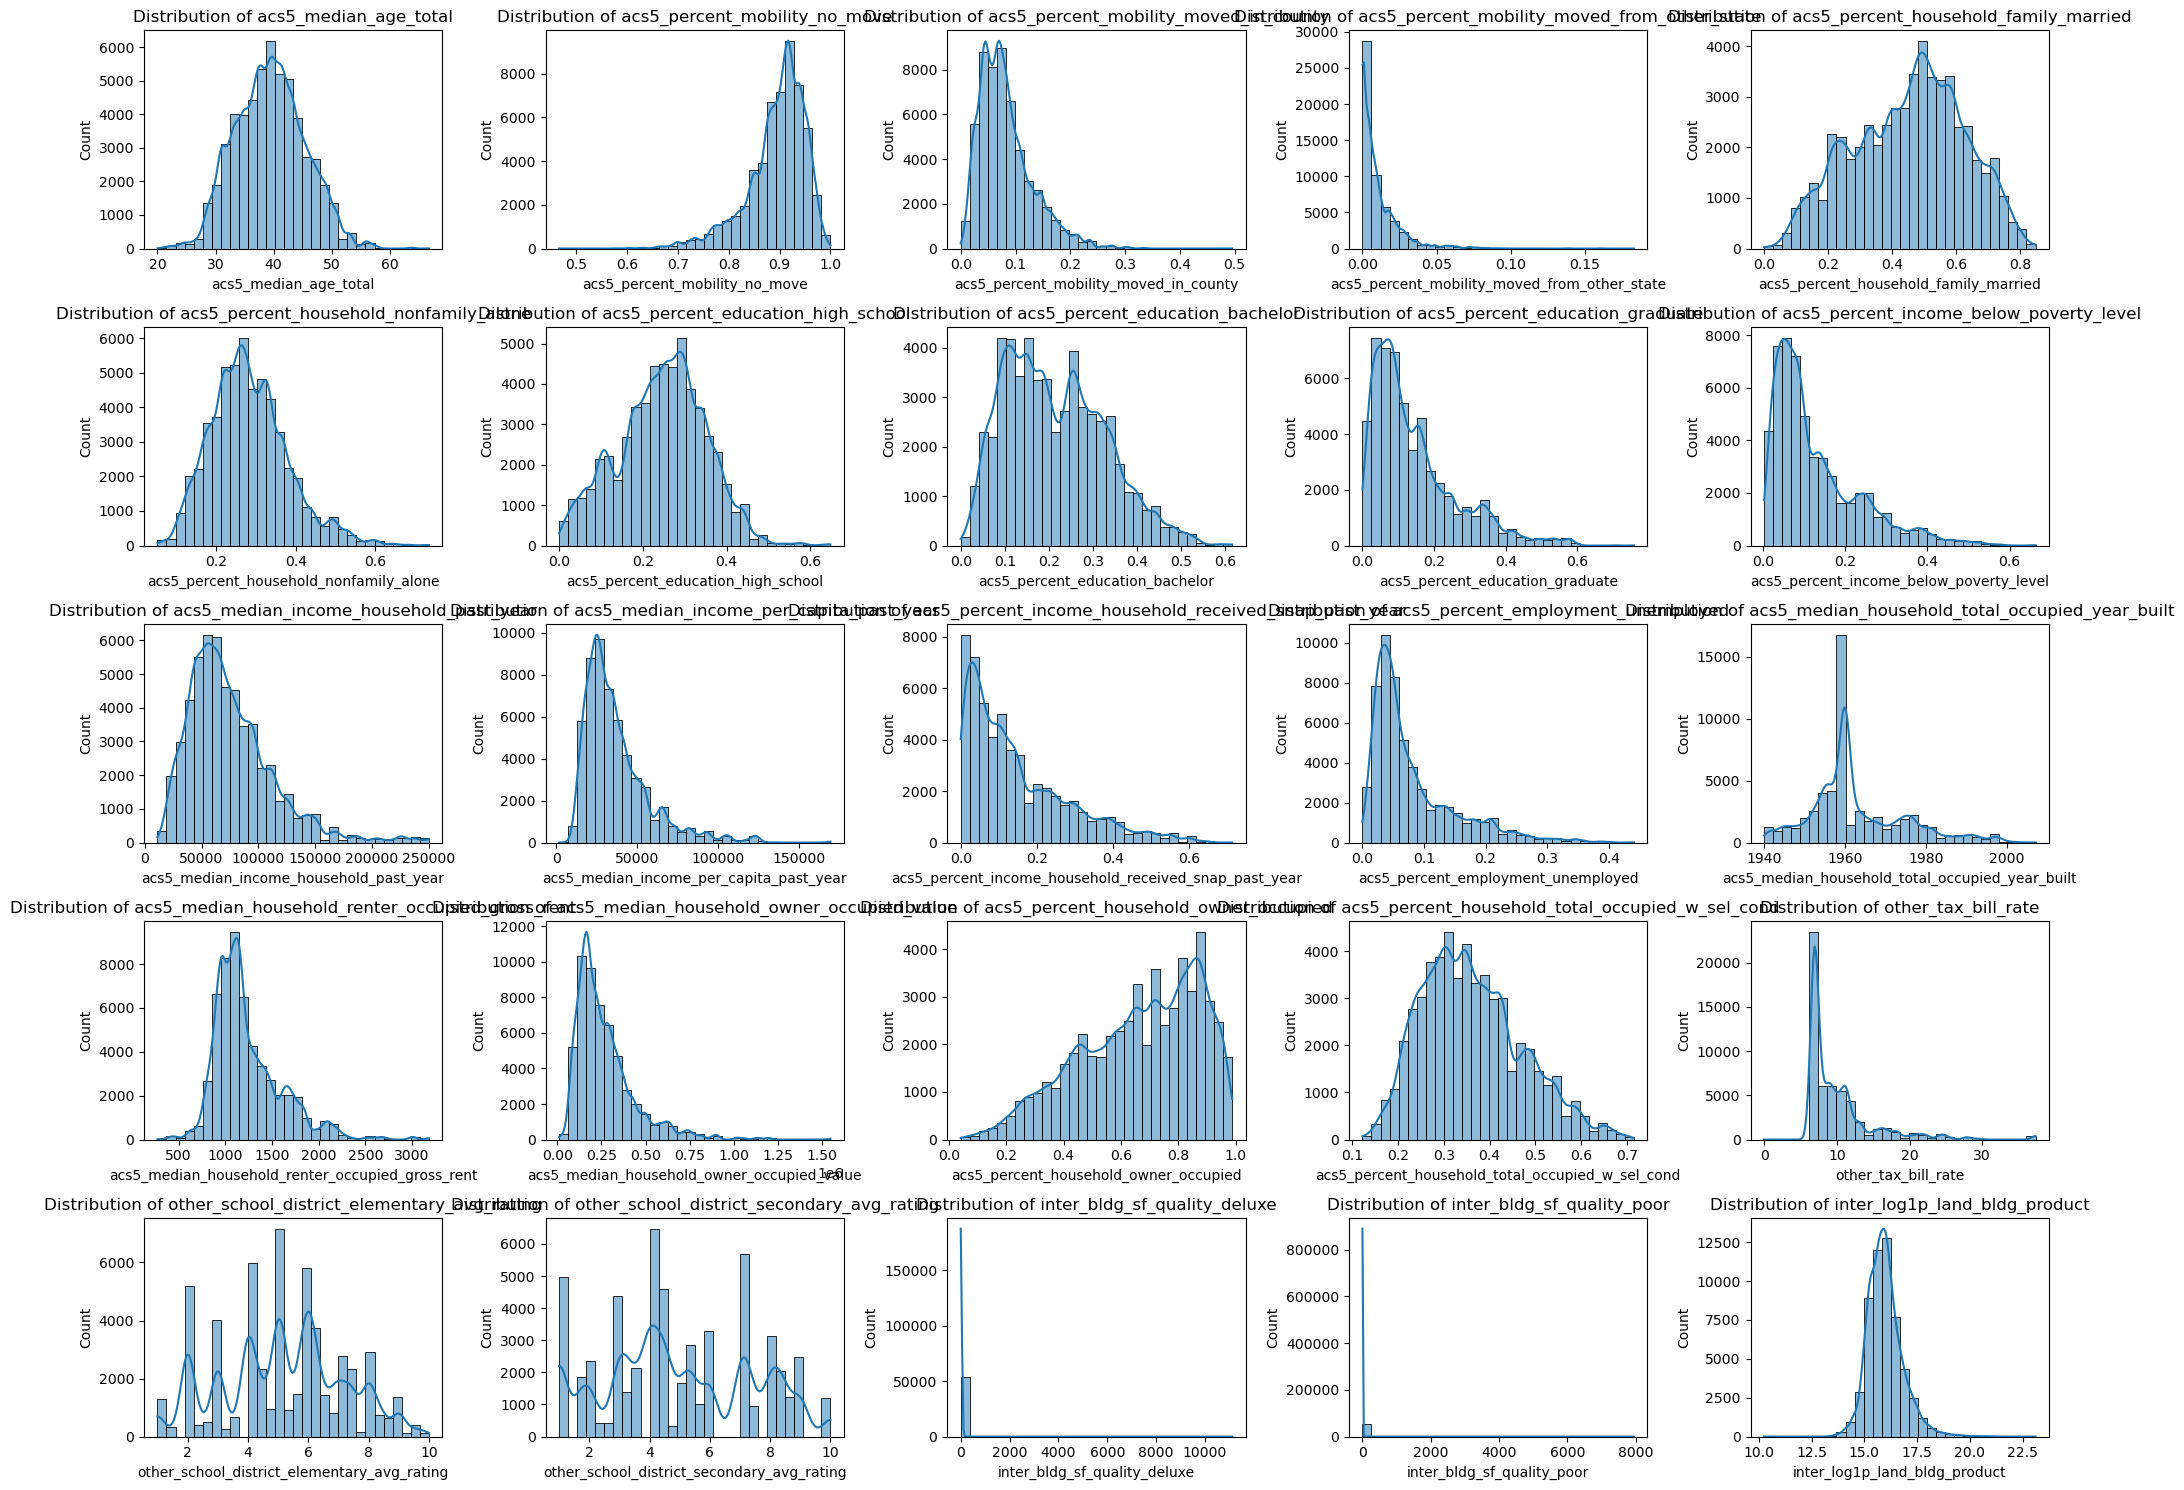

In [ ]:
remaining_continuous_features = pkg_continuous[30:]
columns_per_row = 5
row_count = max(1, int(np.ceil(len(remaining_continuous_features) / columns_per_row)))
fig, axes = plt.subplots(
    nrows=row_count,
    ncols=columns_per_row,
    figsize=(20, 3 * row_count),
)
axes = np.atleast_1d(axes).flatten()

for axis, column in zip(axes, remaining_continuous_features):
    sns.histplot(train_data[column], bins=30, kde=True, ax=axis)
    axis.set_title(f"Distribution of {column}")

for unused_axis in axes[len(remaining_continuous_features):]:
    unused_axis.set_visible(False)

plt.tight_layout()
save_figure("09_continuous_feature_distributions_part2")
plt.show()


In [ ]:
def generate_continuous_outlier_report(df, lower_q=0.01, upper_q=0.99):
    """
    生成连续特征异常值检查的汇总报告 DataFrame
    """
    report_data = []

    for col in df.columns:
        series = df[col].dropna()
        if len(series) == 0:
            continue

        lower_bound = series.quantile(lower_q)
        upper_bound = series.quantile(upper_q)

        below_values = series[series < lower_bound]
        above_values = series[series > upper_bound]

        report_data.append({
            'Feature': col,
            'Valid_Count': len(series),
            'Min_Value': round(series.min(), 4),
            'Max_Value': round(series.max(), 4),
            '1%_Lower_Bound': round(lower_bound, 4),
            '99%_Upper_Bound': round(upper_bound, 4),
            'Count_Below_1%': len(below_values),
            'Count_Above_99%': len(above_values),
            'Total_Outliers': len(below_values) + len(above_values),
            'Outlier_Ratio(%)': round((len(below_values) + len(above_values)) / len(series) * 100, 2),
            # 提取前 3 个最极端的值作为参考
            'Top3_Min_Samples': np.sort(below_values)[:3].tolist(),
            'Top3_Max_Samples': np.sort(above_values)[::-1][:3].tolist()
        })

    return pd.DataFrame(report_data)

# === 使用示例 ===
report_df = generate_continuous_outlier_report(df_continuous)
display(report_df)
report_df.to_csv("continuous_outlier_report.csv", index=False) # 导出查看

,Feature,Valid_Count,Min_Value,Max_Value,1%_Lower_Bound,99%_Upper_Bound,Count_Below_1%,Count_Above_99%,Total_Outliers,Outlier_Ratio(%),Top3_Min_Samples,Top3_Max_Samples
0,loc_longitude,54853,-88.2635,-8.752490e+01,-88.2075,-87.5368,549,549,1098,2.00,"[-88.26350610075501, -88.26333689363103, -88.2631566263013]","[-87.52491910282046, -87.52491910282046, -87.52492250946459]"
1,loc_latitude,54853,41.4699,4.215400e+01,41.4822,42.1407,549,549,1098,2.00,"[41.46992834851476, 41.46997659345463, 41.46998370028336]","[42.15397901114071, 42.15395661600107, 42.15394950860588]"
2,char_yrblt,54853,1851.0000,2.021000e+03,1883.0000,2014.0000,493,433,926,1.69,"[1851.0, 1851.0, 1852.0]","[2021.0, 2021.0, 2021.0]"
3,char_bldg_sf,54853,400.0000,1.980000e+04,720.0000,5880.0000,516,543,1059,1.93,"[400.0, 400.0, 400.0]","[19800.0, 19575.0, 15300.0]"
4,char_land_sf,54853,9.0000,2.363130e+06,1097.0000,38826.8800,548,549,1097,2.00,"[9.0, 358.0, 488.0]","[2363130.0, 2363130.0, 653400.0]"
5,char_beds,54853,1.0000,3.400000e+01,2.0000,10.0000,96,465,561,1.02,"[1.0, 1.0, 1.0]","[34.0, 34.0, 22.0]"
6,char_rooms,54853,2.0000,4.800000e+01,4.0000,22.0000,338,499,837,1.53,"[2.0, 2.0, 3.0]","[48.0, 48.0, 46.0]"
7,loc_env_airport_noise_dnl,54853,49.5349,7.989810e+01,50.8998,67.2733,549,549,1098,2.00,"[49.53487396240234, 49.53657531738281, 49.53836441040039]","[79.89813232421875, 79.78201293945312, 79.42108154296875]"
8,loc_access_cmap_walk_nta_score,54853,-40.0000,1.435000e+02,-7.0000,130.0000,536,442,978,1.78,"[-40.0, -40.0, -40.0]","[143.5, 143.5, 143.5]"
9,loc_access_cmap_walk_total_score,54853,-40.0000,1.525000e+02,-7.0000,138.5000,484,414,898,1.64,"[-40.0, -40.0, -38.0]","[152.5, 152.5, 152.5]"


我们对continuous的数据进行outlier的列示，找出其中极端值与1%和99%分位数值偏离极大的feature进行outlier截断。但对于特殊feature例如时间类的，则不做处理


In [ ]:
# 验证loc_access_cmap_walk_nta_score的负值是否有多数为-40的极端情况而代表了不合理的缺失值
print("值小于 -7 的样本数:", (train_data['loc_access_cmap_walk_nta_score'] < -7).sum())
print("值等于 -40 的样本数:", (train_data['loc_access_cmap_walk_nta_score'] == -40).sum())
print("小于 0 但大于 -40 的样本数:", ((train_data['loc_access_cmap_walk_nta_score'] < 0) & (train_data['loc_access_cmap_walk_nta_score'] > -40.0)).sum())

值小于 -7 的样本数: 536
值等于 -40 的样本数: 3
小于 0 但大于 -40 的样本数: 2183


In [ ]:
# 验证other_tax_bill_rate的负值是否有多数为-40的极端情况而代表了不合理的缺失值
print("值小于 6 的样本数:", (train_data['other_tax_bill_rate'] < 6).sum())
print("值等于 0 的样本数:", (train_data['other_tax_bill_rate'] == 0).sum())
print("小于 6 但大于 0 的样本数:", ((train_data['other_tax_bill_rate'] < 6) & (train_data['other_tax_bill_rate'] > 0)).sum())

值小于 6 的样本数: 4
值等于 0 的样本数: 3
小于 6 但大于 0 的样本数: 1



通过分析上面的直方图、极端值，结合实际场景，我们配置额外的csv文件，在其中列示了不同feature所归类的特征工程处理方式，来进行统一转换

In [ ]:
from sklearn.preprocessing import PowerTransformer, StandardScaler

rule_df = pd.read_csv('data/featureengineer.csv')

# 将各列去除空格并过滤掉空值、转换为列表。这里去重以应对拼写重复。
def get_cols(col_name):
    if col_name not in rule_df.columns:
        return []
    # dropna() 去除空值，astype(str).str.strip() 去除空格，unique() 去重
    return rule_df[col_name].dropna().astype(str).str.strip().unique().tolist()

# 因为 'yeojohnson' 和 'standardscaler' 列的名字如果与代码有冲突，直接用列名提取
cols_yeojohnson = get_cols('yeojohnson')
cols_scaler = get_cols('standardscaler')
cols_clipping = get_cols('clipping')
cols_binning = get_cols('binning')
cols_remain = get_cols('remain')

# 考虑到处理顺序①②③要求对“所有涉及 clipping/yeojohnson/scaler”的特征一视同仁，
# 我们取这三者的并集作为需要连续处理的列（正如之前的逻辑）。
# 注意过滤掉不在 train_data 中的特征。
continuous_cols = list(set(cols_yeojohnson + cols_scaler + cols_clipping))
continuous_cols = [c for c in continuous_cols if c in train_data.columns]

print(f"解析结果：")
print(f"连续处理组(①②③)特征数: {len(continuous_cols)}")
print(f"分箱组(④)特征数: {len(cols_binning)}")
print(f"保持不变(⑤)特征数: {len(cols_remain)}")


# ==========================================
# 1. 连续特征：① Clipping -> ② Yeo-Johnson -> ③ StandardScaler
# ==========================================
print("\n开始处理连续型特征...")

# ① 计算训练集的 1% 和 99% 分位数（防止数据泄露，必须在训练集上计算）
clip_bounds = {}
for col in continuous_cols:
    lower = train_data[col].quantile(0.01)
    upper = train_data[col].quantile(0.99)
    clip_bounds[col] = (lower, upper)

# ② 提取并 Clip 训练集，用于 Fit PowerTransformer 和 StandardScaler
train_clipped = train_data[continuous_cols].copy()
for col in continuous_cols:
    lower, upper = clip_bounds[col]
    train_clipped[col] = train_clipped[col].clip(lower, upper)

# Fit 转换器
pt = PowerTransformer(method='yeo-johnson')
scaler = StandardScaler()

train_pt = pt.fit_transform(train_clipped)
scaler.fit(train_pt)

# 应用到三个数据集
for df in [train_data, val_data, test_data]:
    df_clipped = df[continuous_cols].copy()

    # 执行 Clipping
    for col in continuous_cols:
        lower, upper = clip_bounds[col]
        df_clipped[col] = df_clipped[col].clip(lower, upper)

    # 执行 Yeo-Johnson
    df_pt = pt.transform(df_clipped)

    # 执行 StandardScaler
    df_scaled = scaler.transform(df_pt)

    # 覆盖回原数据
    df[continuous_cols] = df_scaled

print("✅ 连续特征处理完成！")

解析结果：
连续处理组(①②③)特征数: 44
分箱组(④)特征数: 6
保持不变(⑤)特征数: 2

开始处理连续型特征...


C:\ana\envs\qbus6810\lib\site-packages\sklearn\preprocessing\_data.py:3253: RuntimeWarning: divide by zero encountered in log
  loglike = -n_samples / 2 * np.log(x_trans.var())


✅ 连续特征处理完成！


In [ ]:
print("\n开始处理分箱特征...")

# 分箱逻辑函数
def apply_binning(df, binning_list):
    df_bin = df.copy()

    if 'char_beds' in binning_list and 'char_beds' in df_bin.columns:
        # 1卧、2卧、3卧、4卧、5卧及以上 (共计5个标签)
        df_bin['char_beds_bin'] = df_bin['char_beds'].clip(lower=1, upper=5).fillna(1).astype(int)

    if 'char_rooms' in binning_list and 'char_rooms' in df_bin.columns:
        # 0-9间，10间及以上 (共计11个标签)
        df_bin['char_rooms_bin'] = df_bin['char_rooms'].clip(lower=0, upper=10).fillna(0).astype(int)

    if 'prox_num_school_in_half_mile' in binning_list and 'prox_num_school_in_half_mile' in df_bin.columns:
        # 0-9间，10间及以上 (共计11个标签)
        df_bin['prox_num_school_bin'] = df_bin['prox_num_school_in_half_mile'].clip(lower=0, upper=10).fillna(0).astype(int)

    if 'prox_avg_school_rating_in_half_mile' in binning_list and 'prox_avg_school_rating_in_half_mile' in df_bin.columns:
        # 四舍五入，1-10，10个标签
        rounded = df_bin['prox_avg_school_rating_in_half_mile'].round()
        df_bin['prox_avg_school_rating_bin'] = rounded.clip(lower=1, upper=10).fillna(1).astype(int)

    if 'other_school_district_elementary_avg_rating' in binning_list and 'other_school_district_elementary_avg_rating' in df_bin.columns:
        # 四舍五入，1-10，10个标签
        rounded = df_bin['other_school_district_elementary_avg_rating'].round()
        df_bin['other_elementary_rating_bin'] = rounded.clip(lower=1, upper=10).fillna(1).astype(int)

    if 'other_school_district_secondary_avg_rating' in binning_list and 'other_school_district_secondary_avg_rating' in df_bin.columns:
        # 四舍五入，1-10，10个标签
        rounded = df_bin['other_school_district_secondary_avg_rating'].round()
        df_bin['other_secondary_rating_bin'] = rounded.clip(lower=1, upper=10).fillna(1).astype(int)

    return df_bin

# 应用分箱
train_data = apply_binning(train_data, cols_binning)
val_data = apply_binning(val_data, cols_binning)
test_data = apply_binning(test_data, cols_binning)

# 找出新生成的分箱列名
bin_col_names = [
    'char_beds_bin', 'char_rooms_bin', 'prox_num_school_bin',
    'prox_avg_school_rating_bin', 'other_elementary_rating_bin', 'other_secondary_rating_bin'
]
# 过滤出真实存在的
bin_col_names = [c for c in bin_col_names if c in train_data.columns]

# 为了对齐 One-Hot 列数，先合并再做 dummies
train_len = len(train_data)
val_len = len(val_data)

combined_df = pd.concat([train_data, val_data, test_data], axis=0, ignore_index=True)

# 执行 One-Hot (drop_first=True 去掉每个特征的第一个类别作为基准)
combined_df = pd.get_dummies(combined_df, columns=bin_col_names, drop_first=True)

# 将布尔型 0/1 转为整数型
bool_cols = combined_df.select_dtypes(include=['bool']).columns
combined_df[bool_cols] = combined_df[bool_cols].astype(int)

# 拆回三个数据集
train_data = combined_df.iloc[:train_len].copy()
val_data = combined_df.iloc[train_len:train_len+val_len].copy()
test_data = combined_df.iloc[train_len+val_len:].copy()

# 清理原数据集中对应的原始连续分箱列
original_binning_cols = [c for c in cols_binning if c in train_data.columns]
for df in [train_data, val_data, test_data]:
    df.drop(columns=original_binning_cols, inplace=True, errors='ignore')

print(f"✅ 分箱与 One-Hot 处理完成！生成了 {len([c for c in train_data.columns if any(bc in c for bc in bin_col_names)])} 个 One-Hot 特征。")
print(f"\n最终数据维度: Train={train_data.shape}, Val={val_data.shape}, Test={test_data.shape}")


开始处理分箱特征...


✅ 分箱与 One-Hot 处理完成！生成了 49 个 One-Hot 特征。

最终数据维度: Train=(54853, 169), Val=(18132, 169), Test=(36322, 169)


对于以上数据特征中，

接下来，对discrete类别的特征包进行EDA分析，使用柱状图和箱型图

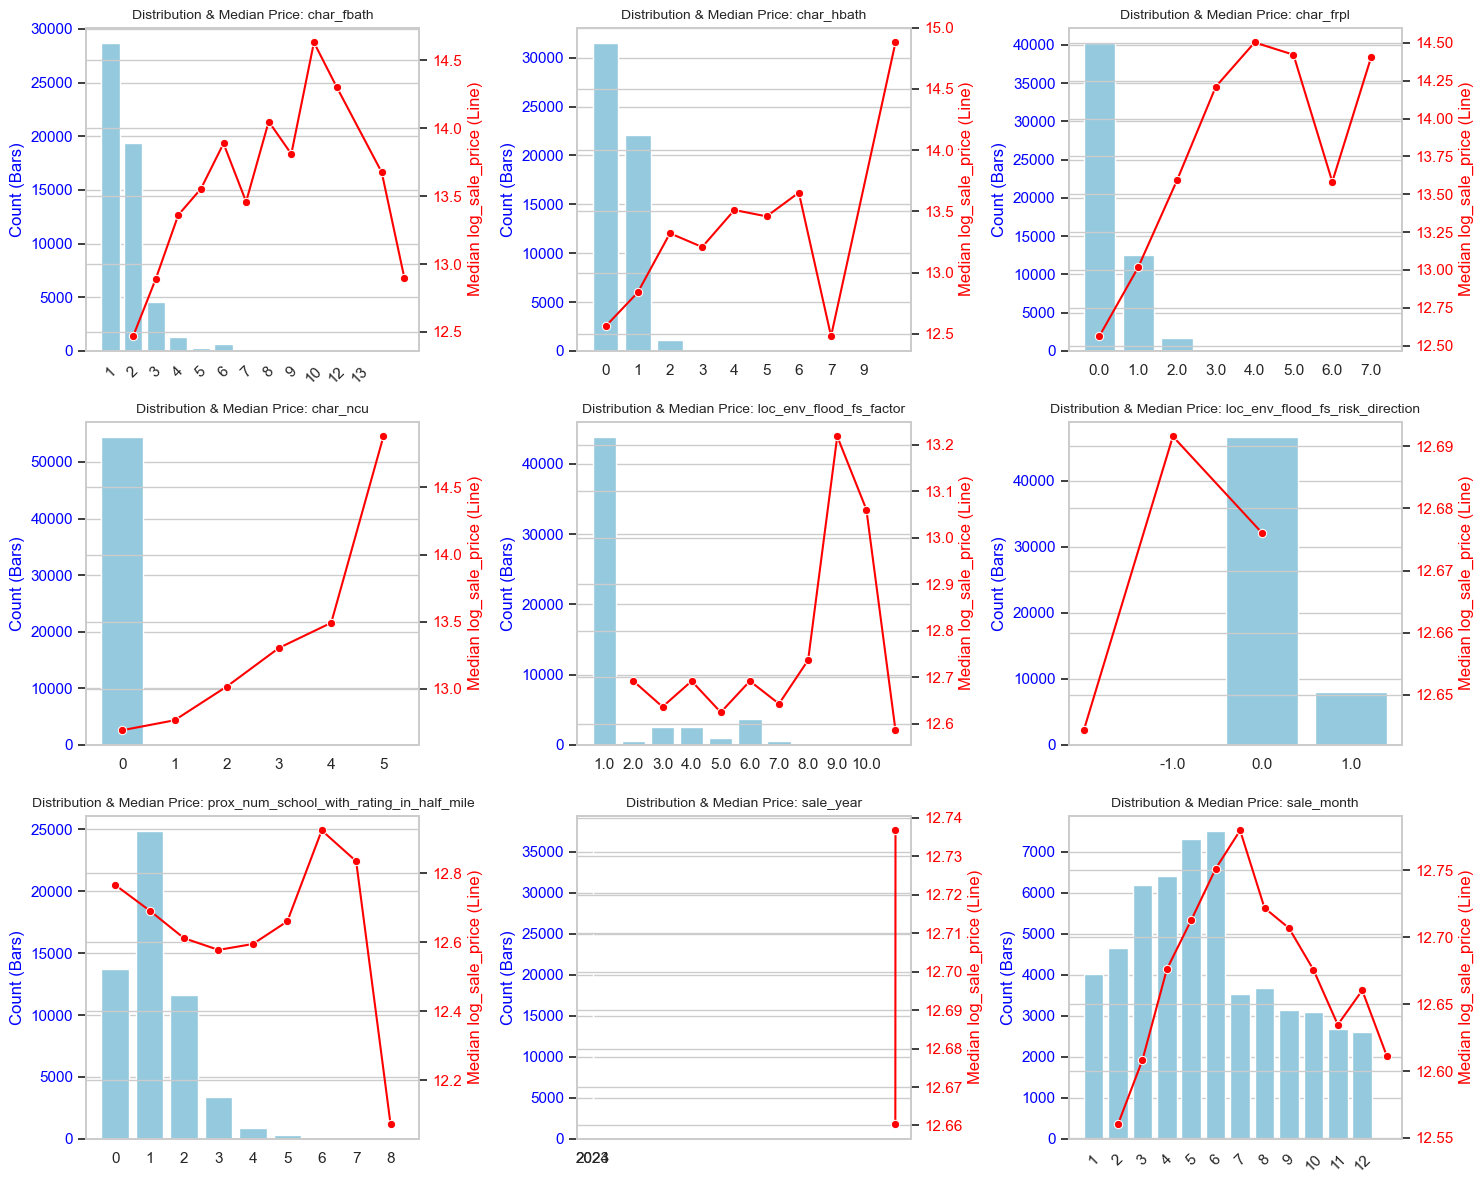

In [ ]:
sns.set_theme(style="whitegrid")

if len(pkg_discrete) > 0:
    # 计算需要的行数和列数（最多每排显示 3 个图）
    n_cols = 3
    n_rows = math.ceil(len(pkg_discrete) / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
    axes = axes.flatten()

    for i, col in enumerate(pkg_discrete):
        # 1. 画频数柱状图（使用蓝色表示频数）
        ax1 = axes[i]
        sns.countplot(data=train_data, x=col, ax=ax1, color='skyblue')

        # 2. 将双轴图放在同一个子图里（用 twinx 共享 X 轴）
        ax2 = ax1.twinx()
        # 计算该特征每个取值对应的房价中位数
        median_price = train_data.groupby(col)['log_sale_price'].median().reset_index()
        # 画折线图（使用红色圆点表示房价中位数趋势）
        sns.lineplot(data=median_price, x=col, y='log_sale_price',
                     ax=ax2, color='red', marker='o', sort=False)

        # 3. 设置标题和坐标轴
        ax1.set_title(f'Distribution & Median Price: {col}', fontsize=10)
        ax1.set_xlabel('')
        ax1.set_ylabel('Count (Bars)', color='blue')
        ax2.set_ylabel('Median log_sale_price (Line)', color='red')
        ax1.tick_params(axis='y', labelcolor='blue')
        ax2.tick_params(axis='y', labelcolor='red')

        # 优化 X 轴刻度：如果取值太多，只显示部分刻度，防止重叠
        if len(train_data[col].unique()) > 10:
            for label in ax1.get_xticklabels():
                label.set_rotation(45)

    # 隐藏多余的空子图
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    save_figure("10_discrete_features_vs_log_price")
    plt.show()
else:
    print("当前没有离散型 (Discrete) 特征。")

In [ ]:
# char_fbath: 截断极端值，保留到 3
for df in [train_data, val_data, test_data]:
    if 'char_fbath' in df.columns:
        df['char_fbath'] = df['char_fbath'].clip(upper=3).astype('Int64')

# char_hbath: 截断极端值，保留到 2
for df in [train_data, val_data, test_data]:
    if 'char_hbath' in df.columns:
        df['char_hbath'] = df['char_hbath'].clip(upper=2).astype('Int64')

# char_ncu: 截断极端值，保留到 2
for df in [train_data, val_data, test_data]:
    if 'char_ncu' in df.columns:
        df['char_ncu'] = df['char_ncu'].clip(upper=2).astype('Int64')

# prox_num_school_with_rating_in_half_mile: 截断极端值，保留到 3
for df in [train_data, val_data, test_data]:
    if 'prox_num_school_with_rating_in_half_mile' in df.columns:
        df['prox_num_school_with_rating_in_half_mile'] = df['prox_num_school_with_rating_in_half_mile'].clip(upper=3).astype('Int64')

# ==========================================
# 2. 二值化 (Binarization) —— 处理"0占绝大多数"的特征
# ==========================================

# char_frpl: 转换为是否有壁炉 (0=无, 1=有)
for df in [train_data, val_data, test_data]:
    if 'char_frpl' in df.columns:
        df['char_frpl'] = (df['char_frpl'] > 0).astype('Int64')

# ==========================================
# 3. 洪水相关特征 (保持原样，仅做类型安全性确认)
# ==========================================
# 这两个特征由于极度偏态（几乎全为0），无需改动，树模型可以直接处理
# 只要确保是 float 或 Int 即可
for df in [train_data, val_data, test_data]:
    if 'loc_env_flood_fs_factor' in df.columns:
        df['loc_env_flood_fs_factor'] = pd.to_numeric(df['loc_env_flood_fs_factor'], errors='coerce').astype('float64')
    if 'loc_env_flood_fs_risk_direction' in df.columns:
        df['loc_env_flood_fs_risk_direction'] = pd.to_numeric(df['loc_env_flood_fs_risk_direction'], errors='coerce').astype('float64')

print("✅ pkg_discrete 特征工程转换完成！")

✅ pkg_discrete 特征工程转换完成！


下面观测boolean类别的特征包，使用箱型图

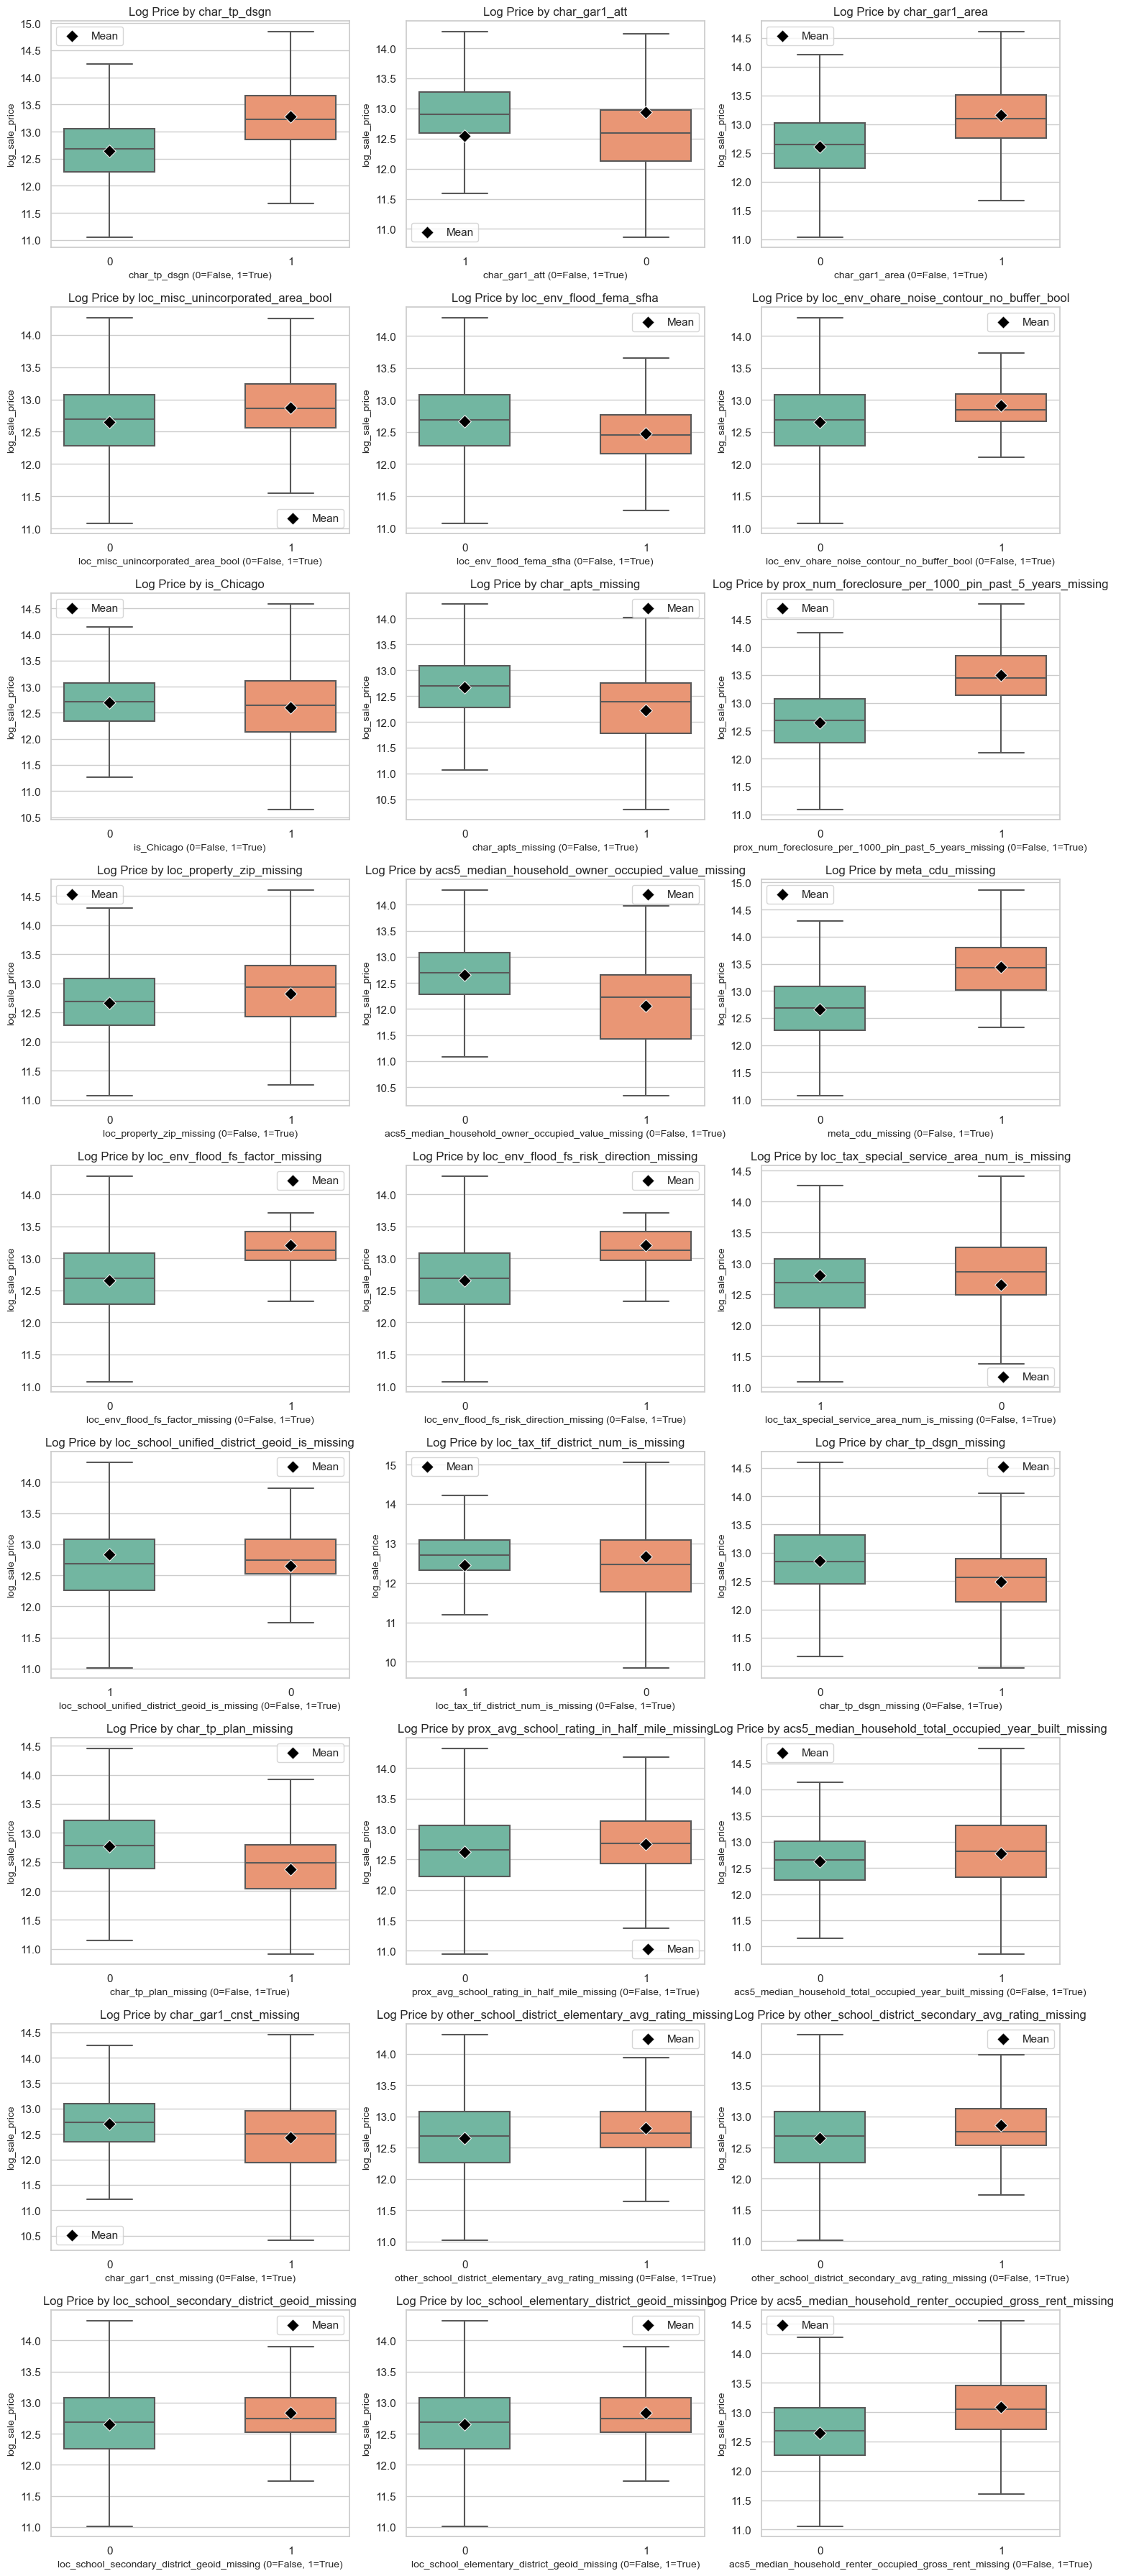

In [ ]:
if len(pkg_boolean) > 0:
    n_cols = 3
    n_rows = math.ceil(len(pkg_boolean) / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
    axes = axes.flatten()

    for i, col in enumerate(pkg_boolean):
        ax = axes[i]

        # 1. 将 Boolean 列临时转回 string 或 object 以保证 Seaborn 能正确识别为离散类别
        # 如果你的列是 category 类型，Seaborn 有时会犯傻
        plot_data = train_data[[col, 'log_sale_price']].copy()
        plot_data[col] = plot_data[col].astype(str)

        # 2. 画箱线图
        sns.boxplot(data=plot_data, x=col, y='log_sale_price', ax=ax,
                    palette="Set2", width=0.5, showfliers=False) # showfliers=False 隐藏极端异常值，让图更干净

        # 3. 计算均值
        means = plot_data.groupby(col, observed=True)['log_sale_price'].mean().reset_index()

        # 4. 画均值点（不用 pointplot，改用 scatter 画散点，绝对不报错）
        sns.scatterplot(data=means, x=col, y='log_sale_price', ax=ax,
                        color='black', marker='D', s=80, zorder=5, label='Mean')

        ax.set_title(f'Log Price by {col}', fontsize=12)
        ax.set_xlabel(f'{col} (0=False, 1=True)', fontsize=10)
        ax.set_ylabel('log_sale_price', fontsize=10)
        ax.legend(loc='best')

    # 隐藏多余的空子图
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    save_figure("11_boolean_features_vs_log_price")
    plt.show()
else:
    print("当前没有布尔型 (Boolean) 特征。")

In [ ]:
cat_dtypes = train_data[pkg_category].dtypes

# 筛出实际类型为 float 的列
float_in_cat = cat_dtypes[cat_dtypes == 'float64'].index.tolist()
# 如果包含 float32 等其他浮点型
float_in_cat = cat_dtypes[cat_dtypes.apply(lambda x: pd.api.types.is_float_dtype(x))].index.tolist()

if float_in_cat:
    print(f"⚠️ 发现 {len(float_in_cat)} 个原本属于 float 类型的列混入了 Category 包：")
    for col in float_in_cat:
        print(f"  - {col}: dtype={train_data[col].dtype}")
else:
    print("✅ pkg_category 中没有直接的 float dtype 列。")

✅ pkg_category 中没有直接的 float dtype 列。


正在生成各特征的分布与价格关系图...


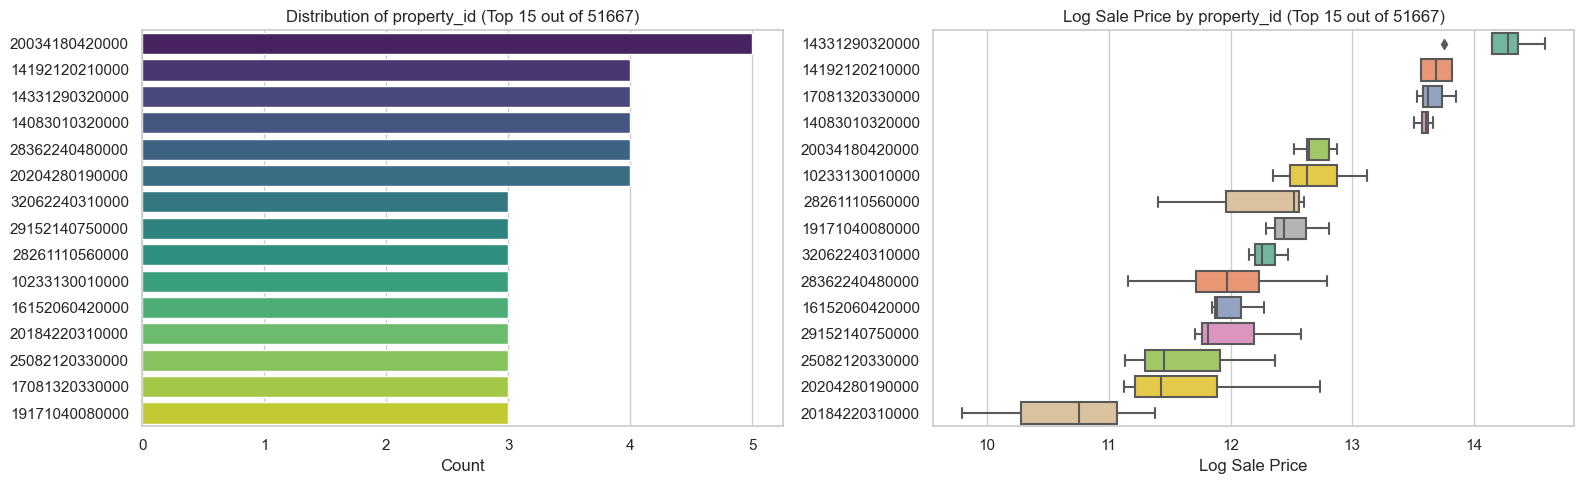

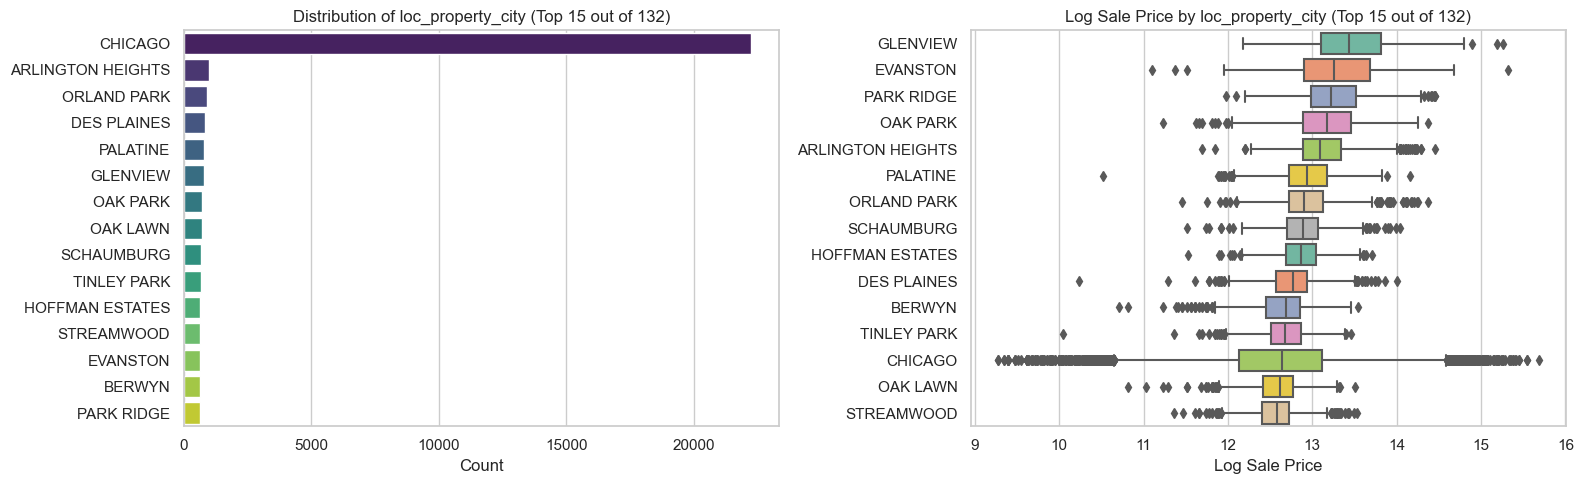

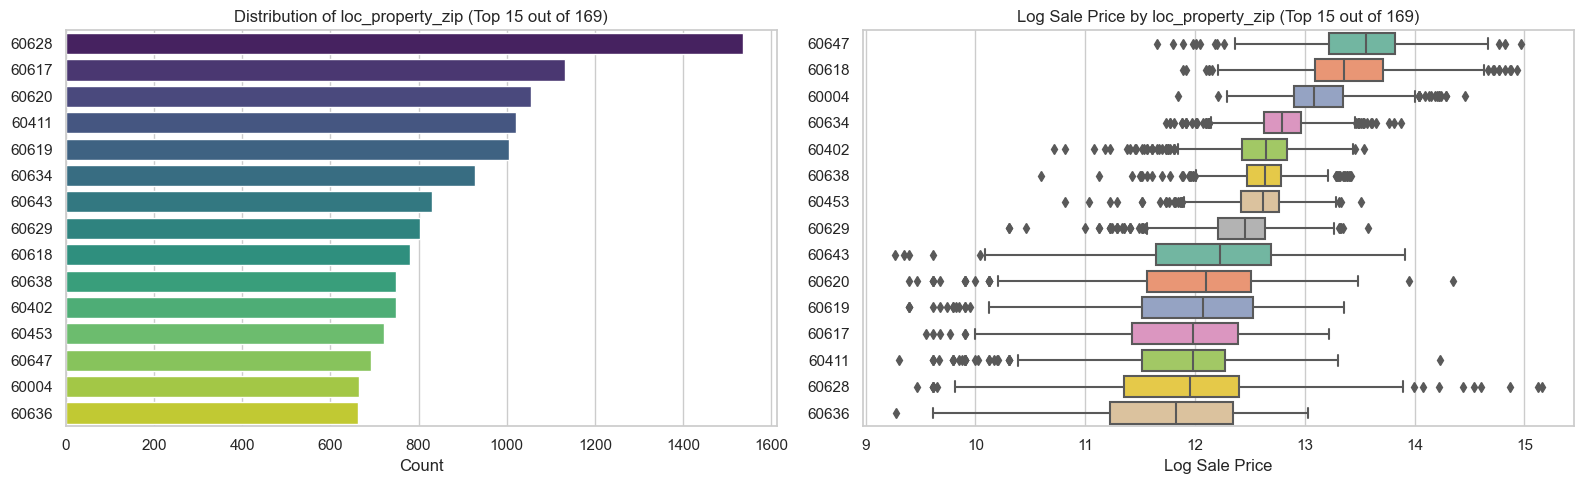

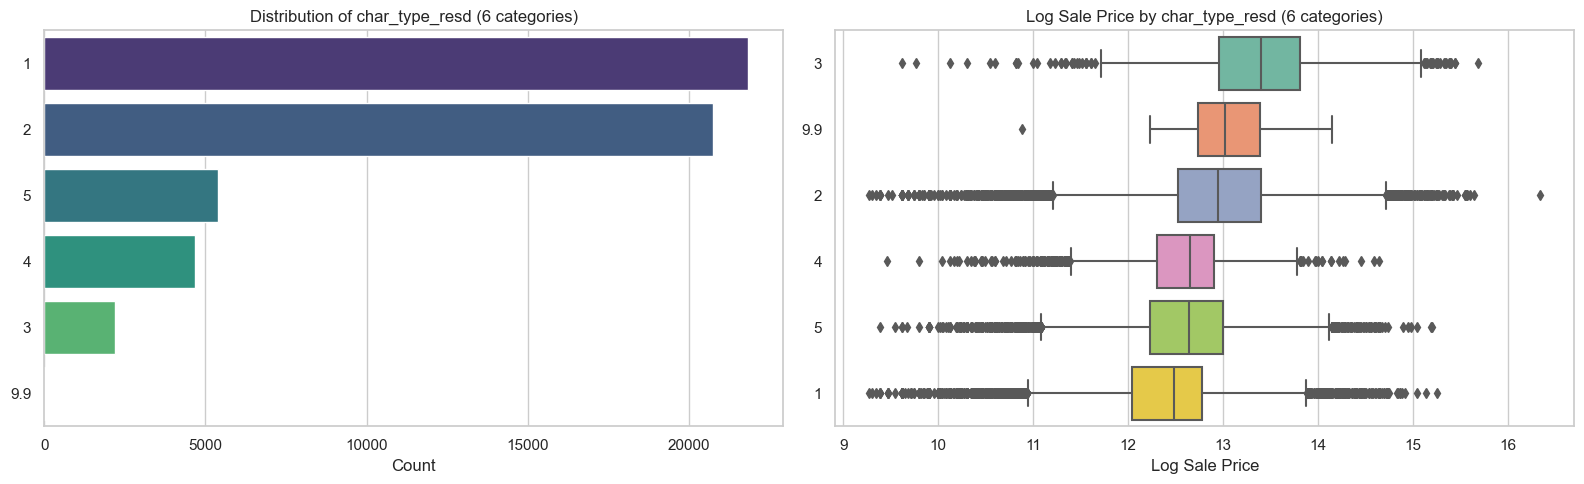

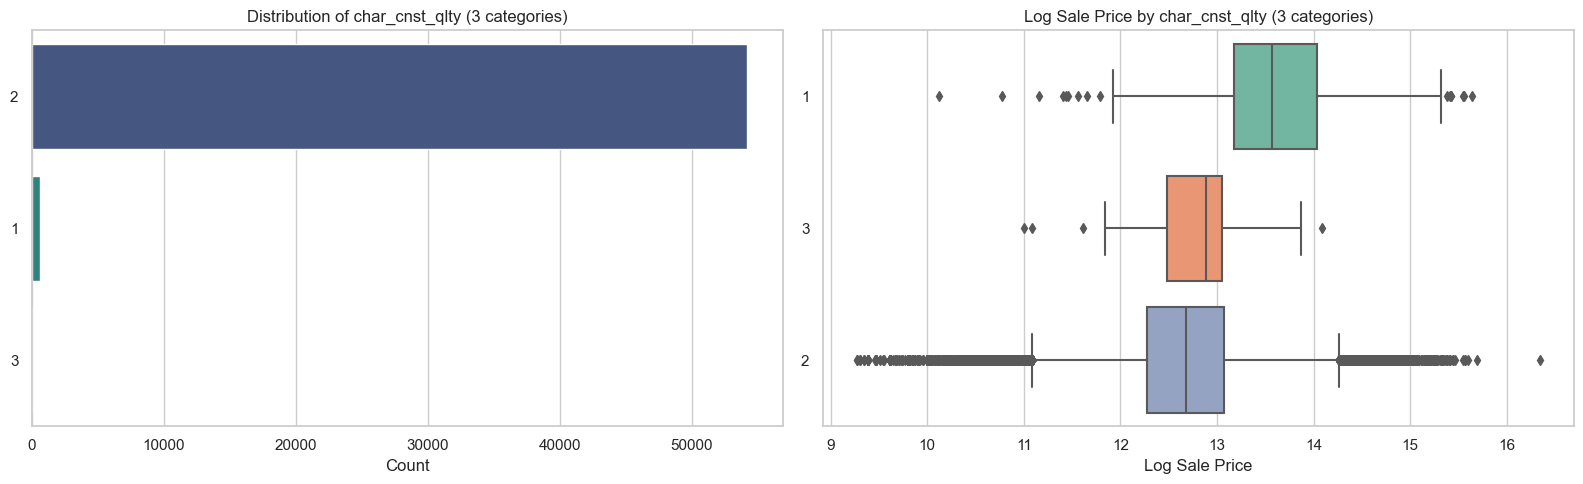

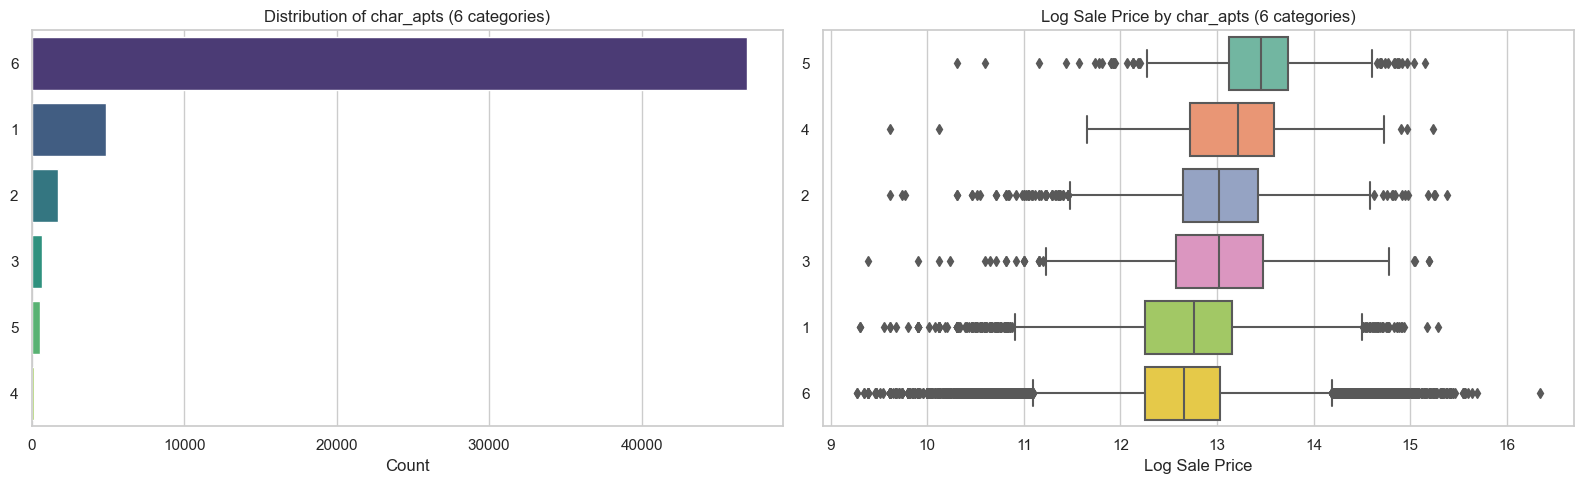

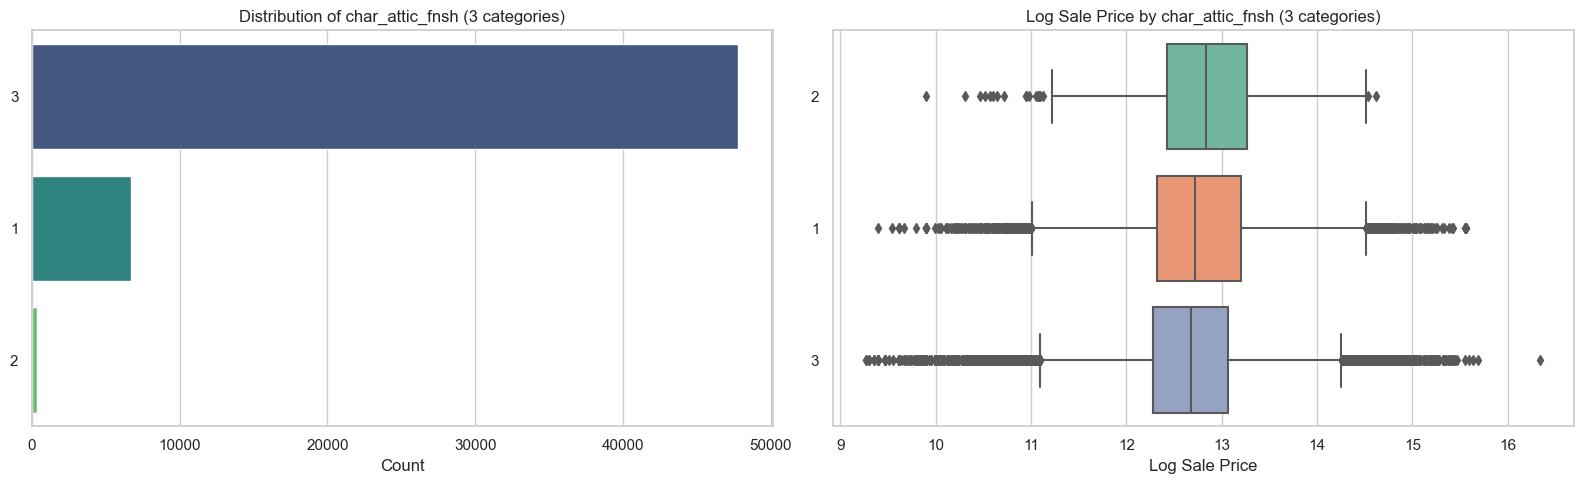

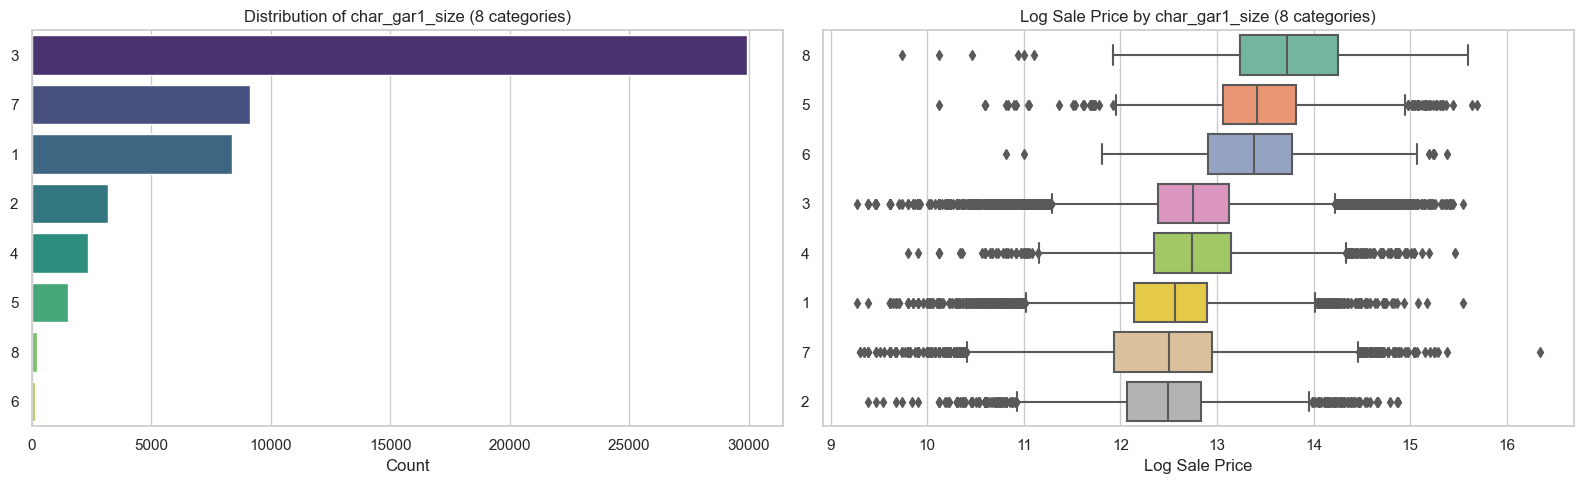

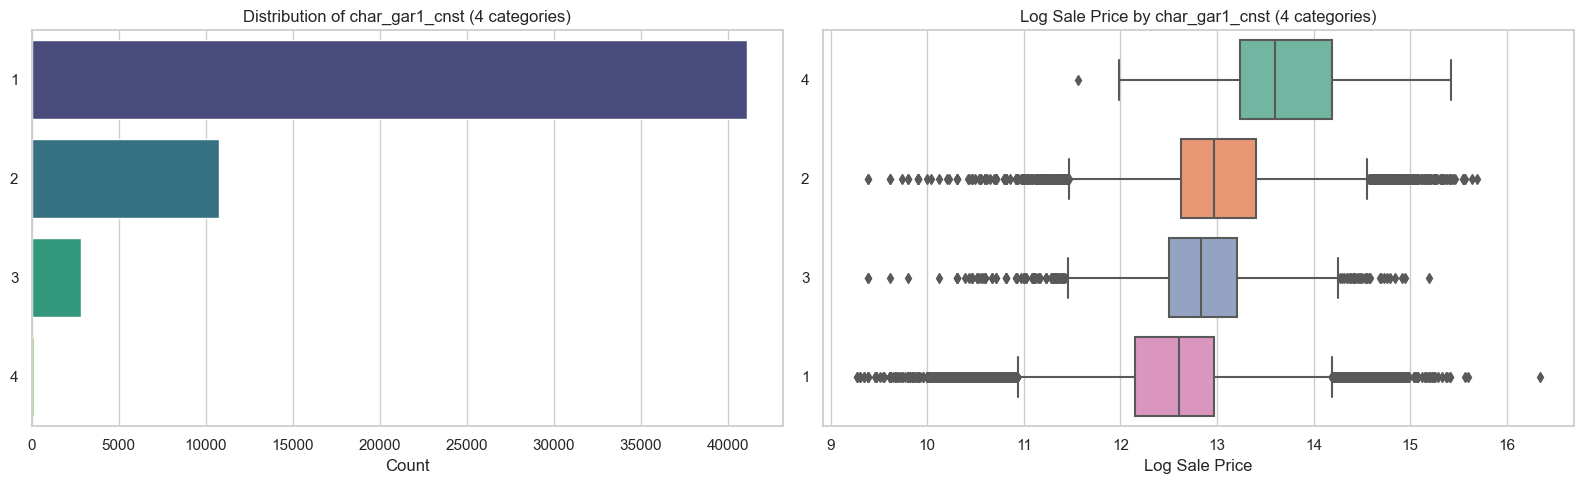

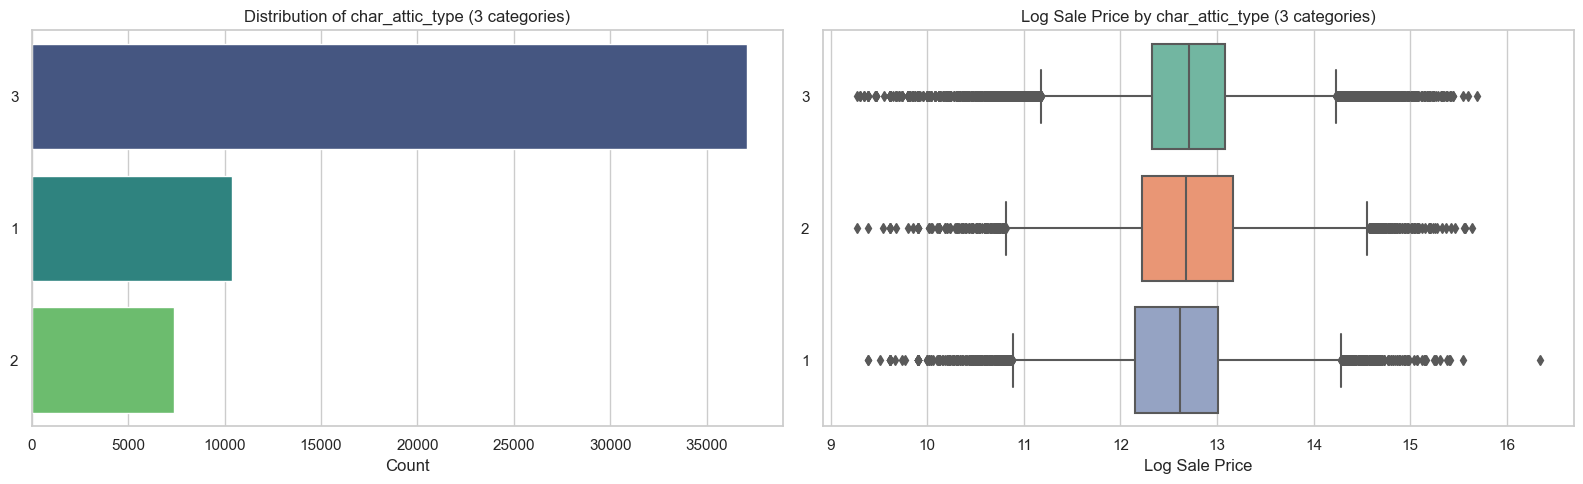

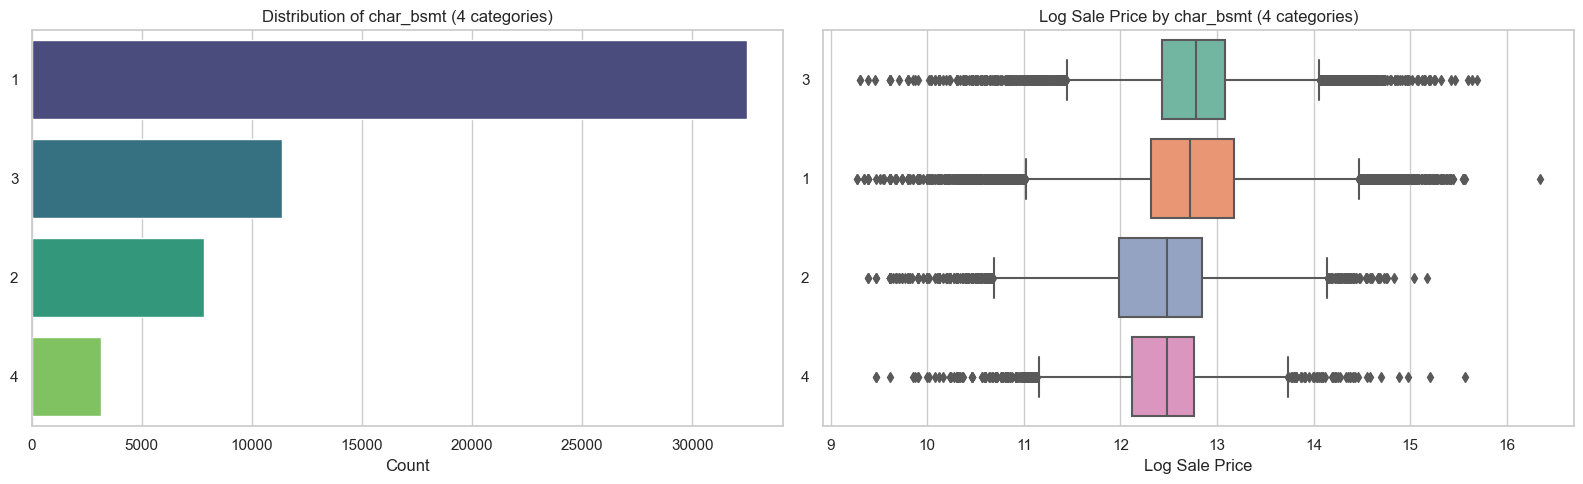

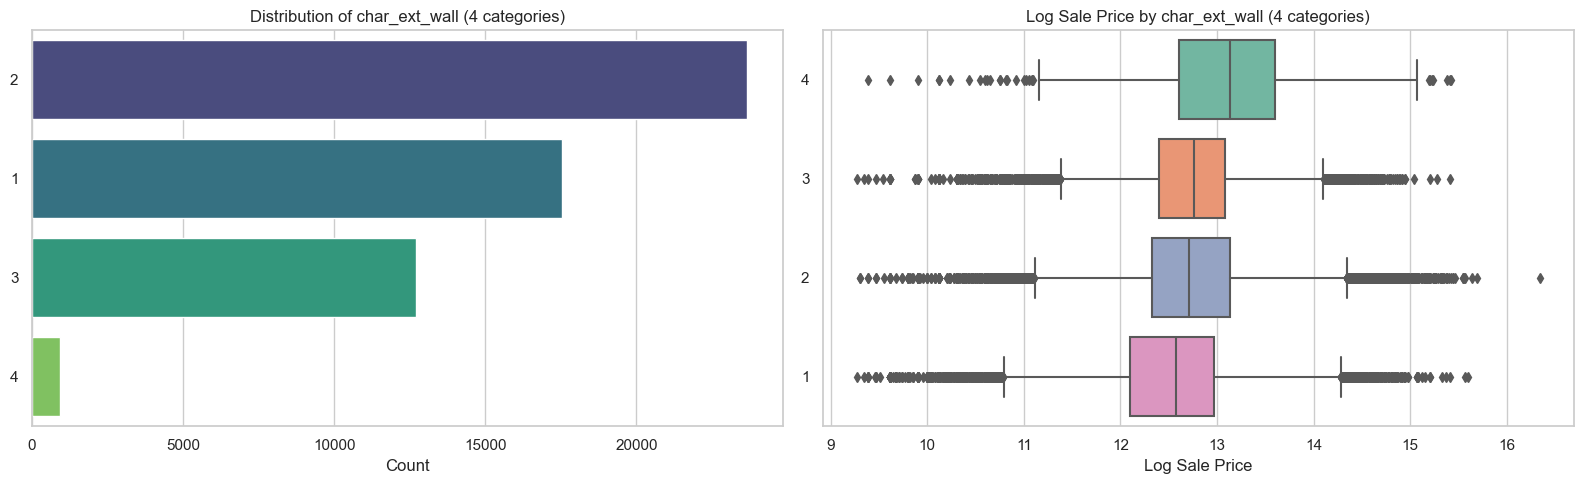

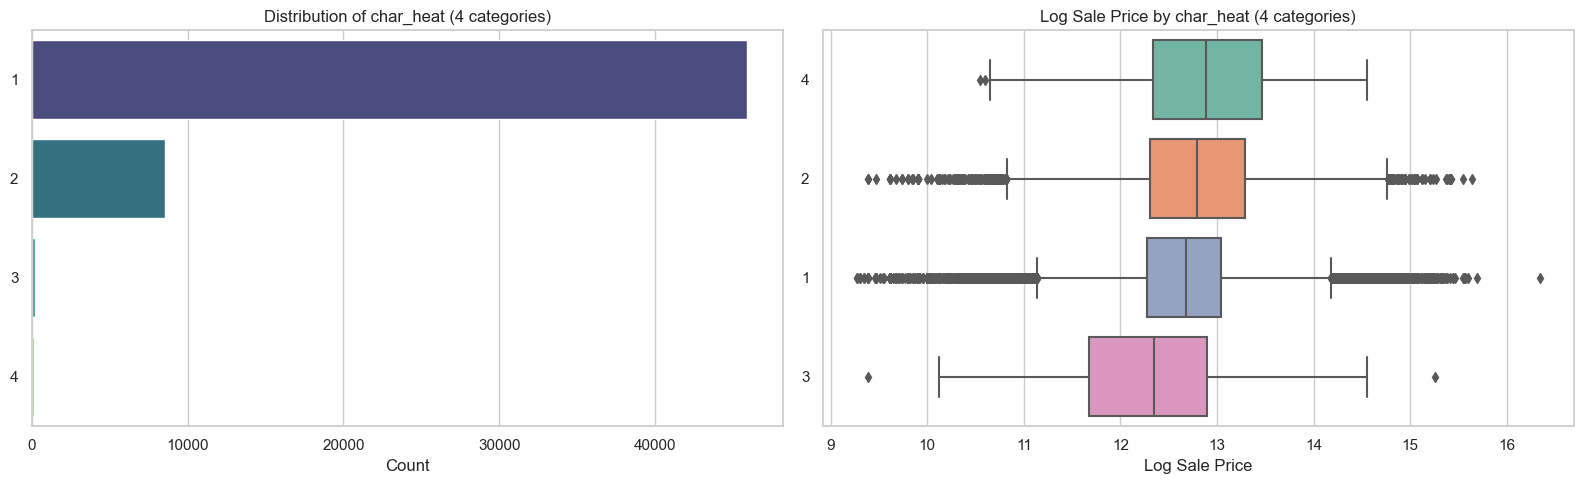

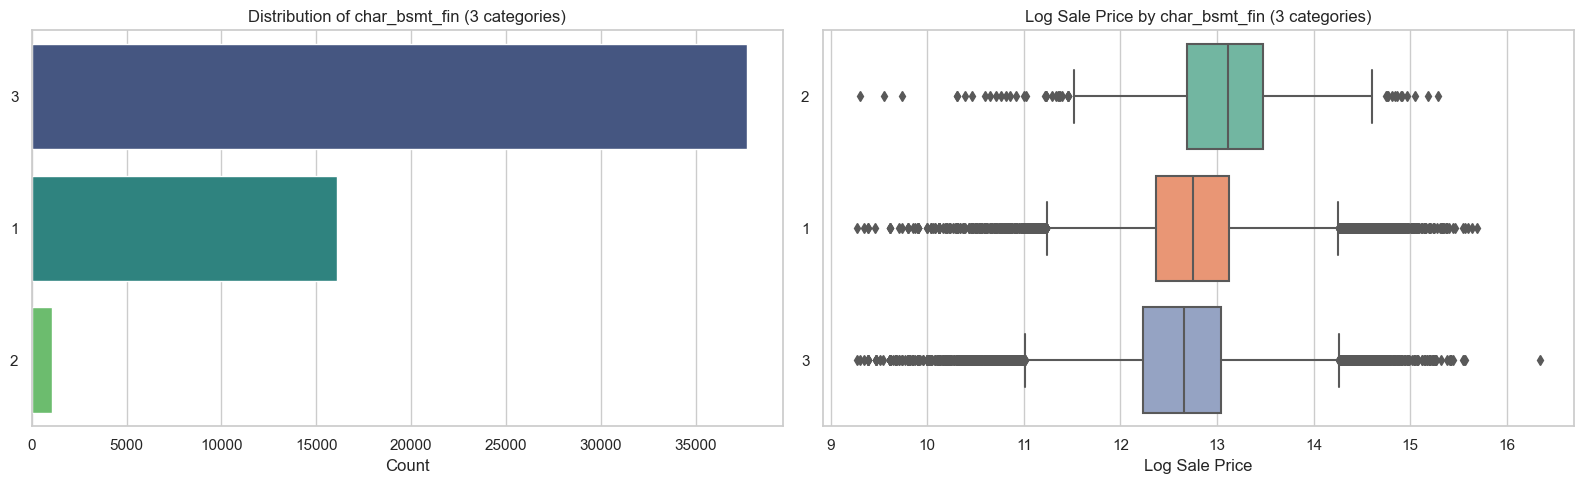

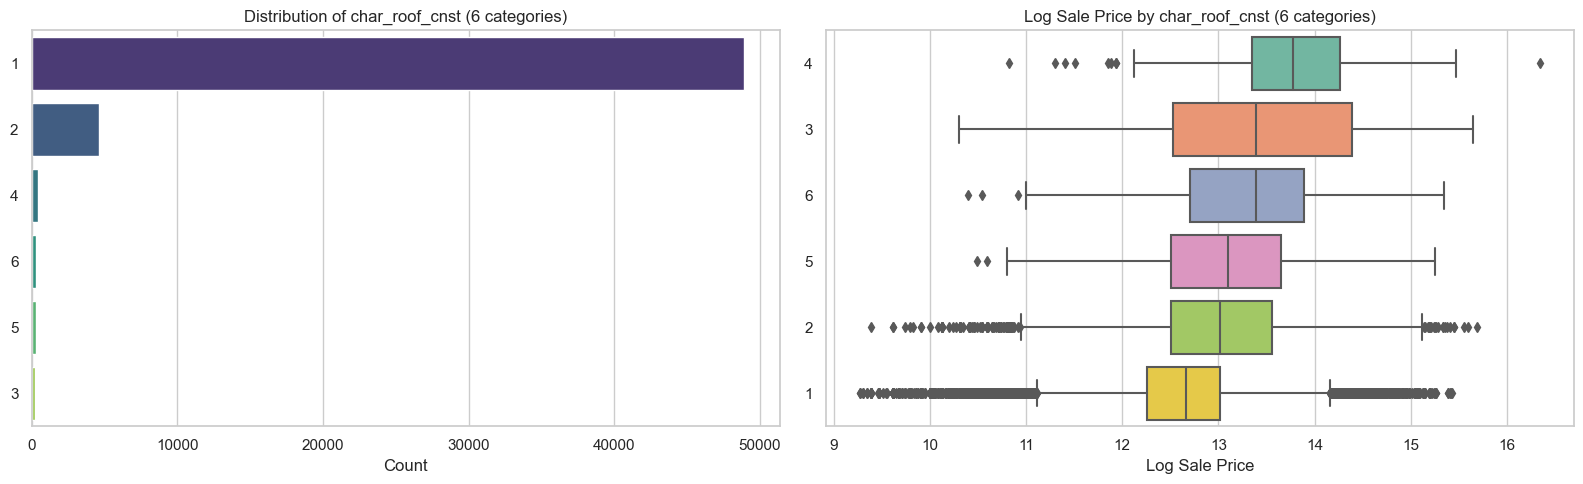

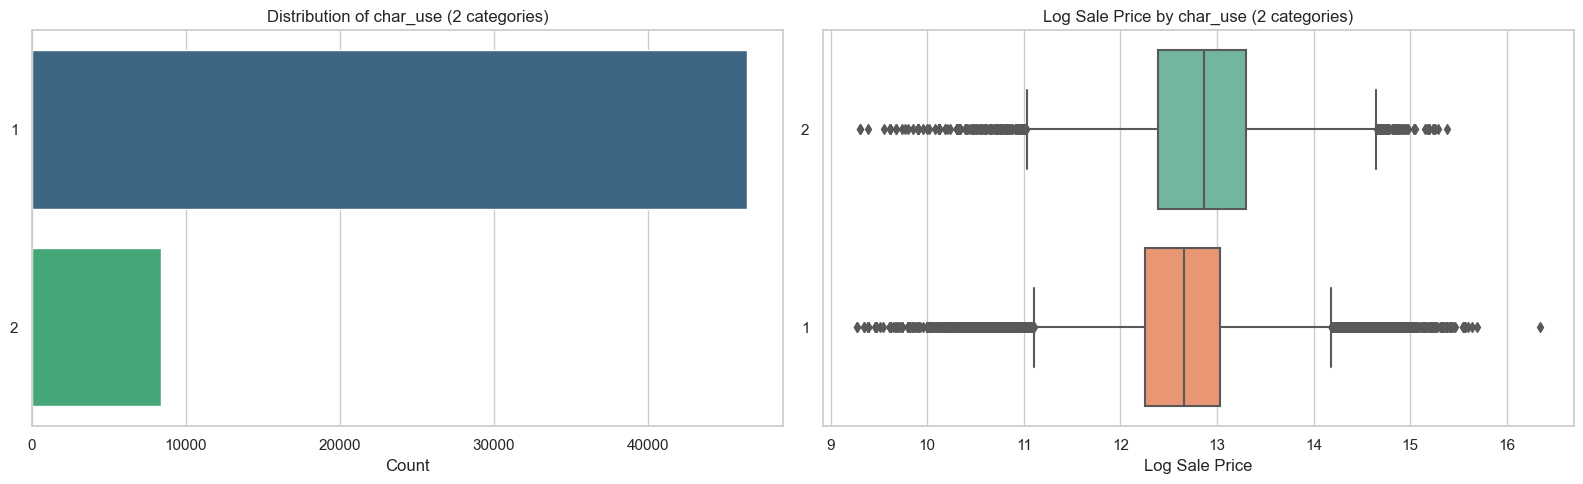

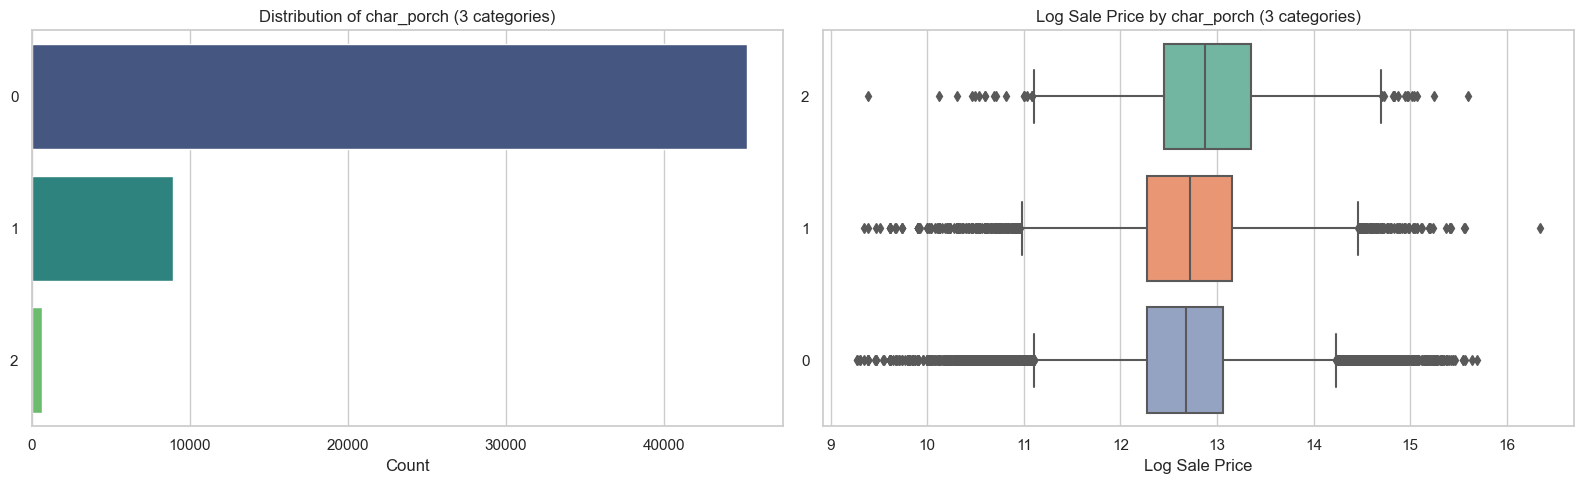

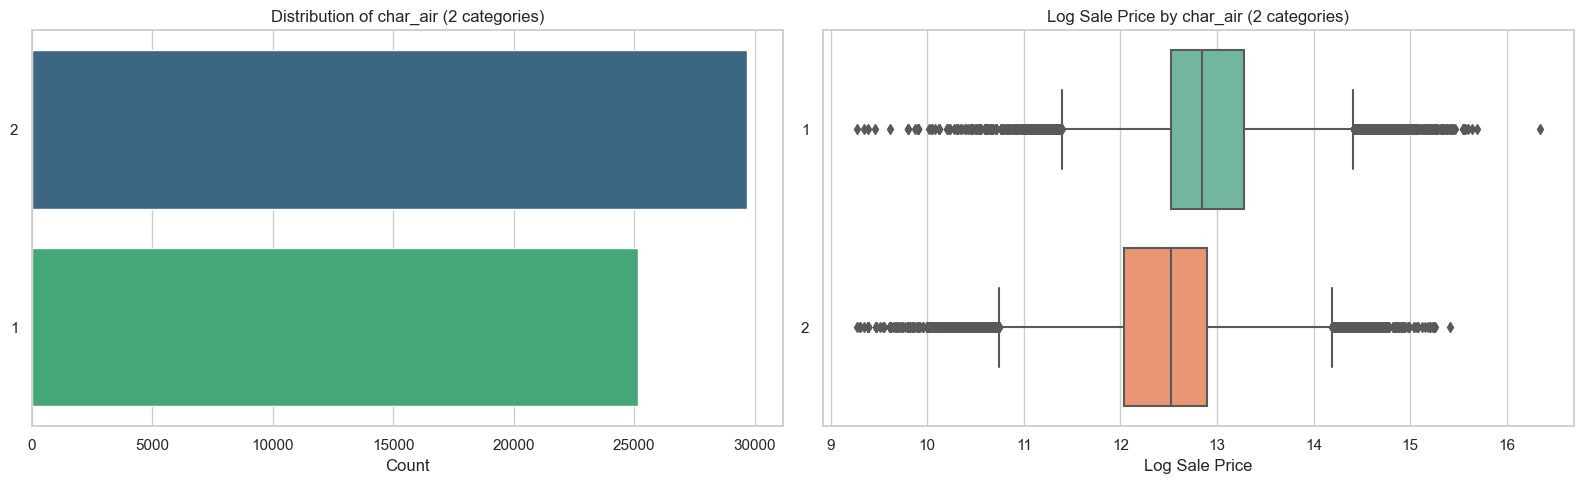

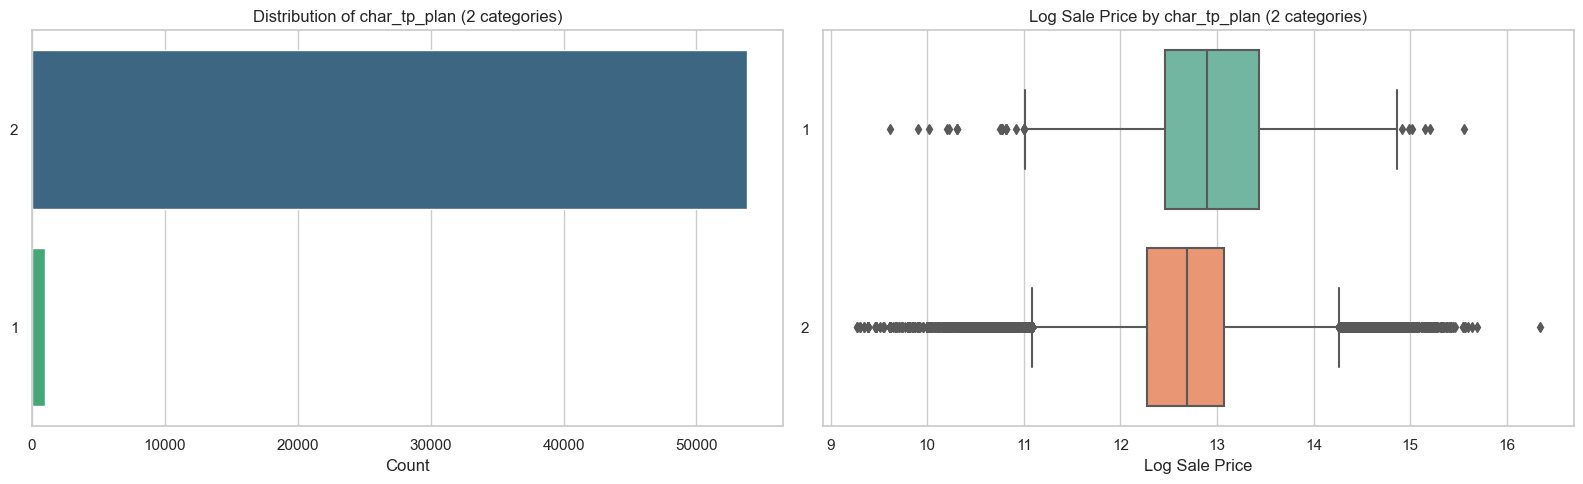

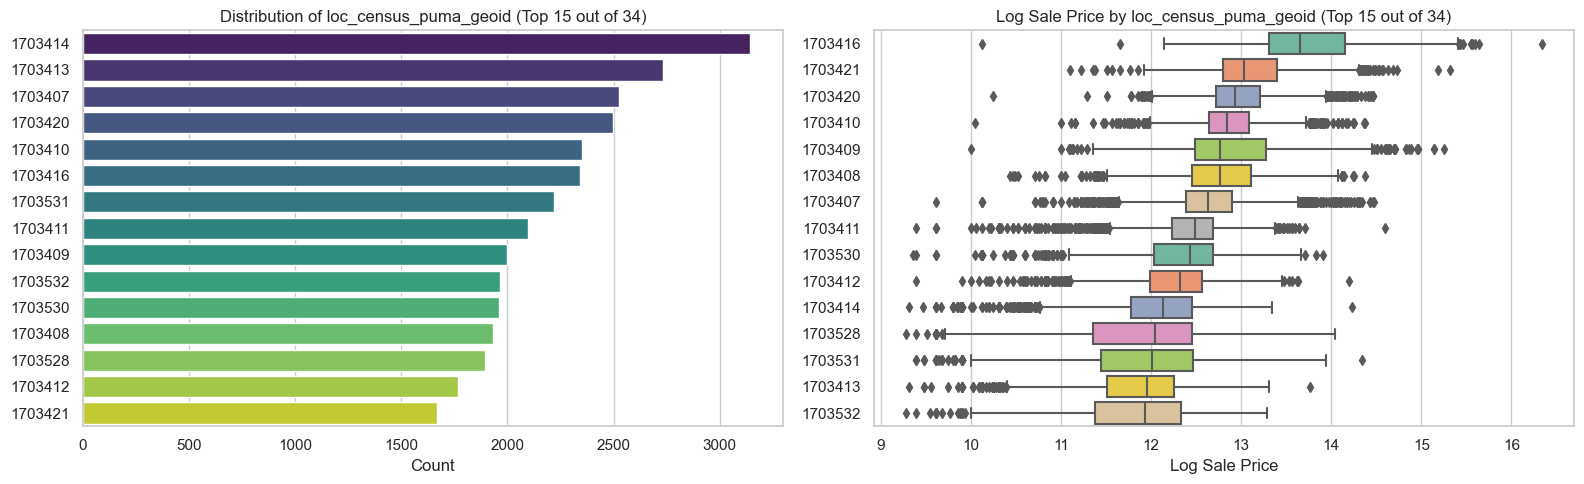

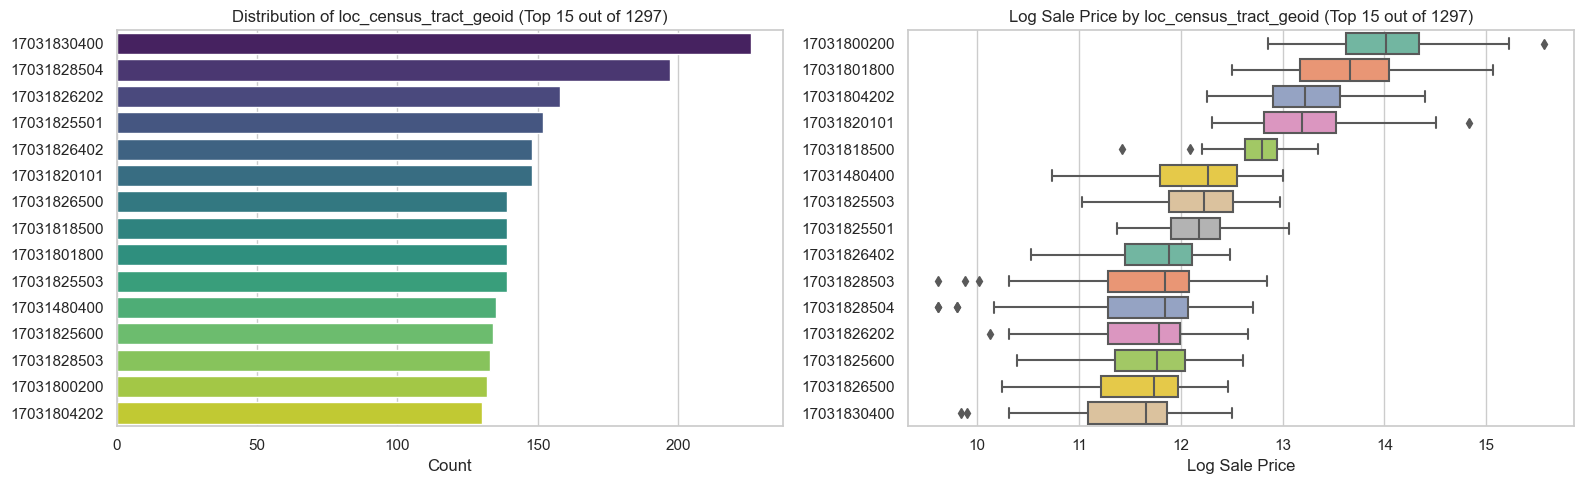

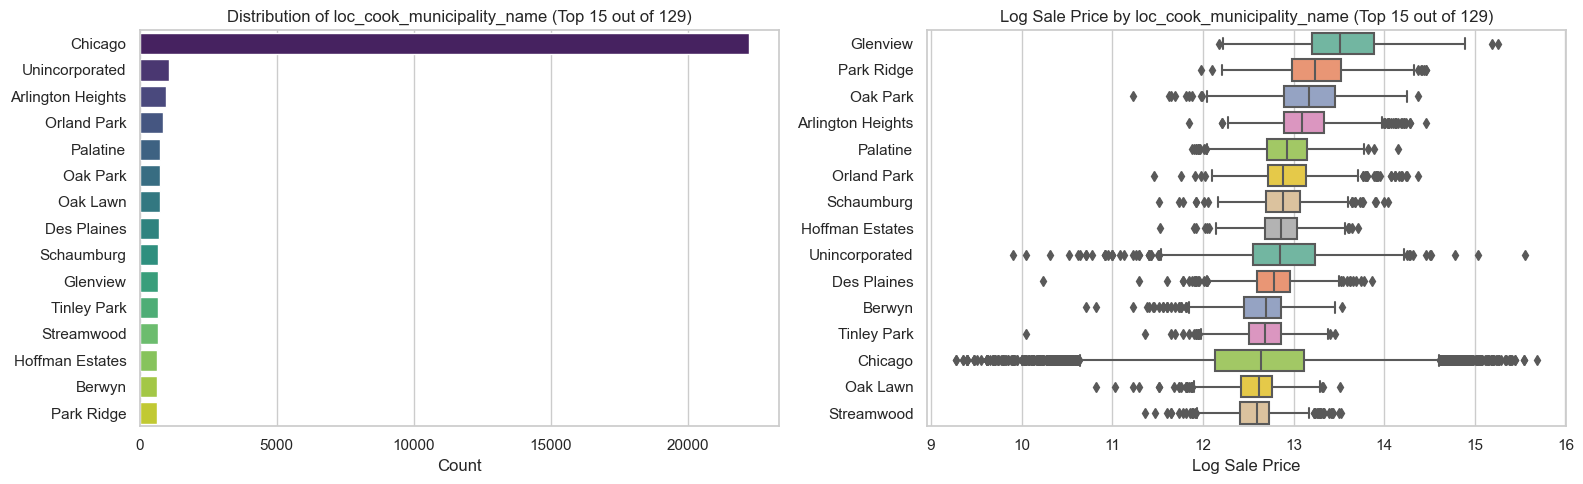

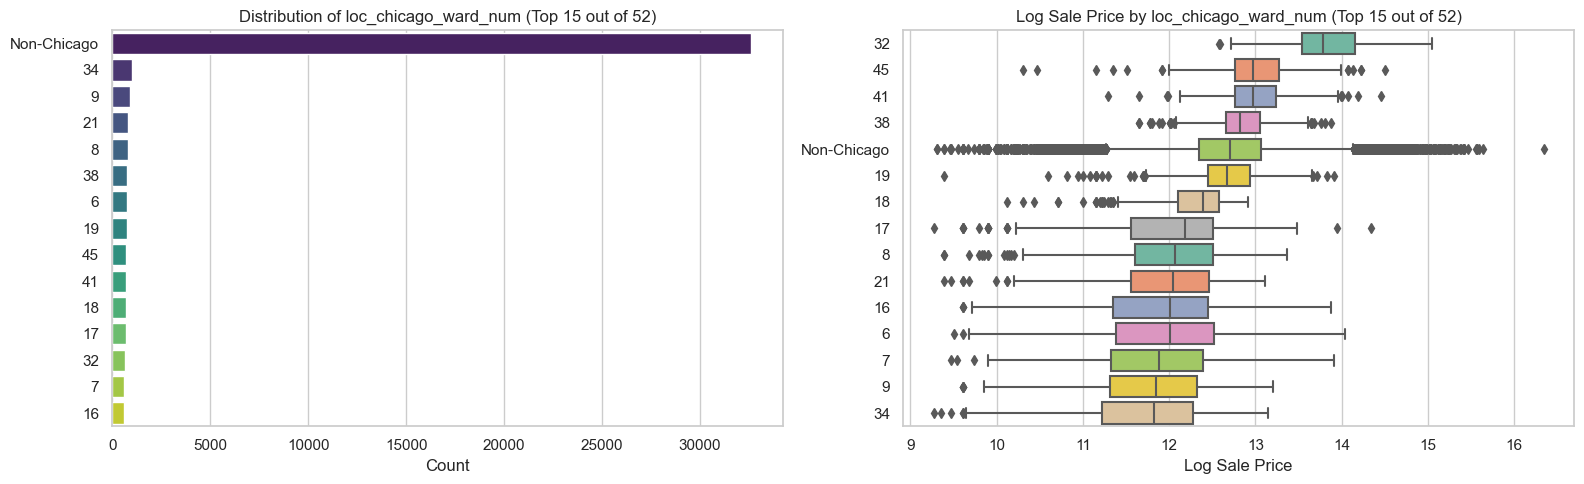

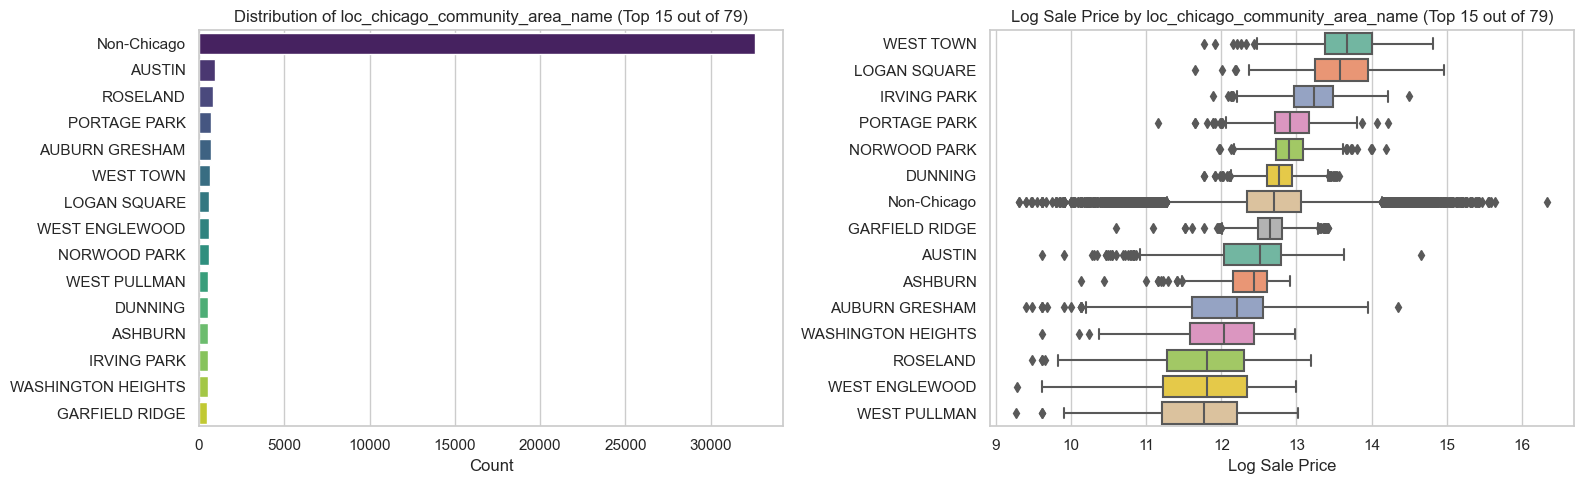

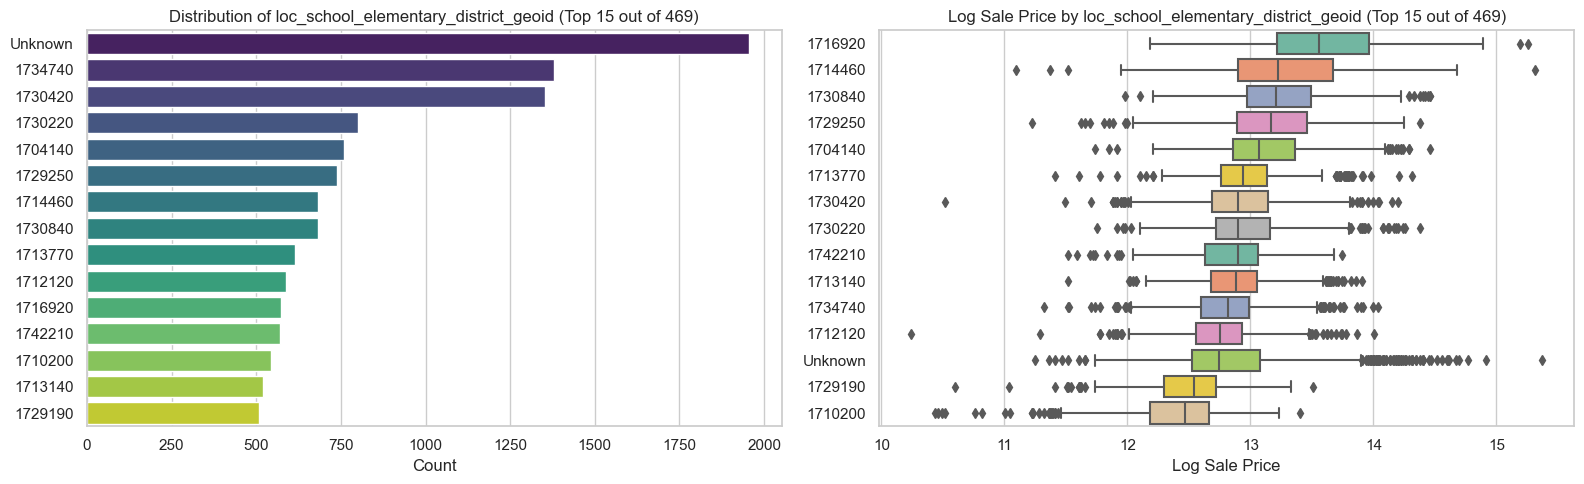

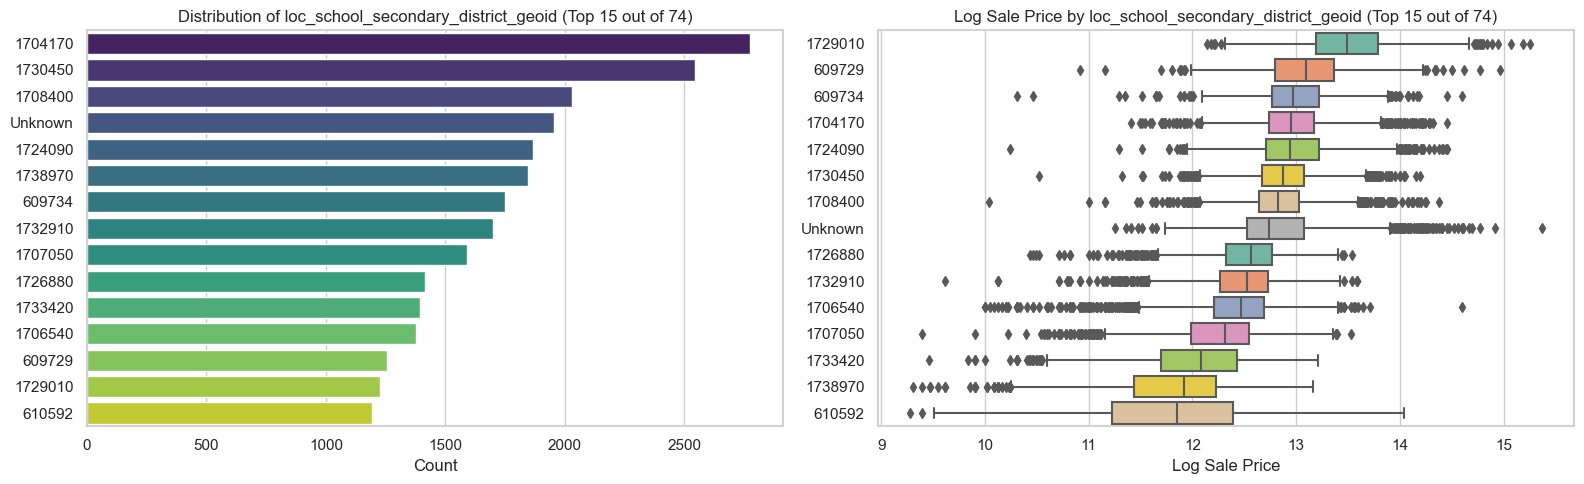

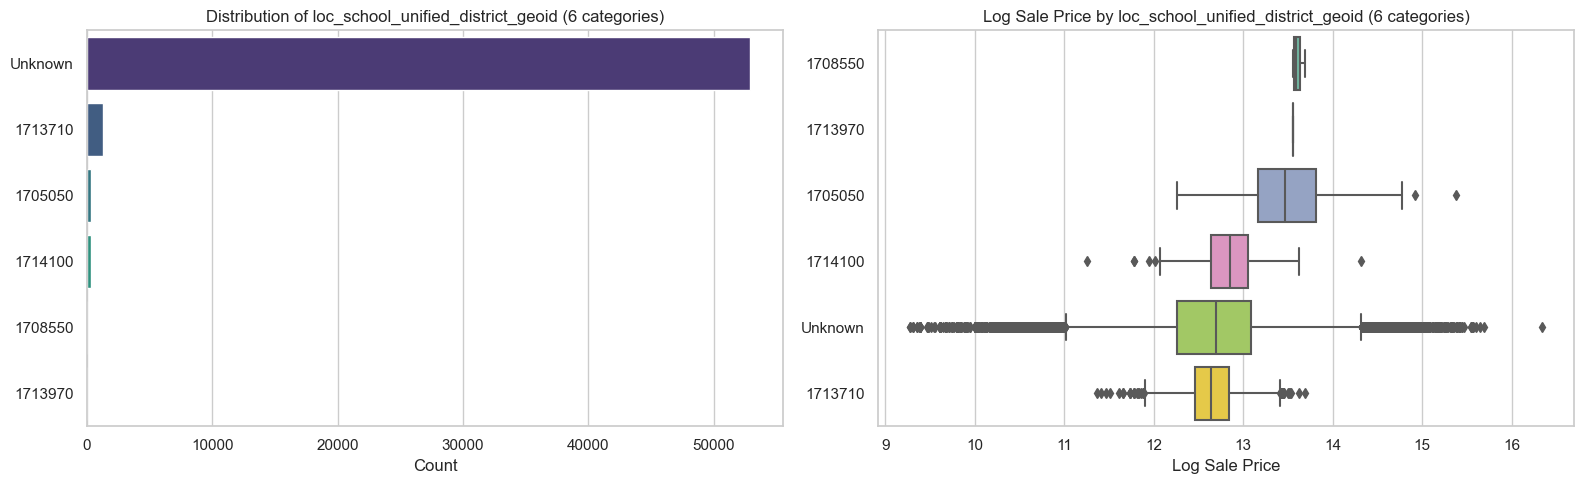

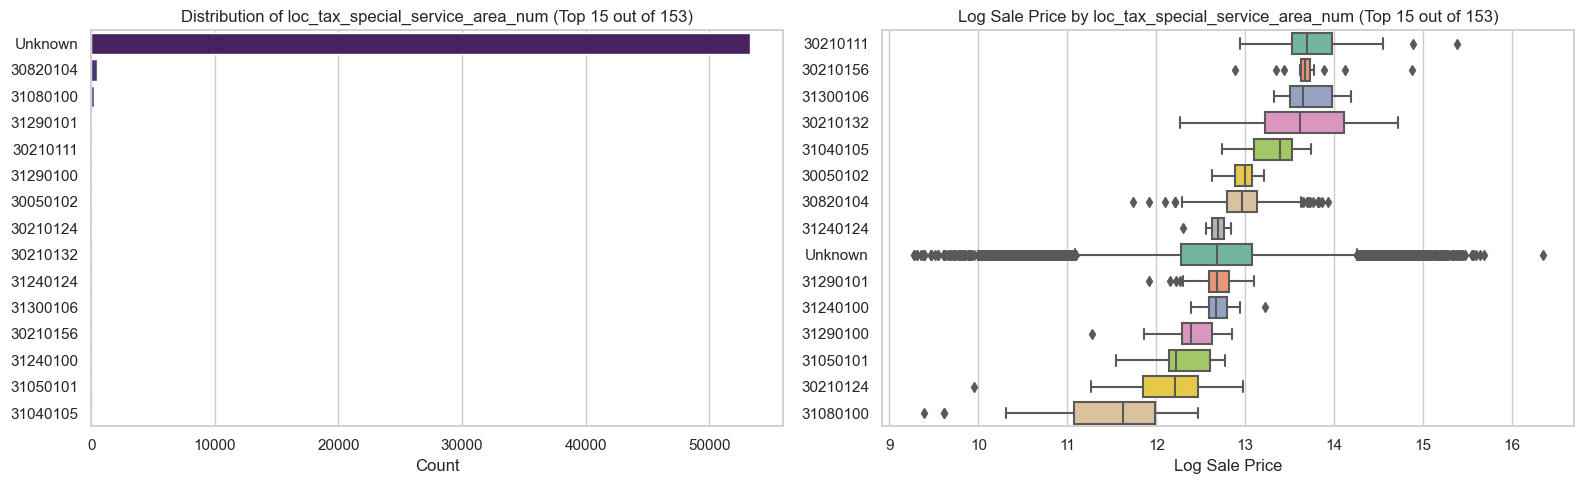

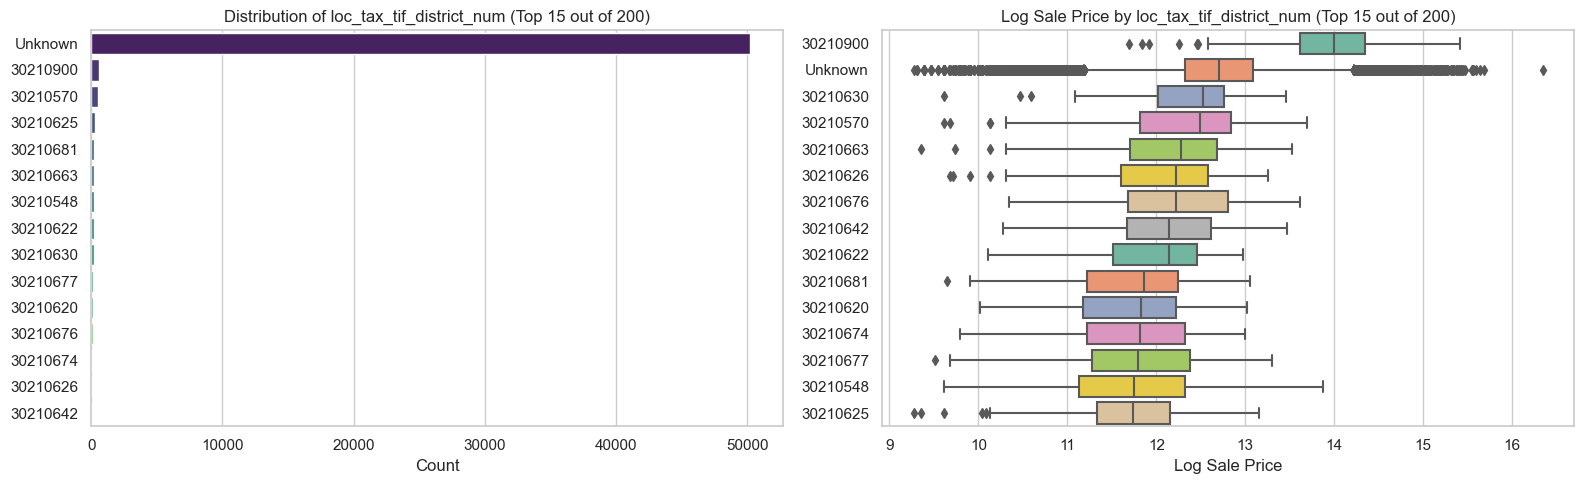

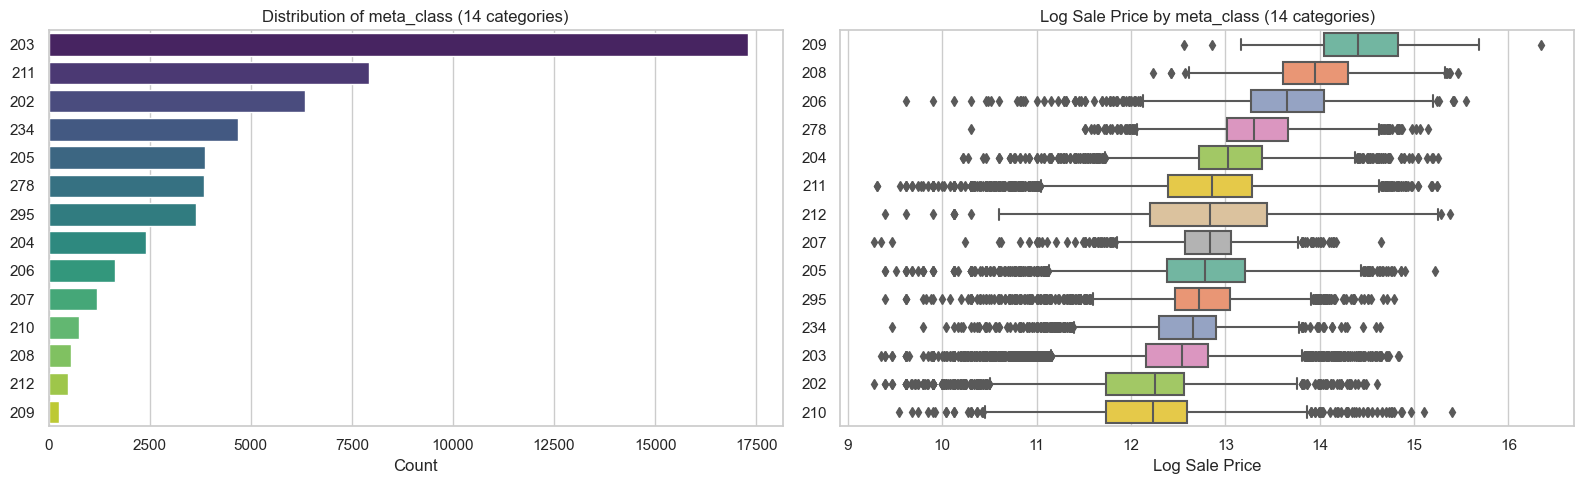

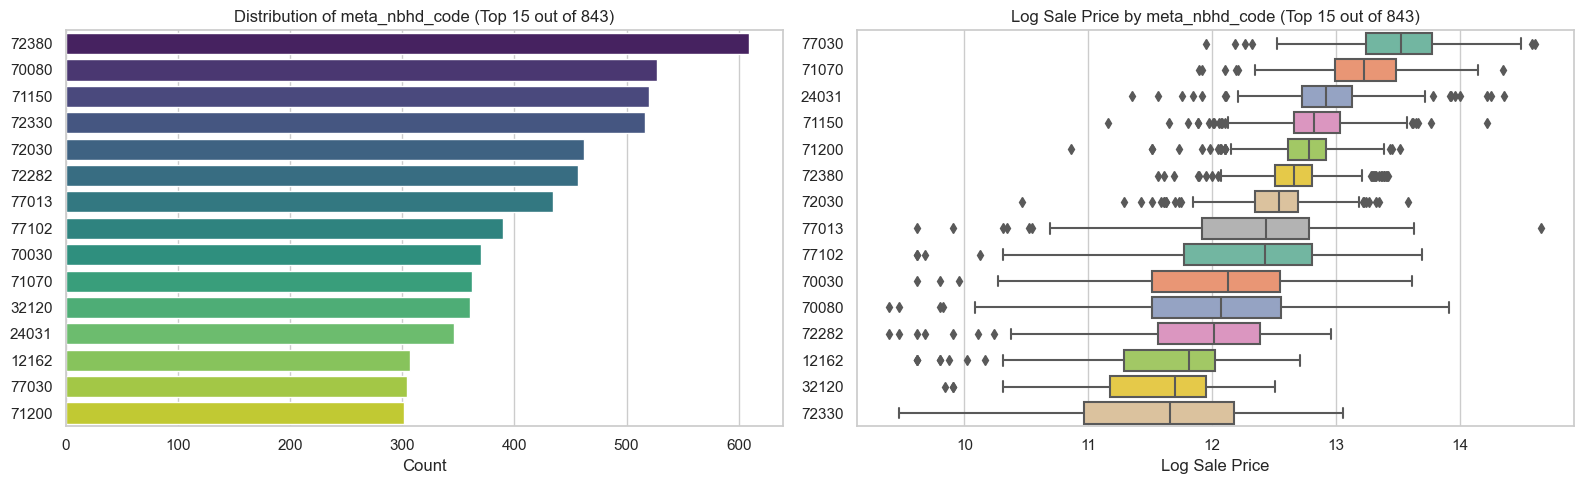

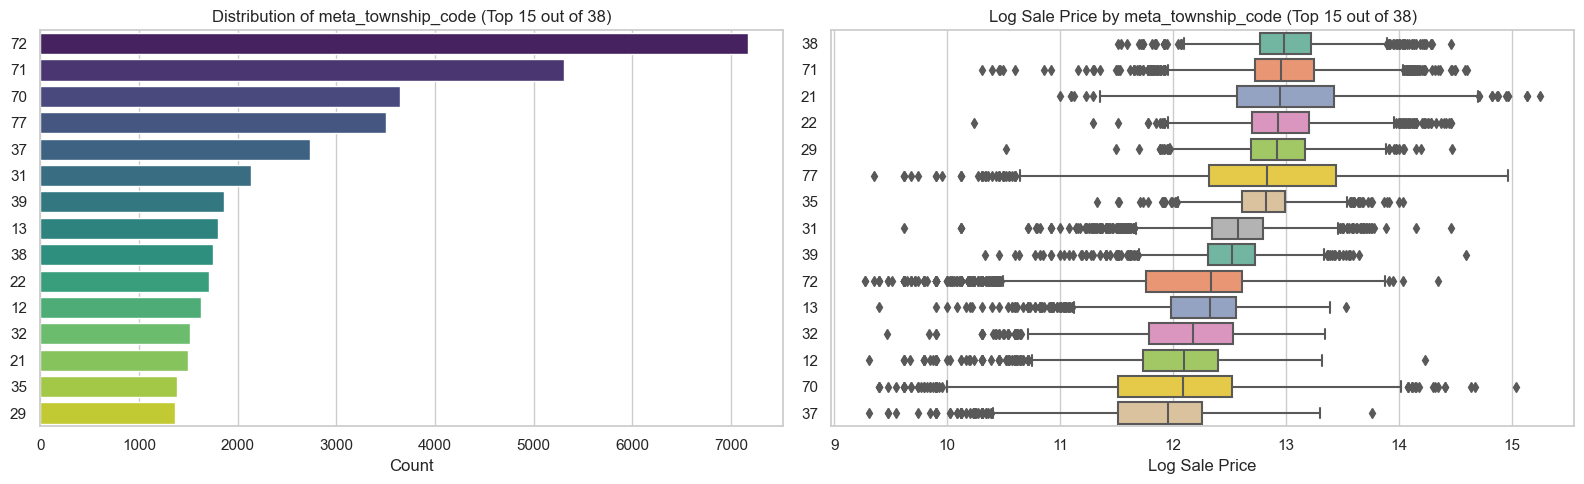

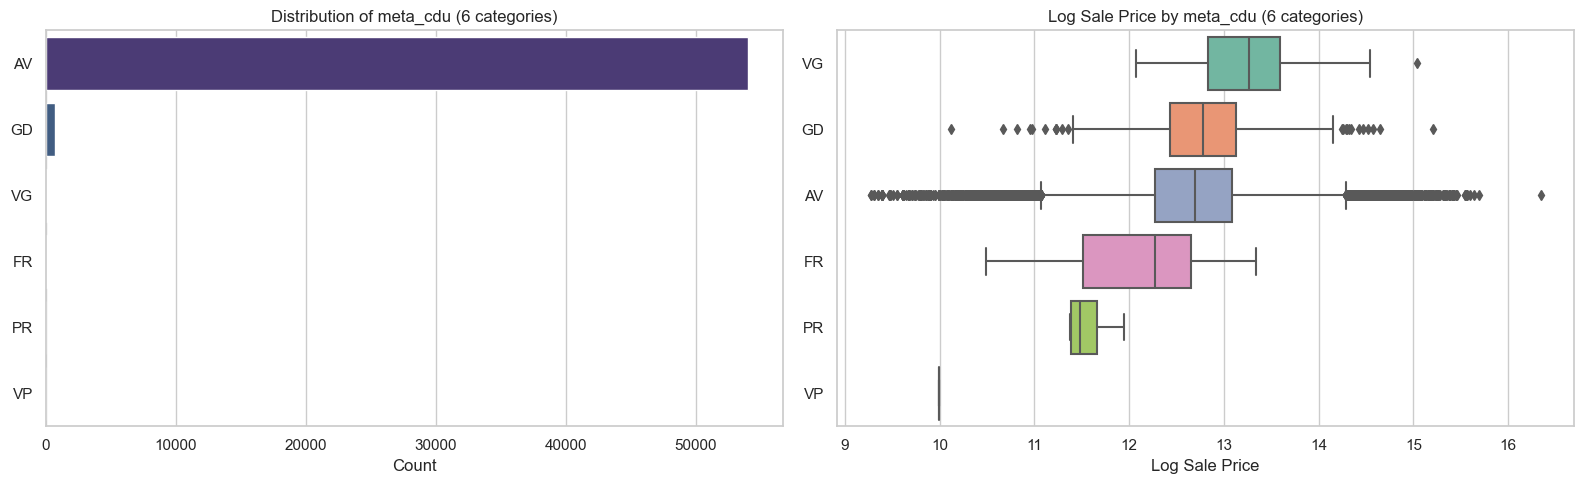


各特征类别对应的价格中位数 (按中位数降序):

--- property_id (基数: 51667) ---


                count  median    mean
property_id                          
05161060440000      1  16.341  16.341
17031100060000      1  15.687  15.687
05204070100000      1  15.640  15.640
05083030290000      1  15.595  15.595
05071090420000      1  15.565  15.565
05204000610000      1  15.565  15.565
05291010380000      1  15.556  15.556
17042110170000      1  15.547  15.547
17032040230000      1  15.547  15.547
05212000030000      1  15.464  15.464

--- loc_property_city (基数: 132) ---
                   count  median    mean
loc_property_city                       
KENILWORTH            68  14.263  14.262
WINNETKA             251  14.254  14.292
GLENCOE              176  14.119  14.140
BARRINGTON HILLS      35  13.816  13.871
GOLF                   4  13.799  13.808
HINSDALE              50  13.795  13.791
BURR RIDGE            52  13.781  13.776
SOUTH BARRINGTON      92  13.777  13.818
WILMETTE             511  13.728  13.778
NORTHFIELD           110  13.715  13.721

--- loc_proper

                 count  median    mean
char_attic_fnsh                       
2                  361  12.835  12.785
1                 6737  12.725  12.733
3                47755  12.682  12.647

--- char_gar1_size (基数: 8) ---
                count  median    mean
char_gar1_size                       
8                 224  13.723  13.665
5                1502  13.416  13.453
6                 154  13.386  13.375
3               29937  12.754  12.740
4                2354  12.737  12.757
1                8368  12.560  12.481
7                9118  12.499  12.433
2                3196  12.496  12.438

--- char_gar1_cnst (基数: 4) ---
                count  median    mean
char_gar1_cnst                       
4                 146  13.600  13.667
2               10773  12.969  13.013
3                2818  12.835  12.821
1               41116  12.607  12.550

--- char_attic_type (基数: 3) ---
                 count  median    mean
char_attic_type                       
3                37104

           count  median    mean
char_heat                       
4            139  12.886  12.864
2           8573  12.794  12.750
1          45900  12.676  12.642
3            241  12.346  12.276

--- char_bsmt_fin (基数: 3) ---
               count  median    mean
char_bsmt_fin                       
2               1050  13.109  13.054
1              16100  12.751  12.754
3              37703  12.657  12.606

--- char_roof_cnst (基数: 6) ---
                count  median    mean
char_roof_cnst                       
4                 445  13.775  13.772
3                 211  13.385  13.369
6                 320  13.385  13.264
5                 318  13.097  13.035
2                4637  13.017  12.982
1               48922  12.660  12.608

--- char_use (基数: 2) ---
          count  median    mean
char_use                       
2          8395  12.861  12.780
1         46458  12.660  12.636

--- char_porch (基数: 3) ---
            count  median    mean
char_porch                       



--- loc_census_puma_geoid (基数: 34) ---
                       count  median    mean
loc_census_puma_geoid                       
1703502                  838  14.009  14.039
1703525                  204  13.820  13.920
1703416                 2342  13.657  13.728
1703524                  932  13.516  13.502
1703501                  361  13.494  13.506
1703503                  966  13.460  13.498
1703522                 1004  13.366  13.382
1703504                 1227  13.181  13.167
1703421                 1670  13.028  13.115
1703401                 1648  12.972  13.035

--- loc_census_tract_geoid (基数: 1297) ---
                        count  median    mean
loc_census_tract_geoid                       
17031081201                 2  15.476  15.476
17031839000                 1  15.384  15.384
17031080201                 2  15.073  15.073
17031081401                 1  15.020  15.020
17031839100                 1  14.880  14.880
17031081800                 1  14.790  14.790
170310812

...

                          count  median    mean
loc_tax_tif_district_num                       
30210675                      1  14.880  14.880
30210536                      6  14.133  14.157
30210900                    606  13.998  14.002
30210632                      2  13.869  13.869
30210530                      1  13.764  13.764
30210572                     48  13.739  13.776
30820501                      1  13.710  13.710
31300500                      1  13.710  13.710
30210565                      2  13.694  13.694
30210549                     16  13.601  13.496

--- meta_class (基数: 14) ---
            count  median    mean
meta_class                       
209           250  14.403  14.428
208           551  13.949  13.977
206          1636  13.653  13.592
278          3840  13.306  13.357
204          2402  13.030  13.030
211          7931  12.861  12.780
212           477  12.835  12.817
207          1199  12.834  12.792
205          3871  12.785  12.723
295          3652  12

⚠️ property_id: Test集有 32445 个新类别 (Train集未见): ['31152080090000', '14193260070000', '03211130070000', '23363010140000', '28171020010000'] ...
✅ loc_property_city: Test集类别完全被Train集覆盖。
⚠️ loc_property_zip: Test集有 1 个新类别 (Train集未见): ['60658'] ...
✅ char_type_resd: Test集类别完全被Train集覆盖。
✅ char_cnst_qlty: Test集类别完全被Train集覆盖。
✅ char_apts: Test集类别完全被Train集覆盖。
✅ char_attic_fnsh: Test集类别完全被Train集覆盖。
✅ char_gar1_size: Test集类别完全被Train集覆盖。
✅ char_gar1_cnst: Test集类别完全被Train集覆盖。
✅ char_attic_type: Test集类别完全被Train集覆盖。


✅ char_bsmt: Test集类别完全被Train集覆盖。
✅ char_ext_wall: Test集类别完全被Train集覆盖。
✅ char_heat: Test集类别完全被Train集覆盖。
✅ char_bsmt_fin: Test集类别完全被Train集覆盖。
✅ char_roof_cnst: Test集类别完全被Train集覆盖。
✅ char_use: Test集类别完全被Train集覆盖。
✅ char_porch: Test集类别完全被Train集覆盖。
✅ char_air: Test集类别完全被Train集覆盖。
✅ char_tp_plan: Test集类别完全被Train集覆盖。


✅ loc_census_puma_geoid: Test集类别完全被Train集覆盖。
⚠️ loc_census_tract_geoid: Test集有 7 个新类别 (Train集未见): ['17031030701', '17031802403', '17031836200', '17031280900', '17031420100'] ...
✅ loc_cook_municipality_name: Test集类别完全被Train集覆盖。
✅ loc_chicago_ward_num: Test集类别完全被Train集覆盖。
✅ loc_chicago_community_area_name: Test集类别完全被Train集覆盖。
✅ loc_school_elementary_district_geoid: Test集类别完全被Train集覆盖。
✅ loc_school_secondary_district_geoid: Test集类别完全被Train集覆盖。


✅ loc_school_unified_district_geoid: Test集类别完全被Train集覆盖。
⚠️ loc_tax_special_service_area_num: Test集有 20 个新类别 (Train集未见): ['31240120', '30920100', '30210169', '30470132', '30210167'] ...
⚠️ loc_tax_tif_district_num: Test集有 14 个新类别 (Train集未见): ['30210587', '30480508', '30510504', '30410500', '30680504'] ...
✅ meta_class: Test集类别完全被Train集覆盖。
⚠️ meta_nbhd_code: Test集有 3 个新类别 (Train集未见): ['22145', '32042', '30100'] ...
✅ meta_township_code: Test集类别完全被Train集覆盖。
✅ meta_cdu: Test集类别完全被Train集覆盖。


In [ ]:
# 1. 条形图与箱线图 (针对低基数与 Top N 类别)
# ==========================================
print("正在生成各特征的分布与价格关系图...")

for col in pkg_category:
    if col not in train_data.columns:
        continue

    # 计算类别基数
    n_unique = train_data[col].nunique()

    # 如果类别过多，只取频数最高的前 15 个类别画图
    if n_unique > 15:
        top_categories = train_data[col].value_counts().nlargest(15).index
        df_plot = train_data[train_data[col].isin(top_categories)]
        title_suffix = f" (Top 15 out of {n_unique})"
    else:
        df_plot = train_data
        title_suffix = f" ({n_unique} categories)"

    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 5))

    # 左图：Count Plot (类别分布)
    sns.countplot(data=df_plot, y=col, order=df_plot[col].value_counts().index, ax=axes[0], palette="viridis")
    axes[0].set_title(f'Distribution of {col}{title_suffix}')
    axes[0].set_xlabel('Count')
    axes[0].set_ylabel('')

    # 右图：Box Plot (不同类别下的价格分布)
    # 确保类别按价格中位数排序，使图表更易读
    order = df_plot.groupby(col)['log_sale_price'].median().sort_values(ascending=False).index
    sns.boxplot(data=df_plot, y=col, x='log_sale_price', order=order, ax=axes[1], palette="Set2")
    axes[1].set_title(f'Log Sale Price by {col}{title_suffix}')
    axes[1].set_xlabel('Log Sale Price')
    axes[1].set_ylabel('')

    plt.tight_layout()
    save_figure(f"12_category_{col}")
    plt.show()

# ==========================================
# 2. 统计表：类别对应的价格中位数
# ==========================================
print("\n各特征类别对应的价格中位数 (按中位数降序):")
for col in pkg_category:
    if col in train_data.columns:
        print(f"\n--- {col} (基数: {train_data[col].nunique()}) ---")
        target_summary = train_data.groupby(col)['log_sale_price'].agg(
            count='count',
            median='median',
            mean='mean'
        ).sort_values('median', ascending=False).round(3)
        print(target_summary.head(10)) # 只展示前 10 个

# ==========================================
# 3. 训练集与测试集的类别覆盖对齐情况
# ==========================================
print("\n训练集与测试集类别差异检查:")
for col in pkg_category:
    if col in train_data.columns and col in test_data.columns:
        train_cats = set(train_data[col].dropna().unique())
        test_cats = set(test_data[col].dropna().unique())

        unseen_in_test = test_cats - train_cats
        if len(unseen_in_test) > 0:
            print(f"⚠️ {col}: Test集有 {len(unseen_in_test)} 个新类别 (Train集未见): {list(unseen_in_test)[:5]} ...")
        else:
            print(f"✅ {col}: Test集类别完全被Train集覆盖。")

Next, we perform feature engineering on the categorical features. For features with a cardinality greater than 30, we apply target encoding. For those with a cardinality between 10 and 30, we use one-hot encoding combined with the grouping of rare categories. For features with a cardinality of 10 or less, we check whether any single value accounts for a disproportionately large share; if so, we group the rare categories, otherwise, we apply only one-hot encoding.

In [ ]:
from sklearn.model_selection import KFold

target_column = "log_sale_price"

def target_encode_with_smoothing(
    training_frame,
    validation_frame,
    test_frame,
    column,
    target,
    smoothing=50,
    folds=5,
):
    """Create out-of-fold training encodings and training-only holdout mappings."""
    training_global_mean = training_frame[target].mean()
    training_encoded = np.zeros(len(training_frame), dtype=float)
    splitter = KFold(n_splits=folds, shuffle=True, random_state=42)

    for fit_positions, heldout_positions in splitter.split(training_frame):
        fit_part = training_frame.iloc[fit_positions]
        heldout_part = training_frame.iloc[heldout_positions]
        category_stats = fit_part.groupby(column)[target].agg(["mean", "count"])
        smoothed_map = (
            category_stats["count"] * category_stats["mean"]
            + smoothing * training_global_mean
        ) / (category_stats["count"] + smoothing)
        training_encoded[heldout_positions] = (
            heldout_part[column].map(smoothed_map).fillna(training_global_mean)
        )

    full_stats = training_frame.groupby(column)[target].agg(["mean", "count"])
    full_map = (
        full_stats["count"] * full_stats["mean"]
        + smoothing * training_global_mean
    ) / (full_stats["count"] + smoothing)

    training_frame[f"{column}_te"] = training_encoded
    validation_frame[f"{column}_te"] = validation_frame[column].map(full_map).fillna(training_global_mean)
    test_frame[f"{column}_te"] = test_frame[column].map(full_map).fillna(training_global_mean)
    for frame in (training_frame, validation_frame, test_frame):
        frame.drop(columns=column, inplace=True)
    print(f"  Target encoded: {column}")


def group_rare_and_onehot(
    training_frame,
    validation_frame,
    test_frame,
    column,
    threshold_fraction=0.01,
):
    """Fit rare grouping and dummy columns on training categories only."""
    training_values = training_frame[column].astype("string").fillna("Missing")
    validation_values = validation_frame[column].astype("string").fillna("Missing")
    test_values = test_frame[column].astype("string").fillna("Missing")

    training_frequency = training_values.value_counts(normalize=True)
    rare_categories = set(
        training_frequency.loc[training_frequency < threshold_fraction].index
    )

    def apply_training_map(values):
        mapped = values.where(~values.isin(rare_categories), "Other")
        known_categories = set(training_frequency.index) - rare_categories
        return mapped.where(mapped.isin(known_categories | {"Other"}), "Other")

    mapped_training = apply_training_map(training_values)
    mapped_validation = apply_training_map(validation_values)
    mapped_test = apply_training_map(test_values)
    training_categories = sorted(mapped_training.unique())

    def encode(values):
        categorical = pd.Categorical(values, categories=training_categories)
        return pd.get_dummies(
            categorical,
            prefix=column,
            drop_first=True,
            dtype=int,
        )

    encoded_training = encode(mapped_training)
    encoded_validation = encode(mapped_validation)
    encoded_test = encode(mapped_test)
    encoded_validation = encoded_validation.reindex(columns=encoded_training.columns, fill_value=0)
    encoded_test = encoded_test.reindex(columns=encoded_training.columns, fill_value=0)

    for frame, encoded in (
        (training_frame, encoded_training),
        (validation_frame, encoded_validation),
        (test_frame, encoded_test),
    ):
        frame.drop(columns=column, inplace=True)
        for dummy_column in encoded.columns:
            frame[dummy_column] = encoded[dummy_column].to_numpy()

    print(
        f"  One-hot encoded from training categories: {column} "
        f"({len(rare_categories)} rare categories grouped)"
    )
    return training_frame, validation_frame, test_frame


print("Processing categorical features with training-only fitted mappings...")
excluded_encoding_columns = {
    "property_id",
    "transaction_id",
    "sale_price",
    "log_sale_price",
    "sale_date",
}
for column in pkg_category:
    if column not in train_data.columns or column in excluded_encoding_columns:
        continue
    for frame in (train_data, val_data, test_data):
        frame[column] = frame[column].astype("string").fillna("Missing")

    distinct_training_categories = train_data[column].nunique()
    if distinct_training_categories >= 30:
        target_encode_with_smoothing(
            train_data,
            val_data,
            test_data,
            column,
            target_column,
            smoothing=50,
        )
    else:
        category_frequency = train_data[column].value_counts(normalize=True)
        top_two_fraction = category_frequency.head(2).sum()
        threshold = 0.05 if distinct_training_categories >= 10 else (
            0.02 if top_two_fraction > 0.95 else 0.0
        )
        train_data, val_data, test_data = group_rare_and_onehot(
            train_data,
            val_data,
            test_data,
            column,
            threshold_fraction=threshold,
        )

print("Categorical processing complete.")
print(f"Final shapes: Train={train_data.shape}, Validation={val_data.shape}, Test={test_data.shape}")
print("Validation and test category levels were not used to fit encoders.")
assert not any(
    column.startswith(("property_id_", "transaction_id_"))
    for column in train_data.columns
), "Identifier-derived predictor detected."


Processing categorical features with training-only fitted mappings...


  Target encoded: loc_property_city


  Target encoded: loc_property_zip
  One-hot encoded from training categories: char_type_resd (0 rare categories grouped)


  One-hot encoded from training categories: char_cnst_qlty (2 rare categories grouped)


  One-hot encoded from training categories: char_apts (0 rare categories grouped)
  One-hot encoded from training categories: char_attic_fnsh (1 rare categories grouped)


...

  Target encoded: loc_tax_tif_district_num


  One-hot encoded from training categories: meta_class (7 rare categories grouped)


  Target encoded: meta_nbhd_code


  Target encoded: meta_township_code


  One-hot encoded from training categories: meta_cdu (5 rare categories grouped)
Categorical processing complete.
Final shapes: Train=(54853, 202), Validation=(18132, 202), Test=(36322, 202)
Validation and test category levels were not used to fit encoders.


In [ ]:
training_columns = train_data.columns.tolist()
assert training_columns == val_data.columns.tolist() == test_data.columns.tolist()

for dataset_name, frame in {
    "Train": train_data,
    "Validation": val_data,
    "Test": test_data,
}.items():
    assert frame["log_sale_price"].notna().all()
    assert np.isfinite(frame["log_sale_price"]).all()
    predictors = frame.drop(columns=["log_sale_price", "sale_price"], errors="ignore")
    numeric_predictors = predictors.select_dtypes(include=[np.number])
    assert np.isfinite(numeric_predictors.to_numpy(dtype=float)).all()
    assert not predictors.isna().any().any()
    print(f"{dataset_name}: target and predictors passed missing/infinite checks.")

remaining_object_columns = train_data.select_dtypes(include=["object"]).columns.tolist()
assert not remaining_object_columns, f"Unexpected object columns: {remaining_object_columns}"
print("Train, validation and test columns are aligned.")


Train: target and predictors passed missing/infinite checks.
Validation: target and predictors passed missing/infinite checks.


Test: target and predictors passed missing/infinite checks.
Train, validation and test columns are aligned.


### Missing-indicator diagnostic

Training-set target differences are reported as descriptive evidence only. Indicators are not deleted from this legacy matrix based on a single mean-difference threshold. Their incremental value is assessed later with a fixed-model validation ablation.


In [ ]:
print("Missing-indicator diagnostic on training data only")
print("=" * 80)

missing_indicator_columns = [
    column for column in train_data.columns if column.endswith("_missing")
]
indicator_rows = []
for indicator in missing_indicator_columns:
    nonmissing_group = train_data.loc[train_data[indicator] == 0, "log_sale_price"]
    missing_group = train_data.loc[train_data[indicator] == 1, "log_sale_price"]
    indicator_rows.append(
        {
            "indicator": indicator,
            "nonmissing_count": len(nonmissing_group),
            "missing_count": len(missing_group),
            "mean_log_price_difference": (
                missing_group.mean() - nonmissing_group.mean()
                if len(nonmissing_group) and len(missing_group)
                else np.nan
            ),
        }
    )

missing_indicator_report = pd.DataFrame(indicator_rows)
if not missing_indicator_report.empty:
    missing_indicator_report["absolute_difference"] = missing_indicator_report[
        "mean_log_price_difference"
    ].abs()
    missing_indicator_report = missing_indicator_report.sort_values(
        "absolute_difference", ascending=False
    )
    print(missing_indicator_report.head(20).to_string(index=False, float_format=lambda value: f"{value:.4f}"))
else:
    print("No explicit legacy missing-indicator columns were found.")

print(
    "\nNo indicators are removed here. A marginal target difference does not measure "
    "conditional or nonlinear predictive value and is not a fair feature-selection test."
)


Missing-indicator diagnostic on training data only
                                               indicator  nonmissing_count  missing_count  mean_log_price_difference  absolute_difference
  prox_num_foreclosure_per_1000_pin_past_5_years_missing             54411            442                     0.8437               0.8437
                                        meta_cdu_missing             54796             57                     0.7798               0.7798
      acs5_median_household_owner_occupied_value_missing             54765             88                    -0.5925               0.5925
                 loc_env_flood_fs_risk_direction_missing             54799             54                     0.5461               0.5461
                         loc_env_flood_fs_factor_missing             54799             54                     0.5461               0.5461
acs5_median_household_renter_occupied_gross_rent_missing             53476           1377                     0.4424     

### `is_Chicago` redundancy diagnostic

`is_Chicago` is a deterministic summary of the richer city field. Correlations with target-encoded location columns are descriptive only; the feature is not removed from the legacy matrix until a validation ablation is reported. The leakage-safe modelling pipeline below rebuilds predictors from the original property file and does not include this manually created field.


In [ ]:
location_encoding_columns = [
    "loc_property_city_te",
    "loc_chicago_ward_num_te",
    "loc_chicago_community_area_name_te",
]
available_location_encodings = [
    column for column in location_encoding_columns if column in train_data.columns
]

if "is_Chicago" in train_data.columns:
    chicago_summary = train_data.groupby("is_Chicago")["log_sale_price"].agg(
        transactions="count",
        mean_log_price="mean",
        median_log_price="median",
    )
    print("Training-only is_Chicago target summary")
    print(chicago_summary.to_string(float_format=lambda value: f"{value:.4f}"))
    print("\nCorrelation with legacy target-encoded location columns")
    for column in available_location_encodings:
        correlation = train_data[[column, "is_Chicago"]].corr().iloc[0, 1]
        print(f"{column}: {correlation:.4f}")
else:
    print("is_Chicago is not present in the legacy matrix.")

print(
    "\nThis diagnostic does not justify feature deletion. The later validation "
    "ablation holds the model, split and metrics fixed."
)


Training-only is_Chicago target summary
            transactions  mean_log_price  median_log_price
is_Chicago                                                
0                  32611         12.6972           12.7069
1                  22242         12.6006           12.6443

Correlation with legacy target-encoded location columns
loc_property_city_te: -0.1346
loc_chicago_ward_num_te: -0.1449
loc_chicago_community_area_name_te: -0.1284

This diagnostic does not justify feature deletion. The later validation ablation holds the model, split and metrics fixed.


In [ ]:
print("is_Chicago is retained in the legacy matrix pending validation ablation.")
print(
    "It is absent from the leakage-safe raw-property feature inventory unless "
    "explicitly added in the ablation experiment."
)


is_Chicago is retained in the legacy matrix pending validation ablation.
It is absent from the leakage-safe raw-property feature inventory unless explicitly added in the ablation experiment.


In [ ]:
print("Creating house age at the sale valuation year...")

for dataset_name, frame in {
    "Train": train_data,
    "Validation": val_data,
    "Test": test_data,
}.items():
    if {"char_yrblt", "sale_year"}.issubset(frame.columns):
        year_built = pd.to_numeric(frame["char_yrblt"], errors="coerce").round()
        frame["house_age"] = (frame["sale_year"] - year_built).clip(lower=0, upper=300)
        frame["house_age"] = frame["house_age"].astype("Int64")
        print(f"{dataset_name}: house_age created.")
    else:
        print(f"{dataset_name}: required columns unavailable; house_age skipped.")

print("House age uses only the valuation year and the archived year built.")


Creating house age at the sale valuation year...
Train: house_age created.
Validation: house_age created.
Test: house_age created.
House age uses only the valuation year and the archived year built.


### Final legacy-matrix cleanup

Identifiers and targets are excluded from predictors. Month indicators are generated from a predefined calendar-month template, so validation and test values do not define the training feature space.


In [ ]:
leakage_and_identifier_columns = [
    "sale_price",
    "sale_date",
    "sale_year",
    "sale_quarter",
    "sale_ym",
    "lat_bin",
    "lon_bin",
    "transaction_id",
    "property_id",
]
for dataset_name in ("train_data", "val_data", "test_data"):
    frame = globals()[dataset_name]
    frame.drop(
        columns=[
            column for column in leakage_and_identifier_columns if column in frame.columns
        ],
        inplace=True,
    )

month_template = [str(month) for month in range(1, 13)]
month_dummy_columns = pd.get_dummies(
    pd.Series(month_template, dtype="string"),
    prefix="month",
    drop_first=True,
    dtype=int,
).columns.tolist()

for dataset_name in ("train_data", "val_data", "test_data"):
    frame = globals()[dataset_name]
    month_dummies = pd.get_dummies(
        frame["sale_month"].astype("string"),
        prefix="month",
        drop_first=True,
        dtype=int,
    ).reindex(columns=month_dummy_columns, fill_value=0)
    globals()[dataset_name] = pd.concat(
        [frame.drop(columns="sale_month"), month_dummies], axis=1
    )

assert train_data.columns.tolist() == val_data.columns.tolist() == test_data.columns.tolist()
print("Identifiers and direct target fields were removed from predictors.")
print("Month indicators were aligned to a fixed 1-12 month template.")
print(f"Final legacy matrix columns: {train_data.shape[1]:,}")


Identifiers and direct target fields were removed from predictors.
Month indicators were aligned to a fixed 1-12 month template.
Final legacy matrix columns: 210


In [ ]:
assert train_data.columns.tolist() == val_data.columns.tolist() == test_data.columns.tolist()
for dataset_name, frame in {
    "Train": train_data,
    "Validation": val_data,
    "Test": test_data,
}.items():
    assert frame["log_sale_price"].notna().all()
    numeric_frame = frame.select_dtypes(include=[np.number])
    assert np.isfinite(numeric_frame.to_numpy(dtype=float)).all()
    assert not frame.isna().any().any()
    print(f"{dataset_name}: {frame.shape[0]:,} rows x {frame.shape[1]:,} columns")
print("Final legacy matrices passed column-alignment and numeric-health checks.")


Train: 54,853 rows x 210 columns
Validation: 18,132 rows x 210 columns
Test: 36,322 rows x 210 columns
Final legacy matrices passed column-alignment and numeric-health checks.


### Frozen chronological split membership

The transaction membership of Train, Validation and Test is fixed independently of the evolving feature schema. Membership is verified from the original `transaction_id`, `property_id` and `sale_date` fields. An existing feature snapshot in `data/split` is kept only when its target order and column schema match the current frame; otherwise it is moved to `data/split/archive_invalid_index_merge/` (or deleted if an archived copy already exists) and a new snapshot is written. Membership and target alignment are checked on every run, so a revised feature matrix cannot silently change which transactions belong to each split.


In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json

split_dir = Path("data") / "split"
split_dir.mkdir(parents=True, exist_ok=True)
expected_rows = {"train": 54853, "validation": 18132, "test": 36322}

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

raw_sales = pd.read_csv(
    Path("data") / "sales.csv",
    usecols=["transaction_id", "property_id", "sale_date", "sale_price"],
    dtype={"transaction_id": "string", "property_id": "string"},
)
raw_sales["transaction_id"] = raw_sales["transaction_id"].str.strip()
raw_sales["property_id"] = raw_sales["property_id"].str.strip()
raw_sales["sale_date"] = pd.to_datetime(raw_sales["sale_date"], errors="raise")

raw_split_masks = {
    "train": raw_sales["sale_date"].between("2023-01-01", "2024-06-30"),
    "validation": raw_sales["sale_date"].between("2024-07-01", "2024-12-31"),
    "test": raw_sales["sale_date"].between("2025-01-01", "2025-12-31"),
}
raw_splits = {
    name: raw_sales.loc[mask].reset_index(drop=True)
    for name, mask in raw_split_masks.items()
}

membership_details = {}
for name, raw_split in raw_splits.items():
    assert len(raw_split) == expected_rows[name], f"Unexpected {name} row count."
    identity = raw_split[["transaction_id", "property_id", "sale_date"]].copy()
    identity["sale_date"] = identity["sale_date"].dt.strftime("%Y-%m-%d")
    identity_path = split_dir / f"{name}_membership.csv"
    if identity_path.exists():
        saved_identity = pd.read_csv(
            identity_path,
            dtype={"transaction_id": "string", "property_id": "string"},
        )
        pd.testing.assert_frame_equal(saved_identity, identity, check_dtype=False)
    else:
        identity.to_csv(identity_path, index=False)
    membership_details[name] = {
        "file": identity_path.name,
        "rows": len(identity),
        "sha256": sha256_file(identity_path),
    }

current_frames = {
    "train": train_data,
    "validation": val_data,
    "test": test_data,
}
manifest_path = split_dir / "manifest.json"
previous_manifest = (
    json.loads(manifest_path.read_text(encoding="utf-8"))
    if manifest_path.exists()
    else {}
)

snapshot_details = {}
archive_dir = split_dir / "archive_invalid_index_merge"
for name, current_frame in current_frames.items():
    snapshot_path = split_dir / f"{name}.csv"
    expected_log_target = np.log1p(raw_splits[name]["sale_price"].to_numpy(dtype=float))
    np.testing.assert_allclose(
        current_frame["log_sale_price"].to_numpy(dtype=float),
        expected_log_target,
        rtol=1e-12,
        atol=1e-12,
    )
    if snapshot_path.exists():
        saved_snapshot = pd.read_csv(snapshot_path)
        assert len(saved_snapshot) == expected_rows[name]
        assert "sale_price" in saved_snapshot.columns
        target_order_matches = np.array_equal(
            saved_snapshot["sale_price"].to_numpy(dtype=float),
            raw_splits[name]["sale_price"].to_numpy(dtype=float),
        )
        schema_matches = (
            saved_snapshot.drop(columns=["sale_price"], errors="ignore").columns.tolist()
            == current_frame.columns.tolist()
        )
        if not (target_order_matches and schema_matches):
            archive_dir.mkdir(parents=True, exist_ok=True)
            archive_path = archive_dir / snapshot_path.name
            if not archive_path.exists():
                snapshot_path.replace(archive_path)
            else:
                snapshot_path.unlink()

    if not snapshot_path.exists():
        snapshot = current_frame.copy()
        snapshot.insert(0, "sale_price", raw_splits[name]["sale_price"].to_numpy())
        snapshot.to_csv(snapshot_path, index=False, float_format="%.17g")
    saved_snapshot = pd.read_csv(snapshot_path)
    assert saved_snapshot.drop(columns=["sale_price"]).columns.tolist() == current_frame.columns.tolist()
    np.testing.assert_allclose(
        saved_snapshot["sale_price"].to_numpy(dtype=float),
        raw_splits[name]["sale_price"].to_numpy(dtype=float),
        rtol=0,
        atol=0,
    )
    schema_status = "current schema"
    snapshot_details[name] = {
        "file": snapshot_path.name,
        "rows": len(saved_snapshot),
        "columns": len(saved_snapshot.columns),
        "sha256": sha256_file(snapshot_path),
        "schema_status": schema_status,
    }
    print(
        f"{name}: {len(saved_snapshot):,} rows x {len(saved_snapshot.columns):,} columns; "
        f"{schema_status}."
    )

if archive_dir.exists():
    archive_note = archive_dir / "README.txt"
    if not archive_note.exists():
        archive_note.write_text(
            "These feature snapshots were archived because the earlier notebook "
            "joined sales and properties on a property_id index. The join returned "
            "the rows sorted by property_id instead of in sales.csv order, and later "
            "encoding steps dropped the identifiers, so these rows cannot be linked "
            "back to transaction_id or property_id.\n",
            encoding="utf-8",
        )
    old_manifest_path = archive_dir / "manifest.json"
    if previous_manifest and not old_manifest_path.exists():
        old_manifest_path.write_text(
            json.dumps(previous_manifest, indent=2) + "\n",
            encoding="utf-8",
        )

notebook_content = json.loads(Path("assignment_6810.ipynb").read_text(encoding="utf-8"))
split_cell_index = next(
    index
    for index, cell in enumerate(notebook_content["cells"])
    if "raw_split_masks" in "".join(cell.get("source", []))
)
pipeline_sources = [
    {"cell_type": cell["cell_type"], "source": cell.get("source", [])}
    for cell in notebook_content["cells"][:split_cell_index]
]
current_pipeline_digest = hashlib.sha256(
    json.dumps(pipeline_sources, sort_keys=True, ensure_ascii=False).encode("utf-8")
).hexdigest()

source_files = [
    "data/properties_2022.csv",
    "data/sales.csv",
    "data/variable_dictionary.csv",
    "data/featureengineer.csv",
]
manifest = {
    "created_utc": previous_manifest.get(
        "created_utc", datetime.now(timezone.utc).isoformat()
    ),
    "last_verified_utc": datetime.now(timezone.utc).isoformat(),
    "format": "csv",
    "source_notebook": "assignment_6810.ipynb",
    "feature_snapshot_pipeline_sha256": previous_manifest.get(
        "pipeline_code_sha256", current_pipeline_digest
    ),
    "current_notebook_pipeline_sha256": current_pipeline_digest,
    "input_sha256": {path: sha256_file(path) for path in source_files},
    "target": "sale_price",
    "derived_target": "log_sale_price",
    "time_split": {
        "train": "2023-01-01 through 2024-06-30",
        "validation": "2024-07-01 through 2024-12-31",
        "test": "2025-01-01 through 2025-12-31",
    },
    "membership": membership_details,
    "splits": snapshot_details,
}
manifest_path.write_text(json.dumps(manifest, indent=2) + "\n", encoding="utf-8")
print("Chronological membership verified from original IDs and dates.")
print("Feature snapshots now use the corrected property_id join and current schema.")


train: 54,853 rows x 211 columns; current schema.


validation: 18,132 rows x 211 columns; current schema.


test: 36,322 rows x 211 columns; current schema.


Chronological membership verified from original IDs and dates.
Feature snapshots now use the corrected property_id join and current schema.


### Global Mean baseline on the frozen validation set

Predict the training mean sale price in dollars for every validation transaction. Table 1 reports MSE, MAE, R² and the pre-selected 2:1 overvaluation-priority WAE. Table 2 reports baseline WAE under all three required weighting scenarios while keeping predictions fixed. MSE is in squared dollars; MAE and WAE are in dollars; R² is unitless. The 2025 test set is not scored.

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# Load the frozen training and validation data and verify their checksums.
with (split_dir / "manifest.json").open(encoding="utf-8") as stream:
    saved_manifest = json.load(stream)
frozen = {}
for name in ("train", "validation"):
    details = saved_manifest["splits"][name]
    path = split_dir / details["file"]
    assert sha256_file(path) == details["sha256"], f"{name} split checksum changed."
    frozen[name] = pd.read_csv(path)

# Predict the training mean sale price for every validation transaction.
global_mean = frozen["train"]["sale_price"].mean()
baseline_prediction = np.full(len(frozen["validation"]), global_mean)
actual_price = frozen["validation"]["sale_price"].to_numpy()

# Apply direction-specific weights without changing the predictions.
def weighted_absolute_error(y_true, y_pred, overvaluation_weight, undervaluation_weight):
    prediction_error = np.asarray(y_pred) - np.asarray(y_true)
    direction_weights = np.where(
        prediction_error > 0,
        overvaluation_weight,
        np.where(prediction_error < 0, undervaluation_weight, 1.0),
    )
    return np.mean(np.abs(prediction_error) * direction_weights)

weighting_scenarios = [
    ("Equal priority", 1, 1),
    ("Greater concern about overvaluation", 2, 1),
    ("Greater concern about undervaluation", 1, 2),
]
baseline_wae_sensitivity = pd.DataFrame([
    {
        "Scenario": scenario,
        "Overvaluation Weight": overvaluation_weight,
        "Undervaluation Weight": undervaluation_weight,
        "Baseline WAE ($)": weighted_absolute_error(
            actual_price,
            baseline_prediction,
            overvaluation_weight,
            undervaluation_weight,
        ),
    }
    for scenario, overvaluation_weight, undervaluation_weight in weighting_scenarios
])
main_wae = baseline_wae_sensitivity.loc[
    baseline_wae_sensitivity["Scenario"] == "Greater concern about overvaluation",
    "Baseline WAE ($)",
].iloc[0]

baseline_metrics = pd.DataFrame([{
    "Baseline": "Global Mean",
    "MSE ($²)": mean_squared_error(actual_price, baseline_prediction),
    "MAE ($)": mean_absolute_error(actual_price, baseline_prediction),
    "R²": r2_score(actual_price, baseline_prediction),
    "Main WAE 2:1 ($)": main_wae,
}])
print(f"Training mean sale price (USD): {global_mean:,.2f}")
print(f"Training transactions: {len(frozen['train']):,}")
print(f"Validation transactions: {len(frozen['validation']):,}")
print("\nTable 1. Global Mean baseline metrics (2024 validation)")
print(baseline_metrics.to_string(index=False, float_format=lambda value: f"{value:,.4f}"))
print("\nTable 2. Baseline WAE sensitivity (2024 validation; predictions fixed)")
print(baseline_wae_sensitivity.to_string(index=False, float_format=lambda value: f"{value:,.4f}"))

baseline_output_dir = Path("data") / "result" / "baseline"
baseline_output_dir.mkdir(parents=True, exist_ok=True)
baseline_metrics.to_csv(baseline_output_dir / "global_mean_baseline_metrics.csv", index=False, encoding="utf-8-sig")
baseline_wae_sensitivity.to_csv(
    baseline_output_dir / "global_mean_baseline_wae_sensitivity.csv", index=False, encoding="utf-8-sig"
)
print("\nBaseline tables saved to data/result/baseline/")

Training mean sale price (USD): 418,490.00
Training transactions: 54,853
Validation transactions: 18,132

Table 1. Global Mean baseline metrics (2024 validation)
   Baseline             MSE ($²)      MAE ($)      R²  Main WAE 2:1 ($)
Global Mean 191,693,119,024.9673 238,599.6175 -0.0050      342,381.8231

Table 2. Baseline WAE sensitivity (2024 validation; predictions fixed)
                            Scenario  Overvaluation Weight  Undervaluation Weight  Baseline WAE ($)
                      Equal priority                     1                      1      238,599.6175
 Greater concern about overvaluation                     2                      1      342,381.8231
Greater concern about undervaluation                     1                      2      373,417.0295

Baseline tables saved to data/result/baseline/


### Section 3c – Repeated Property Overlap Check

Recalculate property overlap from the original `property_id` field in `sales.csv`. The ID is used only for this diagnostic and is not included as a predictive feature.

In [ ]:
# Read property identifiers as strings to preserve their original formatting.
overlap_sales = pd.read_csv(
    Path("data") / "sales.csv",
    usecols=["property_id", "sale_date"],
    dtype={"property_id": "string"},
)
overlap_sales["property_id"] = overlap_sales["property_id"].str.strip()
overlap_sales["sale_date"] = pd.to_datetime(overlap_sales["sale_date"], errors="raise")

assert overlap_sales["property_id"].notna().all(), "Missing property IDs found."
assert overlap_sales["property_id"].ne("").all(), "Empty property IDs found."

# Apply the same chronological boundaries used by the existing split.
overlap_train = overlap_sales.loc[
    (overlap_sales["sale_date"] >= "2023-01-01")
    & (overlap_sales["sale_date"] < "2024-07-01")
].copy()
overlap_validation = overlap_sales.loc[
    (overlap_sales["sale_date"] >= "2024-07-01")
    & (overlap_sales["sale_date"] < "2025-01-01")
].copy()

training_property_ids = set(overlap_train["property_id"])
seen_mask = overlap_validation["property_id"].isin(training_property_ids)
seen_transactions = int(seen_mask.sum())
unseen_transactions = int((~seen_mask).sum())
overlapping_property_ids = set(overlap_validation.loc[seen_mask, "property_id"])
seen_percentage = seen_transactions / len(overlap_validation) * 100

print(f"Property ID dtype: {overlap_sales['property_id'].dtype}")
print(f"Missing property IDs: {overlap_sales['property_id'].isna().sum():,}")
print(f"Empty property IDs: {overlap_sales['property_id'].eq('').sum():,}")
print(f"Training period: {overlap_train['sale_date'].min().date()} to {overlap_train['sale_date'].max().date()}")
print(f"Validation period: {overlap_validation['sale_date'].min().date()} to {overlap_validation['sale_date'].max().date()}")
print(f"Training transactions: {len(overlap_train):,}")
print(f"Validation transactions: {len(overlap_validation):,}")
print(f"Seen transactions: {seen_transactions:,}")
print(f"Unseen transactions: {unseen_transactions:,}")
print(f"Distinct overlapping properties: {len(overlapping_property_ids):,}")
print(f"Seen percentage: {seen_percentage:.4f}%")

diagnostics_dir = Path("data") / "result" / "diagnostics"
diagnostics_dir.mkdir(parents=True, exist_ok=True)
pd.DataFrame([{
    "training_period": f"{overlap_train['sale_date'].min().date()} to {overlap_train['sale_date'].max().date()}",
    "validation_period": f"{overlap_validation['sale_date'].min().date()} to {overlap_validation['sale_date'].max().date()}",
    "training_transactions": len(overlap_train),
    "validation_transactions": len(overlap_validation),
    "seen_transactions": seen_transactions,
    "unseen_transactions": unseen_transactions,
    "distinct_overlapping_properties": len(overlapping_property_ids),
    "seen_percentage": seen_percentage,
}]).to_csv(diagnostics_dir / "property_overlap_summary.csv", index=False)
print("Overlap summary saved to data/result/diagnostics/property_overlap_summary.csv")

Property ID dtype: string
Missing property IDs: 0
Empty property IDs: 0
Training period: 2023-01-01 to 2024-06-30
Validation period: 2024-07-01 to 2024-12-31
Training transactions: 54,853
Validation transactions: 18,132
Seen transactions: 1,677
Unseen transactions: 16,455
Distinct overlapping properties: 1,666
Seen percentage: 9.2488%
Overlap summary saved to data/result/diagnostics/property_overlap_summary.csv


The earlier zero was an indexing artefact: `ignore_index=True` replaced the original property index with non-overlapping row positions, so `train_data.index` and `val_data.index` no longer represented `property_id`. Using the original IDs, 1,677 of the 18,132 validation transactions (9.25%) relate to 1,666 properties also observed during training; the remaining 16,455 transactions are unseen properties. This property overlap does not by itself constitute data leakage because the split remains chronological and no post-June 2024 sale outcome is used to fit the model. Leakage would arise only if validation-period information, including sale outcomes or preprocessing statistics learned from validation data, entered model training. Seen and unseen performance can therefore be reported as a diagnostic without changing the validation design.

### Section 3d — Leakage-Safe Linear Regression Feature-Set Experiments

The legacy prepared feature matrices are not used for modelling because earlier cells combined Train, Validation and Test during encoding. The experiment below rebuilds development data from the original frozen property inputs, materialises sale prices only for 2023–2024 development rows, and fits every learned preprocessing step on Training only.

In [ ]:
import platform
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

experiment_data_dir = Path("data")
experiment_output_dir = experiment_data_dir / "result" / "linear_models"
experiment_output_dir.mkdir(parents=True, exist_ok=True)

# Load identifiers and dates first so 2025 sale prices are never materialised.
sales_keys = pd.read_csv(
    experiment_data_dir / "sales.csv",
    usecols=["property_id", "transaction_id", "sale_date"],
    dtype={"property_id": "string", "transaction_id": "string"},
)
sales_keys["property_id"] = sales_keys["property_id"].str.strip()
sales_keys["transaction_id"] = sales_keys["transaction_id"].str.strip()
sales_keys["sale_date"] = pd.to_datetime(sales_keys["sale_date"], errors="raise")
development_row_mask = (
    (sales_keys["sale_date"] >= "2023-01-01")
    & (sales_keys["sale_date"] < "2025-01-01")
)
development_positions = set(np.flatnonzero(development_row_mask))
development_prices = pd.read_csv(
    experiment_data_dir / "sales.csv",
    usecols=["sale_price"],
    skiprows=lambda row_number: (
        row_number > 0 and (row_number - 1) not in development_positions
    ),
)
development_sales = sales_keys.loc[development_row_mask].reset_index(drop=True)
assert len(development_sales) == len(development_prices)
development_sales["sale_price"] = development_prices["sale_price"].to_numpy()

properties_for_modelling = pd.read_csv(
    experiment_data_dir / "properties_2022.csv",
    dtype={"property_id": "string"},
    low_memory=False,
)
properties_for_modelling["property_id"] = properties_for_modelling["property_id"].str.strip()
assert properties_for_modelling["property_id"].is_unique
development_data = development_sales.merge(
    properties_for_modelling,
    on="property_id",
    how="left",
    validate="many_to_one",
    sort=False,
    indicator=True,
)
assert development_data["_merge"].eq("both").all()
development_data = development_data.drop(columns="_merge")
assert development_data["transaction_id"].is_unique

train_mask_model = (
    (development_data["sale_date"] >= "2023-01-01")
    & (development_data["sale_date"] < "2024-07-01")
)
validation_mask_model = (
    (development_data["sale_date"] >= "2024-07-01")
    & (development_data["sale_date"] < "2025-01-01")
)
model_train = development_data.loc[train_mask_model].copy().reset_index(drop=True)
model_validation = development_data.loc[validation_mask_model].copy().reset_index(drop=True)
assert len(model_train) == 54853
assert len(model_validation) == 18132
assert (model_train["sale_price"] > 0).all()
assert (model_validation["sale_price"] > 0).all()

variable_dictionary_model = pd.read_csv(experiment_data_dir / "variable_dictionary.csv")
dictionary_type_map = variable_dictionary_model.set_index("variable")["type"].to_dict()
dictionary_availability_map = variable_dictionary_model.set_index("variable")["availability"].to_dict()
all_property_predictors = [
    column for column in properties_for_modelling.columns if column != "property_id"
]
feature_set_A = [
    column
    for column in all_property_predictors
    if column.startswith(("loc_", "prox_", "acs5_", "other_"))
    or column in ["meta_nbhd_code", "meta_township_code"]
]
feature_set_B = [
    column
    for column in all_property_predictors
    if column.startswith("char_") or column in ["meta_class", "meta_cdu"]
]
feature_sets = {
    "A - Location": feature_set_A,
    "B - Property Characteristics": feature_set_B,
    "C - Combined": feature_set_A + feature_set_B,
}
assert set(feature_set_A).isdisjoint(feature_set_B)
assert set(feature_sets["C - Combined"]) == set(all_property_predictors)
assert all(dictionary_type_map[column] in {"numeric", "categorical"} for column in all_property_predictors)
assert all(
    str(dictionary_availability_map[column]).startswith("Frozen 2022 model input")
    for column in all_property_predictors
)

feature_inventory_rows = []
for feature_group, columns in {"A": feature_set_A, "B": feature_set_B}.items():
    for column in columns:
        feature_inventory_rows.append(
            {
                "feature_group": feature_group,
                "feature": column,
                "dictionary_type": dictionary_type_map[column],
                "raw_dtype": str(properties_for_modelling[column].dtype),
                "training_missing_fraction": model_train[column].isna().mean(),
                "training_distinct_nonmissing": model_train[column].nunique(dropna=True),
                "availability": dictionary_availability_map[column],
            }
        )
feature_set_inventory = pd.DataFrame(feature_inventory_rows)
feature_set_inventory.to_csv(
    experiment_output_dir / "feature_set_inventory.csv",
    index=False,
)

def weighted_absolute_error(
    y_true,
    y_pred,
    overvaluation_weight,
    undervaluation_weight,
):
    y_true_array = np.asarray(y_true, dtype=float)
    y_pred_array = np.asarray(y_pred, dtype=float)
    assert y_true_array.ndim == 1
    assert y_true_array.shape == y_pred_array.shape
    assert np.isfinite(y_true_array).all()
    assert np.isfinite(y_pred_array).all()
    prediction_error = y_pred_array - y_true_array
    direction_weights = np.where(
        prediction_error > 0,
        overvaluation_weight,
        np.where(prediction_error < 0, undervaluation_weight, 1.0),
    )
    return float(np.mean(np.abs(prediction_error) * direction_weights))

def evaluate_regression_predictions(y_true, y_pred):
    metrics = {
        "WAE_2_1": weighted_absolute_error(y_true, y_pred, 2, 1),
        "WAE_1_1": weighted_absolute_error(y_true, y_pred, 1, 1),
        "WAE_1_2": weighted_absolute_error(y_true, y_pred, 1, 2),
        "MSE": mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
    }
    assert np.isclose(metrics["WAE_1_1"], metrics["MAE"], rtol=1e-12, atol=1e-8)
    return metrics

# Manually check error direction and the observation-count denominator.
manual_actual = np.array([100.0, 100.0, 100.0])
manual_prediction = np.array([120.0, 70.0, 100.0])
assert np.isclose(weighted_absolute_error(manual_actual, manual_prediction, 2, 1), 70 / 3)
assert np.isclose(weighted_absolute_error(manual_actual, manual_prediction, 1, 1), 50 / 3)
assert np.isclose(weighted_absolute_error(manual_actual, manual_prediction, 1, 2), 80 / 3)

print(f"Python version: {platform.python_version()}")
print(f"scikit-learn version: {sklearn.__version__}")
print(f"Training transactions: {len(model_train):,}")
print(f"Validation transactions: {len(model_validation):,}")
print("2025 sale prices materialised: False")
print("WAE manual checks: passed")
print(f"Feature Set A original predictors: {len(feature_set_A)}")
print(f"Feature Set B original predictors: {len(feature_set_B)}")
print(f"Feature Set C original predictors: {len(feature_sets['C - Combined'])}")
print("Feature inventory saved to data/result/linear_models/feature_set_inventory.csv")

Python version: 3.9.13
scikit-learn version: 1.0.2
Training transactions: 54,853
Validation transactions: 18,132
2025 sale prices materialised: False
WAE manual checks: passed
Feature Set A original predictors: 67
Feature Set B original predictors: 30
Feature Set C original predictors: 97
Feature inventory saved to data/result/linear_models/feature_set_inventory.csv


In [ ]:
def prepare_model_features(frame, features, categorical_features):
    prepared = frame[features].copy()
    for column in categorical_features:
        prepared[column] = prepared[column].map(
            lambda value: str(value) if pd.notna(value) else np.nan
        )
    return prepared

def build_linear_pipeline(features):
    numeric_features = [
        column for column in features if dictionary_type_map[column] == "numeric"
    ]
    categorical_features = [
        column for column in features if dictionary_type_map[column] == "categorical"
    ]
    preprocessor = ColumnTransformer(
        transformers=[
            (
                "numeric",
                Pipeline(
                    steps=[
                        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
                        ("scaler", StandardScaler()),
                    ]
                ),
                numeric_features,
            ),
            (
                "categorical",
                Pipeline(
                    steps=[
                        ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
                        (
                            "onehot",
                            OneHotEncoder(
                                handle_unknown="ignore",
                                drop="first",
                                sparse=True,
                            ),
                        ),
                    ]
                ),
                categorical_features,
            ),
        ],
        remainder="drop",
        sparse_threshold=1.0,
    )
    return (
        Pipeline(
            steps=[
                ("preprocessor", preprocessor),
                ("regressor", LinearRegression(n_jobs=-1)),
            ]
        ),
        numeric_features,
        categorical_features,
    )

all_categorical_features = [
    column
    for column in feature_sets["C - Combined"]
    if dictionary_type_map[column] == "categorical"
]
unseen_category_rows = []
for column in all_categorical_features:
    training_values = set(model_train[column].dropna().astype(str))
    validation_values = model_validation[column].dropna().astype(str)
    unseen_values = set(validation_values) - training_values
    if unseen_values:
        unseen_category_rows.append(
            {
                "feature": column,
                "unseen_categories": len(unseen_values),
                "affected_validation_rows": int(validation_values.isin(unseen_values).sum()),
            }
        )
unseen_category_summary = pd.DataFrame(unseen_category_rows)

y_train_model = model_train["sale_price"].copy()
y_validation_model = model_validation["sale_price"].copy()
validation_transaction_ids = model_validation["transaction_id"].copy()
assert validation_transaction_ids.is_unique
validation_alignment_signature = int(
    pd.util.hash_pandas_object(validation_transaction_ids, index=False).sum()
)

linear_feature_models = {}
linear_feature_predictions = {}
linear_feature_result_rows = []
linear_feature_diagnostics_rows = []
for feature_set_name, features in feature_sets.items():
    linear_pipeline, numeric_features, categorical_features = build_linear_pipeline(features)
    X_train_model = prepare_model_features(model_train, features, categorical_features)
    X_validation_model = prepare_model_features(
        model_validation,
        features,
        categorical_features,
    )
    assert X_train_model.index.equals(y_train_model.index)
    assert X_validation_model.index.equals(y_validation_model.index)
    assert int(
        pd.util.hash_pandas_object(validation_transaction_ids, index=False).sum()
    ) == validation_alignment_signature

    linear_pipeline.fit(X_train_model, y_train_model)
    with warnings.catch_warnings():
        warnings.filterwarnings(
            "ignore",
            message="Found unknown categories.*",
            category=UserWarning,
        )
        validation_prediction = linear_pipeline.predict(X_validation_model)

    assert len(validation_prediction) == len(y_validation_model)
    metrics = evaluate_regression_predictions(
        y_validation_model.to_numpy(),
        validation_prediction,
    )
    encoded_feature_count = linear_pipeline.named_steps["preprocessor"].transform(
        X_train_model.iloc[:1]
    ).shape[1]
    linear_feature_models[feature_set_name] = linear_pipeline
    linear_feature_predictions[feature_set_name] = validation_prediction
    linear_feature_result_rows.append(
        {
            "feature_set": feature_set_name,
            "original_predictor_count": len(features),
            "encoded_feature_count": encoded_feature_count,
            **metrics,
        }
    )
    linear_feature_diagnostics_rows.append(
        {
            "feature_set": feature_set_name,
            "minimum_prediction": float(validation_prediction.min()),
            "negative_prediction_count": int((validation_prediction < 0).sum()),
        }
    )

linear_feature_results = pd.DataFrame(linear_feature_result_rows)
linear_feature_diagnostics = pd.DataFrame(linear_feature_diagnostics_rows)
linear_feature_results.to_csv(
    experiment_output_dir / "linear_feature_set_results.csv",
    index=False,
)

print("Validation-only categories handled with OneHotEncoder(handle_unknown='ignore'):")
print(unseen_category_summary.to_string(index=False))
print("\nTable 1. Linear Regression feature-set comparison")
print(
    linear_feature_results.to_string(
        index=False,
        float_format=lambda value: f"{value:,.4f}",
    )
)
print("\nPrediction diagnostics")
print(
    linear_feature_diagnostics.to_string(
        index=False,
        float_format=lambda value: f"{value:,.4f}",
    )
)
print("\nResults saved to data/result/linear_models/linear_feature_set_results.csv")

Validation-only categories handled with OneHotEncoder(handle_unknown='ignore'):
                         feature  unseen_categories  affected_validation_rows
          loc_census_tract_geoid                  5                         7
loc_tax_special_service_area_num                  8                        11
        loc_tax_tif_district_num                 10                        16
                  meta_nbhd_code                  3                         7

Table 1. Linear Regression feature-set comparison
                 feature_set  original_predictor_count  encoded_feature_count      WAE_2_1      WAE_1_1      WAE_1_2                 MSE     R2          MAE
                A - Location                        67                   3725 192,467.7570 136,669.5120 217,540.7788 79,617,353,408.5530 0.5826 136,669.5120
B - Property Characteristics                        30                     91 246,653.3771 173,936.2835 275,155.4733 98,797,344,926.9383 0.4820 173,936.2835
        

In [ ]:
scenario_names = {
    "WAE_2_1": "Main - Overvaluation Priority (2:1)",
    "WAE_1_1": "Alternative - Equal Priority (1:1)",
    "WAE_1_2": "Alternative - Undervaluation Priority (1:2)",
}
feature_winner_rows = []
for metric_column, scenario_name in scenario_names.items():
    winner = linear_feature_results.loc[
        linear_feature_results[metric_column].idxmin()
    ]
    feature_winner_rows.append(
        {
            "scenario": scenario_name,
            "winning_feature_set": winner["feature_set"],
            "selected_WAE": winner[metric_column],
            "MSE": winner["MSE"],
            "R2": winner["R2"],
            "MAE": winner["MAE"],
        }
    )
feature_set_validation_winners = pd.DataFrame(feature_winner_rows)
assert (
    feature_set_validation_winners["winning_feature_set"]
    == "C - Combined"
).all()

print("Scenario-specific Linear Regression validation winners")
print(
    feature_set_validation_winners.to_string(
        index=False,
        float_format=lambda value: f"{value:,.4f}",
    )
)

Scenario-specific Linear Regression validation winners
                                   scenario winning_feature_set  selected_WAE                 MSE     R2          MAE
        Main - Overvaluation Priority (2:1)        C - Combined  157,667.5603 54,777,359,504.3684 0.7128 113,321.7368
         Alternative - Equal Priority (1:1)        C - Combined  113,321.7368 54,777,359,504.3684 0.7128 113,321.7368
Alternative - Undervaluation Priority (1:2)        C - Combined  182,297.6503 54,777,359,504.3684 0.7128 113,321.7368


### Optional Feature Set D — Building Size × Building Age

Feature Set D adds one domain-motivated interaction to C: building area multiplied by building age at the frozen 2022 property reference date. No pairwise interaction search is performed.

In [ ]:
interaction_feature = "char_bldg_sf_x_building_age_2022"
for frame in (model_train, model_validation):
    frame[interaction_feature] = (
        frame["char_bldg_sf"] * (2022 - frame["char_yrblt"])
    )

dictionary_type_map[interaction_feature] = "numeric"
feature_set_D = feature_sets["C - Combined"] + [interaction_feature]
linear_pipeline_D, numeric_features_D, categorical_features_D = build_linear_pipeline(
    feature_set_D
)
X_train_D = prepare_model_features(
    model_train,
    feature_set_D,
    categorical_features_D,
)
X_validation_D = prepare_model_features(
    model_validation,
    feature_set_D,
    categorical_features_D,
)
assert X_train_D.index.equals(y_train_model.index)
assert X_validation_D.index.equals(y_validation_model.index)

linear_pipeline_D.fit(X_train_D, y_train_model)
with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore",
        message="Found unknown categories.*",
        category=UserWarning,
    )
    validation_prediction_D = linear_pipeline_D.predict(X_validation_D)

metrics_D = evaluate_regression_predictions(
    y_validation_model.to_numpy(),
    validation_prediction_D,
)
encoded_feature_count_D = linear_pipeline_D.named_steps["preprocessor"].transform(
    X_train_D.iloc[:1]
).shape[1]
feature_set_D_result = pd.DataFrame(
    [
        {
            "feature_set": "D - Combined + Size x Age Interaction",
            "original_predictor_count": len(feature_set_D),
            "encoded_feature_count": encoded_feature_count_D,
            **metrics_D,
        }
    ]
)
linear_feature_results_with_D = pd.concat(
    [linear_feature_results, feature_set_D_result],
    ignore_index=True,
)
linear_feature_results_with_D.to_csv(
    experiment_output_dir / "linear_feature_set_results.csv",
    index=False,
)

interaction_inventory = pd.DataFrame(
    [
        {
            "feature_group": "D-only",
            "feature": interaction_feature,
            "dictionary_type": "numeric",
            "raw_dtype": str(model_train[interaction_feature].dtype),
            "training_missing_fraction": model_train[interaction_feature].isna().mean(),
            "training_distinct_nonmissing": model_train[interaction_feature].nunique(
                dropna=True
            ),
            "availability": "Derived from frozen 2022 property inputs",
        }
    ]
)
feature_set_inventory_with_D = pd.concat(
    [feature_set_inventory, interaction_inventory],
    ignore_index=True,
)
feature_set_inventory_with_D.to_csv(
    experiment_output_dir / "feature_set_inventory.csv",
    index=False,
)

comparison_C_D = linear_feature_results_with_D.loc[
    linear_feature_results_with_D["feature_set"].isin(
        ["C - Combined", "D - Combined + Size x Age Interaction"]
    )
].copy()
winner_rows_with_D = []
for metric_column, scenario_name in scenario_names.items():
    winner = linear_feature_results_with_D.loc[
        linear_feature_results_with_D[metric_column].idxmin()
    ]
    winner_rows_with_D.append(
        {
            "scenario": scenario_name,
            "winning_feature_set": winner["feature_set"],
            "selected_WAE": winner[metric_column],
        }
    )
feature_set_winners_with_D = pd.DataFrame(winner_rows_with_D)

print("C versus D validation comparison")
print(
    comparison_C_D.to_string(
        index=False,
        float_format=lambda value: f"{value:,.4f}",
    )
)
print(
    f"\nD negative predictions: {int((validation_prediction_D < 0).sum()):,}"
)
print("\nScenario-specific winners including D")
print(
    feature_set_winners_with_D.to_string(
        index=False,
        float_format=lambda value: f"{value:,.4f}",
    )
)
print("\nA-D results saved to data/result/linear_models/linear_feature_set_results.csv")

C versus D validation comparison
                          feature_set  original_predictor_count  encoded_feature_count      WAE_2_1      WAE_1_1      WAE_1_2                 MSE     R2          MAE
                         C - Combined                        97                   3816 157,667.5603 113,321.7368 182,297.6503 54,777,359,504.3684 0.7128 113,321.7368
D - Combined + Size x Age Interaction                        98                   3817 157,248.1953 113,045.1001 181,887.1051 54,132,581,209.8759 0.7162 113,045.1001

D negative predictions: 55

Scenario-specific winners including D
                                   scenario                   winning_feature_set  selected_WAE
        Main - Overvaluation Priority (2:1) D - Combined + Size x Age Interaction  157,248.1953
         Alternative - Equal Priority (1:1) D - Combined + Size x Age Interaction  113,045.1001
Alternative - Undervaluation Priority (1:2) D - Combined + Size x Age Interaction  181,887.1051

A-D results saved

### Section 3e — Initial Ridge and Lasso Comparison on Feature Set D

All candidates use the same fitted Feature Set D preprocessing and the same validation rows. Ridge uses the sparse-compatible `sparse_cg` solver. Lasso follows a descending warm-start alpha path; convergence warnings are retained rather than hidden. The low-alpha Lasso results are preliminary and are not treated as stable when a convergence warning is present.

In [ ]:
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Lasso, Ridge

with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore",
        message="Found unknown categories.*",
        category=UserWarning,
    )
    X_train_D_transformed = linear_pipeline_D.named_steps["preprocessor"].transform(
        X_train_D
    )
    X_validation_D_transformed = linear_pipeline_D.named_steps[
        "preprocessor"
    ].transform(X_validation_D)

assert X_train_D_transformed.shape == (54853, 3817)
assert X_validation_D_transformed.shape == (18132, 3817)
assert len(y_validation_model) == X_validation_D_transformed.shape[0]

model_candidate_rows = [
    {
        "model_family": "Linear Regression",
        "feature_set": "D",
        "model_configuration": "default",
        "alpha": np.nan,
        **evaluate_regression_predictions(
            y_validation_model.to_numpy(),
            validation_prediction_D,
        ),
        "nonzero_coefficients": int(
            (
                np.abs(
                    linear_pipeline_D.named_steps["regressor"].coef_
                )
                > 1e-8
            ).sum()
        ),
        "convergence_warning": False,
        "n_iter": np.nan,
    }
]

ridge_alphas = [0.1, 1.0, 10.0, 100.0, 1000.0]
for alpha in ridge_alphas:
    ridge_model = Ridge(
        alpha=alpha,
        solver="sparse_cg",
        tol=1e-10,
        max_iter=20000,
    )
    ridge_model.fit(X_train_D_transformed, y_train_model)
    ridge_prediction = ridge_model.predict(X_validation_D_transformed)
    model_candidate_rows.append(
        {
            "model_family": "Ridge",
            "feature_set": "D",
            "model_configuration": f"alpha={alpha:g}",
            "alpha": alpha,
            **evaluate_regression_predictions(
                y_validation_model.to_numpy(),
                ridge_prediction,
            ),
            "nonzero_coefficients": int(
                (np.abs(ridge_model.coef_) > 1e-8).sum()
            ),
            "convergence_warning": False,
            "n_iter": np.nan,
        }
    )

lasso_alphas = [10000.0, 1000.0, 100.0, 10.0]
lasso_model = Lasso(
    alpha=lasso_alphas[0],
    max_iter=500,
    tol=1e-3,
    selection="random",
    random_state=42,
    warm_start=True,
)
for alpha in lasso_alphas:
    lasso_model.set_params(alpha=alpha)
    with warnings.catch_warnings(record=True) as caught_warnings:
        warnings.simplefilter("always", ConvergenceWarning)
        lasso_model.fit(X_train_D_transformed, y_train_model)
    has_convergence_warning = any(
        issubclass(warning.category, ConvergenceWarning)
        for warning in caught_warnings
    )
    lasso_prediction = lasso_model.predict(X_validation_D_transformed)
    model_candidate_rows.append(
        {
            "model_family": "Lasso",
            "feature_set": "D",
            "model_configuration": f"alpha={alpha:g}",
            "alpha": alpha,
            **evaluate_regression_predictions(
                y_validation_model.to_numpy(),
                lasso_prediction,
            ),
            "nonzero_coefficients": int(
                (np.abs(lasso_model.coef_) > 1e-8).sum()
            ),
            "convergence_warning": has_convergence_warning,
            "n_iter": int(lasso_model.n_iter_),
        }
    )

model_candidate_results = pd.DataFrame(model_candidate_rows)
model_candidate_results.to_csv(
    experiment_output_dir / "model_candidate_results.csv",
    index=False,
)

scenario_metric_map = {
    "Main - Overvaluation Priority (2:1)": "WAE_2_1",
    "Alternative - Equal Priority (1:1)": "WAE_1_1",
    "Alternative - Undervaluation Priority (1:2)": "WAE_1_2",
}
scenario_winner_rows = []
for model_family in ["Linear Regression", "Ridge", "Lasso"]:
    family_candidates = model_candidate_results.loc[
        model_candidate_results["model_family"] == model_family
    ]
    for scenario, metric_column in scenario_metric_map.items():
        winner = family_candidates.loc[family_candidates[metric_column].idxmin()]
        scenario_winner_rows.append(
            {
                "model_family": model_family,
                "scenario": scenario,
                "winning_configuration": winner["model_configuration"],
                "feature_set": winner["feature_set"],
                "selected_WAE": winner[metric_column],
                "MSE": winner["MSE"],
                "R2": winner["R2"],
                "MAE": winner["MAE"],
                "convergence_warning": winner["convergence_warning"],
            }
        )
scenario_validation_winners = pd.DataFrame(scenario_winner_rows)
scenario_validation_winners.to_csv(
    experiment_output_dir / "scenario_validation_winners.csv",
    index=False,
)

converged_lasso_candidates = model_candidate_results.loc[
    (model_candidate_results["model_family"] == "Lasso")
    & (~model_candidate_results["convergence_warning"])
]
stable_lasso_winner = converged_lasso_candidates.loc[
    converged_lasso_candidates["WAE_2_1"].idxmin()
]

experiment_log = pd.DataFrame(
    [
        {
            "event": "Ridge solver correction",
            "status": "Corrected",
            "detail": (
                "solver='lsqr' failed with sparse input and fit_intercept=True "
                "under scikit-learn 1.0.2; solver='sparse_cg' was used."
            ),
        },
        {
            "event": "Lasso low-alpha convergence",
            "status": "Warning retained",
            "detail": (
                "alpha=10 reached max_iter=500 at tol=1e-3. "
                "Its metrics are preliminary; alpha=100 is the lowest-WAE "
                "candidate without a convergence warning."
            ),
        },
    ]
)
experiment_log.to_csv(
    experiment_output_dir / "experiment_log.csv",
    index=False,
)

print("Table 2. Model candidate comparison")
print(
    model_candidate_results.to_string(
        index=False,
        float_format=lambda value: f"{value:,.4f}",
    )
)
print("\nTable 3. Scenario-specific validation winners")
print(
    scenario_validation_winners.to_string(
        index=False,
        float_format=lambda value: f"{value:,.4f}",
    )
)
print("\nStable Lasso main-scenario winner (excluding convergence warnings)")
print(
    stable_lasso_winner[
        [
            "model_configuration",
            "WAE_2_1",
            "WAE_1_1",
            "WAE_1_2",
            "MSE",
            "R2",
            "MAE",
            "nonzero_coefficients",
        ]
    ].to_string(float_format=lambda value: f"{value:,.4f}")
)
print("\nExperiment log")
print(experiment_log.to_string(index=False))
print("\nStructured model results saved to data/result/linear_models/")

Table 2. Model candidate comparison
     model_family feature_set model_configuration       alpha      WAE_2_1      WAE_1_1      WAE_1_2                 MSE     R2          MAE  nonzero_coefficients  convergence_warning   n_iter
Linear Regression           D             default         NaN 157,248.1953 113,045.1001 181,887.1051 54,132,581,209.8759 0.7162 113,045.1001                  3817                False      NaN
            Ridge           D           alpha=0.1      0.1000 156,453.1531 112,520.4096 181,108.0756 53,562,848,313.0395 0.7192 112,520.4096                  3817                False      NaN
            Ridge           D             alpha=1      1.0000 154,547.1219 111,288.8988 179,319.5745 52,329,447,995.3389 0.7256 111,288.8988                  3817                False      NaN
            Ridge           D            alpha=10     10.0000 153,123.2710 110,441.1020 178,200.0351 52,214,948,165.0137 0.7262 110,441.1020                  3817                False      NaN

### Section 3f — Refined Alpha Tuning on Feature Set D

This refinement keeps Feature Set D, the fitted training-only preprocessing design and the July–December 2024 validation set fixed. Ridge is searched around the initial optimum of 10. Lasso uses a two-stage design: all prespecified alphas from 10 to 200 are screened with `max_iter=5000` and `tol=1e-3`, then the main-scenario screening winner is confirmed with `max_iter=5000` and `tol=1e-4`. This avoids spending the full strict convergence budget on clearly inferior candidates while retaining a strict check for the selected alpha. Alpha values are prespecified rather than sampled randomly. For Lasso, `selection='random'` changes only the coordinate-update order and is reproducible through `random_state=42`. Stable selection requires the strict confirmation fit to converge. The 2025 test outcomes remain unused.

In [ ]:
import time

from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Lasso, Ridge

assert X_train_D_transformed.shape == (54853, 3817)
assert X_validation_D_transformed.shape == (18132, 3817)
assert int(
    pd.util.hash_pandas_object(validation_transaction_ids, index=False).sum()
) == validation_alignment_signature

refined_result_rows = []
refined_results_path = experiment_output_dir / "refined_alpha_results.csv"

ridge_refined_alphas = [2.0, 5.0, 8.0, 10.0, 12.0, 15.0, 20.0, 30.0, 50.0]
for alpha in ridge_refined_alphas:
    start_time = time.perf_counter()
    refined_ridge_model = Ridge(
        alpha=alpha,
        solver="sparse_cg",
        tol=1e-10,
        max_iter=20000,
    )
    refined_ridge_model.fit(X_train_D_transformed, y_train_model)
    refined_ridge_prediction = refined_ridge_model.predict(
        X_validation_D_transformed
    )
    ridge_metrics = evaluate_regression_predictions(
        y_validation_model.to_numpy(),
        refined_ridge_prediction,
    )
    refined_result_rows.append(
        {
            "model_family": "Ridge",
            "tuning_stage": "refined_grid",
            "feature_set": "D",
            "alpha": alpha,
            **ridge_metrics,
            "nonzero_coefficients": int(
                (np.abs(refined_ridge_model.coef_) > 1e-8).sum()
            ),
            "convergence_warning": False,
            "n_iter": np.nan,
            "dual_gap": np.nan,
            "elapsed_seconds": time.perf_counter() - start_time,
        }
    )
    pd.DataFrame(refined_result_rows).to_csv(refined_results_path, index=False)
    print(f"Completed Ridge alpha={alpha:g}")

lasso_warmup_alphas = [10000.0, 1000.0]
lasso_refined_alphas = [200.0, 150.0, 100.0, 70.0, 50.0, 30.0, 20.0, 10.0]
refined_lasso_model = Lasso(
    alpha=lasso_warmup_alphas[0],
    max_iter=5000,
    tol=1e-3,
    selection="random",
    random_state=42,
    warm_start=True,
)
lasso_screening_states = {}
for warmup_alpha in lasso_warmup_alphas:
    refined_lasso_model.set_params(alpha=warmup_alpha)
    refined_lasso_model.fit(X_train_D_transformed, y_train_model)
    print(f"Completed Lasso warm-up alpha={warmup_alpha:g}")
for alpha in lasso_refined_alphas:
    start_time = time.perf_counter()
    refined_lasso_model.set_params(alpha=alpha)
    with warnings.catch_warnings(record=True) as caught_warnings:
        warnings.simplefilter("always", ConvergenceWarning)
        refined_lasso_model.fit(X_train_D_transformed, y_train_model)
    has_convergence_warning = any(
        issubclass(warning.category, ConvergenceWarning)
        for warning in caught_warnings
    )
    refined_lasso_prediction = refined_lasso_model.predict(
        X_validation_D_transformed
    )
    lasso_metrics = evaluate_regression_predictions(
        y_validation_model.to_numpy(),
        refined_lasso_prediction,
    )
    refined_result_rows.append(
        {
            "model_family": "Lasso",
            "tuning_stage": "screening",
            "feature_set": "D",
            "alpha": alpha,
            **lasso_metrics,
            "nonzero_coefficients": int(
                (np.abs(refined_lasso_model.coef_) > 1e-8).sum()
            ),
            "convergence_warning": has_convergence_warning,
            "n_iter": int(refined_lasso_model.n_iter_),
            "dual_gap": float(refined_lasso_model.dual_gap_),
            "elapsed_seconds": time.perf_counter() - start_time,
        }
    )
    lasso_screening_states[alpha] = {
        "coef": refined_lasso_model.coef_.copy(),
        "intercept": float(refined_lasso_model.intercept_),
    }
    pd.DataFrame(refined_result_rows).to_csv(refined_results_path, index=False)
    print(
        f"Completed Lasso alpha={alpha:g}; "
        f"convergence_warning={has_convergence_warning}"
    )

lasso_screening_results = pd.DataFrame(refined_result_rows).loc[
    lambda frame: (frame["model_family"] == "Lasso")
    & (frame["tuning_stage"] == "screening")
]
best_screening_alpha = float(
    lasso_screening_results.loc[
        lasso_screening_results["WAE_2_1"].idxmin(),
        "alpha",
    ]
)
strict_lasso_model = Lasso(
    alpha=best_screening_alpha,
    max_iter=5000,
    tol=1e-4,
    selection="random",
    random_state=42,
    warm_start=True,
)
strict_lasso_model.coef_ = lasso_screening_states[best_screening_alpha]["coef"]
strict_lasso_model.intercept_ = lasso_screening_states[best_screening_alpha][
    "intercept"
]
strict_start_time = time.perf_counter()
with warnings.catch_warnings(record=True) as strict_warnings:
    warnings.simplefilter("always", ConvergenceWarning)
    strict_lasso_model.fit(X_train_D_transformed, y_train_model)
strict_convergence_warning = any(
    issubclass(warning.category, ConvergenceWarning)
    for warning in strict_warnings
)
strict_lasso_prediction = strict_lasso_model.predict(X_validation_D_transformed)
strict_lasso_metrics = evaluate_regression_predictions(
    y_validation_model.to_numpy(),
    strict_lasso_prediction,
)
refined_result_rows.append(
    {
        "model_family": "Lasso",
        "tuning_stage": "strict_confirmation",
        "feature_set": "D",
        "alpha": best_screening_alpha,
        **strict_lasso_metrics,
        "nonzero_coefficients": int(
            (np.abs(strict_lasso_model.coef_) > 1e-8).sum()
        ),
        "convergence_warning": strict_convergence_warning,
        "n_iter": int(strict_lasso_model.n_iter_),
        "dual_gap": float(strict_lasso_model.dual_gap_),
        "elapsed_seconds": time.perf_counter() - strict_start_time,
    }
)
print(
    f"Completed strict Lasso confirmation alpha={best_screening_alpha:g}; "
    f"convergence_warning={strict_convergence_warning}"
)

refined_alpha_results = pd.DataFrame(refined_result_rows).sort_values(
    ["model_family", "tuning_stage", "alpha"]
).reset_index(drop=True)
assert np.allclose(
    refined_alpha_results["WAE_1_1"],
    refined_alpha_results["MAE"],
)
refined_alpha_results.to_csv(refined_results_path, index=False)

stable_refined_results = refined_alpha_results.loc[
    (~refined_alpha_results["convergence_warning"])
    & (
        (refined_alpha_results["model_family"] == "Ridge")
        | (refined_alpha_results["tuning_stage"] == "strict_confirmation")
    )
].copy()
refined_winner_rows = []
for model_family in ["Ridge", "Lasso"]:
    stable_family_results = stable_refined_results.loc[
        stable_refined_results["model_family"] == model_family
    ]
    if stable_family_results.empty:
        for scenario in scenario_metric_map:
            refined_winner_rows.append(
                {
                    "model_family": model_family,
                    "scenario": scenario,
                    "selection_status": "No converged strict candidate",
                    "selected_alpha": np.nan,
                    "selected_WAE": np.nan,
                    "MSE": np.nan,
                    "R2": np.nan,
                    "MAE": np.nan,
                    "nonzero_coefficients": np.nan,
                }
            )
        continue
    for scenario, metric_column in scenario_metric_map.items():
        winner = stable_family_results.loc[
            stable_family_results[metric_column].idxmin()
        ]
        refined_winner_rows.append(
            {
                "model_family": model_family,
                "scenario": scenario,
                "selection_status": "Converged",
                "selected_alpha": winner["alpha"],
                "selected_WAE": winner[metric_column],
                "MSE": winner["MSE"],
                "R2": winner["R2"],
                "MAE": winner["MAE"],
                "nonzero_coefficients": winner["nonzero_coefficients"],
            }
        )
refined_scenario_winners = pd.DataFrame(refined_winner_rows)
refined_scenario_winners.to_csv(
    experiment_output_dir / "refined_scenario_winners.csv",
    index=False,
)

stable_main_winner = stable_refined_results.loc[
    stable_refined_results["WAE_2_1"].idxmin()
]
refined_tuning_summary = pd.DataFrame(
    [
        {
            "selection_metric": "WAE_2_1",
            "selected_model_family": stable_main_winner["model_family"],
            "selected_alpha": stable_main_winner["alpha"],
            "WAE_2_1": stable_main_winner["WAE_2_1"],
            "WAE_1_1": stable_main_winner["WAE_1_1"],
            "WAE_1_2": stable_main_winner["WAE_1_2"],
            "MSE": stable_main_winner["MSE"],
            "R2": stable_main_winner["R2"],
            "MAE": stable_main_winner["MAE"],
        }
    ]
)
refined_tuning_summary.to_csv(
    experiment_output_dir / "refined_tuning_summary.csv",
    index=False,
)

print("\nTable 4. Refined alpha validation results")
print(
    refined_alpha_results.to_string(
        index=False,
        float_format=lambda value: f"{value:,.4f}",
    )
)
print("\nTable 5. Stable scenario-specific winners")
print(
    refined_scenario_winners.to_string(
        index=False,
        float_format=lambda value: f"{value:,.4f}",
    )
)
print("\nSelected stable main-scenario model")
print(
    refined_tuning_summary.to_string(
        index=False,
        float_format=lambda value: f"{value:,.4f}",
    )
)
print("\nRefined tuning results saved to data/result/linear_models/")

Completed Ridge alpha=2


Completed Ridge alpha=5


Completed Ridge alpha=8


Completed Ridge alpha=10


Completed Ridge alpha=12


...

Completed Lasso alpha=50; convergence_warning=False


Completed Lasso alpha=30; convergence_warning=False


Completed Lasso alpha=20; convergence_warning=False


Completed Lasso alpha=10; convergence_warning=True


Completed strict Lasso confirmation alpha=20; convergence_warning=True

Table 4. Refined alpha validation results
model_family        tuning_stage feature_set    alpha      WAE_2_1      WAE_1_1      WAE_1_2                 MSE     R2          MAE  nonzero_coefficients  convergence_warning     n_iter         dual_gap  elapsed_seconds
       Lasso           screening           D  10.0000 153,037.9142 110,160.3113 177,443.0198 52,025,705,276.6532 0.7272 110,160.3113                  1556                 True 5,000.0000 614,243,959.2163      52,885.1285
       Lasso           screening           D  20.0000 152,566.4861 110,000.9998 177,436.5134 51,756,979,376.7587 0.7286 110,000.9998                  1081                False 1,157.0000 143,084,079.4893         652.6153
       Lasso           screening           D  30.0000 152,846.8038 110,284.6904 178,007.2673 51,872,964,553.2687 0.7280 110,284.6904                   817                False   350.0000 130,485,045.0942         212.0261
  

### Section 3g — Domain-Guided Interaction Experiments

These experiments test a small prespecified set of interactions supported by property-valuation logic. The common time-aware base adds a valuation month index and building age at the valuation date; both are available when an estimate is requested. The interaction candidates allow the marginal value of building size or land to vary by property class or township, and allow flood risk to vary by basement type. CDU interactions are excluded because the training distribution is extremely imbalanced, with several categories having very few observations. Main effects are retained for every interaction. Each feature set uses training-fitted preprocessing, the same July–December 2024 validation rows, the same Ridge alpha grid and the same metrics. No 2025 outcomes are loaded.

In [ ]:
import gc

from sklearn.linear_model import Ridge

interaction_train = model_train.copy()
interaction_validation = model_validation.copy()

for frame in (interaction_train, interaction_validation):
    frame["valuation_month_index"] = (
        (frame["sale_date"].dt.year - 2023) * 12
        + frame["sale_date"].dt.month
        - 1
    )
    frame["building_age_at_valuation"] = (
        frame["sale_date"].dt.year - frame["char_yrblt"]
    )
    frame["size_x_building_age_at_valuation"] = (
        frame["char_bldg_sf"] * frame["building_age_at_valuation"]
    )
    nonnegative_land_area = frame["char_land_sf"].clip(lower=0)
    frame["log1p_land_sf"] = np.log1p(nonnegative_land_area)

assert (interaction_train["building_age_at_valuation"] >= 0).all()
assert interaction_train["building_age_at_valuation"].max() <= 200
assert (interaction_validation["building_age_at_valuation"].dropna() >= 0).all()
assert interaction_validation["building_age_at_valuation"].max() <= 200

new_numeric_main_effects = [
    "valuation_month_index",
    "building_age_at_valuation",
]
base_engineered_features = feature_sets["C - Combined"] + new_numeric_main_effects
for column in [
    *new_numeric_main_effects,
    "size_x_building_age_at_valuation",
    "log1p_land_sf",
]:
    dictionary_type_map[column] = "numeric"

interaction_inventory_rows = [
    {
        "interaction_group": "Time-aware base",
        "feature": "valuation_month_index",
        "definition": "Months since January 2023 at the valuation date",
        "training_support": len(interaction_train),
    },
    {
        "interaction_group": "Time-aware base",
        "feature": "building_age_at_valuation",
        "definition": "Valuation year minus archived year built",
        "training_support": len(interaction_train),
    },
    {
        "interaction_group": "Size x age",
        "feature": "size_x_building_age_at_valuation",
        "definition": "Building square feet multiplied by age at valuation",
        "training_support": len(interaction_train),
    },
    {
        "interaction_group": "Land transformation",
        "feature": "log1p_land_sf",
        "definition": "Natural log of one plus nonnegative land square feet",
        "training_support": len(interaction_train),
    },
]

def category_as_string(series):
    return series.map(lambda value: str(value) if pd.notna(value) else "Missing")

def add_numeric_by_category_interactions(
    training_frame,
    validation_frame,
    numeric_feature,
    categorical_feature,
    prefix,
    group_label,
):
    training_category = category_as_string(training_frame[categorical_feature])
    validation_category = category_as_string(validation_frame[categorical_feature])
    category_counts = training_category.value_counts()
    reference_category = category_counts.index[0]
    numeric_median = training_frame[numeric_feature].median()
    training_numeric = training_frame[numeric_feature].fillna(numeric_median)
    validation_numeric = validation_frame[numeric_feature].fillna(numeric_median)
    created_columns = []
    inventory_rows = []
    comparison_categories = sorted(
        category for category in category_counts.index if category != reference_category
    )
    for category_index, category in enumerate(comparison_categories, start=1):
        column = f"{prefix}_{category_index:02d}"
        training_frame[column] = training_numeric * (
            training_category == category
        ).astype(float)
        validation_frame[column] = validation_numeric * (
            validation_category == category
        ).astype(float)
        dictionary_type_map[column] = "numeric"
        created_columns.append(column)
        inventory_rows.append(
            {
                "interaction_group": group_label,
                "feature": column,
                "definition": (
                    f"{numeric_feature} x indicator({categorical_feature}={category}); "
                    f"reference={reference_category}"
                ),
                "training_support": int(category_counts[category]),
            }
        )
    return created_columns, inventory_rows

size_class_columns, size_class_inventory = add_numeric_by_category_interactions(
    interaction_train,
    interaction_validation,
    "char_bldg_sf",
    "meta_class",
    "int_size_by_class",
    "Size x property class",
)
size_township_columns, size_township_inventory = add_numeric_by_category_interactions(
    interaction_train,
    interaction_validation,
    "char_bldg_sf",
    "meta_township_code",
    "int_size_by_township",
    "Size x township",
)
land_township_columns, land_township_inventory = add_numeric_by_category_interactions(
    interaction_train,
    interaction_validation,
    "log1p_land_sf",
    "meta_township_code",
    "int_log_land_by_township",
    "Log land area x township",
)

training_basement = category_as_string(interaction_train["char_bsmt"])
validation_basement = category_as_string(interaction_validation["char_bsmt"])
training_flood = interaction_train["loc_env_flood_fema_sfha"].fillna(False).astype(bool)
validation_flood = (
    interaction_validation["loc_env_flood_fema_sfha"].fillna(False).astype(bool)
)
basement_counts = training_basement.value_counts()
basement_reference = basement_counts.index[0]
basement_flood_columns = []
basement_flood_inventory = []
eligible_basement_categories = sorted(
    category
    for category, count in basement_counts.items()
    if category != basement_reference and count >= 50
)
for category_index, category in enumerate(eligible_basement_categories, start=1):
    column = f"int_basement_by_flood_{category_index:02d}"
    interaction_train[column] = (
        (training_basement == category) & training_flood
    ).astype(float)
    interaction_validation[column] = (
        (validation_basement == category) & validation_flood
    ).astype(float)
    dictionary_type_map[column] = "numeric"
    basement_flood_columns.append(column)
    basement_flood_inventory.append(
        {
            "interaction_group": "Basement x flood risk",
            "feature": column,
            "definition": (
                f"indicator(char_bsmt={category}) x FEMA flood indicator; "
                f"basement reference={basement_reference}"
            ),
            "training_support": int(
                ((training_basement == category) & training_flood).sum()
            ),
        }
    )

interaction_inventory_rows.extend(size_class_inventory)
interaction_inventory_rows.extend(size_township_inventory)
interaction_inventory_rows.extend(land_township_inventory)
interaction_inventory_rows.extend(basement_flood_inventory)
interaction_feature_inventory = pd.DataFrame(interaction_inventory_rows)
interaction_feature_inventory.to_csv(
    experiment_output_dir / "interaction_feature_inventory.csv",
    index=False,
)

interaction_feature_sets = {
    "C0 - Supplied Combined": feature_sets["C - Combined"],
    "E0 - Time-Aware Base": base_engineered_features,
    "E1 - Time Base + Size x Age": (
        base_engineered_features + ["size_x_building_age_at_valuation"]
    ),
    "E2 - Time Base + Size x Class": base_engineered_features + size_class_columns,
    "E3 - Time Base + Size x Township": (
        base_engineered_features + size_township_columns
    ),
    "E4 - Time Base + Log Land x Township": (
        base_engineered_features + ["log1p_land_sf"] + land_township_columns
    ),
    "E5 - Time Base + Basement x Flood": (
        base_engineered_features + basement_flood_columns
    ),
    "E6 - Combined Domain Interactions": (
        base_engineered_features
        + ["size_x_building_age_at_valuation", "log1p_land_sf"]
        + size_class_columns
        + size_township_columns
        + land_township_columns
        + basement_flood_columns
    ),
}
assert all(len(features) == len(set(features)) for features in interaction_feature_sets.values())

interaction_ridge_alphas = [2.0, 5.0, 8.0, 10.0, 12.0, 15.0, 20.0, 30.0, 50.0]
interaction_candidate_rows = []
for feature_set_name, features in interaction_feature_sets.items():
    _, numeric_features, categorical_features = build_linear_pipeline(features)
    X_train_interaction = prepare_model_features(
        interaction_train,
        features,
        categorical_features,
    )
    X_validation_interaction = prepare_model_features(
        interaction_validation,
        features,
        categorical_features,
    )
    interaction_preprocessor = build_linear_pipeline(features)[0].named_steps[
        "preprocessor"
    ]
    interaction_preprocessor.fit(X_train_interaction, y_train_model)
    with warnings.catch_warnings():
        warnings.filterwarnings(
            "ignore",
            message="Found unknown categories.*",
            category=UserWarning,
        )
        X_train_interaction_transformed = interaction_preprocessor.transform(
            X_train_interaction
        )
        X_validation_interaction_transformed = interaction_preprocessor.transform(
            X_validation_interaction
        )
    encoded_feature_count = X_train_interaction_transformed.shape[1]
    for alpha in interaction_ridge_alphas:
        interaction_ridge_model = Ridge(
            alpha=alpha,
            solver="sparse_cg",
            tol=1e-10,
            max_iter=20000,
        )
        interaction_ridge_model.fit(
            X_train_interaction_transformed,
            y_train_model,
        )
        interaction_prediction = interaction_ridge_model.predict(
            X_validation_interaction_transformed
        )
        interaction_candidate_rows.append(
            {
                "feature_set": feature_set_name,
                "original_predictor_count": len(features),
                "encoded_feature_count": encoded_feature_count,
                "alpha": alpha,
                **evaluate_regression_predictions(
                    y_validation_model.to_numpy(),
                    interaction_prediction,
                ),
            }
        )
    print(f"Completed interaction feature set: {feature_set_name}")
    del (
        X_train_interaction,
        X_validation_interaction,
        X_train_interaction_transformed,
        X_validation_interaction_transformed,
        interaction_preprocessor,
    )
    gc.collect()

interaction_ridge_candidate_results = pd.DataFrame(interaction_candidate_rows)
assert np.allclose(
    interaction_ridge_candidate_results["WAE_1_1"],
    interaction_ridge_candidate_results["MAE"],
)
interaction_ridge_candidate_results.to_csv(
    experiment_output_dir / "interaction_ridge_candidate_results.csv",
    index=False,
)

best_interaction_rows = []
for feature_set_name in interaction_feature_sets:
    feature_set_candidates = interaction_ridge_candidate_results.loc[
        interaction_ridge_candidate_results["feature_set"] == feature_set_name
    ]
    winner = feature_set_candidates.loc[feature_set_candidates["WAE_2_1"].idxmin()]
    best_interaction_rows.append(winner.to_dict())
interaction_feature_set_results = pd.DataFrame(best_interaction_rows).reset_index(drop=True)
interaction_feature_set_results.to_csv(
    experiment_output_dir / "interaction_feature_set_results.csv",
    index=False,
)

interaction_scenario_rows = []
interaction_scenario_metric_map = {
    "Main - Overvaluation Priority (2:1)": "WAE_2_1",
    "Alternative - Equal Priority (1:1)": "WAE_1_1",
    "Alternative - Undervaluation Priority (1:2)": "WAE_1_2",
}
for scenario, metric_column in interaction_scenario_metric_map.items():
    winner = interaction_ridge_candidate_results.loc[
        interaction_ridge_candidate_results[metric_column].idxmin()
    ]
    interaction_scenario_rows.append(
        {
            "scenario": scenario,
            "winning_feature_set": winner["feature_set"],
            "selected_alpha": winner["alpha"],
            "selected_WAE": winner[metric_column],
            "MSE": winner["MSE"],
            "R2": winner["R2"],
            "MAE": winner["MAE"],
        }
    )
interaction_scenario_winners = pd.DataFrame(interaction_scenario_rows)
interaction_scenario_winners.to_csv(
    experiment_output_dir / "interaction_scenario_winners.csv",
    index=False,
)

selected_interaction_model = interaction_feature_set_results.loc[
    interaction_feature_set_results["WAE_2_1"].idxmin()
]
print("\nTable 6. Best Ridge configuration within each interaction feature set")
print(
    interaction_feature_set_results.to_string(
        index=False,
        float_format=lambda value: f"{value:,.4f}",
    )
)
print("\nTable 7. Scenario-specific winners across interaction experiments")
print(
    interaction_scenario_winners.to_string(
        index=False,
        float_format=lambda value: f"{value:,.4f}",
    )
)
print("\nSelected main-scenario interaction model")
print(
    selected_interaction_model[
        ["feature_set", "alpha", "WAE_2_1", "MSE", "R2", "MAE"]
    ].to_string(float_format=lambda value: f"{value:,.4f}")
)
print("\nInteraction experiment results saved to data/result/linear_models/")

Completed interaction feature set: C0 - Supplied Combined


Completed interaction feature set: E0 - Time-Aware Base


Completed interaction feature set: E1 - Time Base + Size x Age


Completed interaction feature set: E2 - Time Base + Size x Class


Completed interaction feature set: E3 - Time Base + Size x Township


Completed interaction feature set: E4 - Time Base + Log Land x Township


Completed interaction feature set: E5 - Time Base + Basement x Flood


Completed interaction feature set: E6 - Combined Domain Interactions



Table 6. Best Ridge configuration within each interaction feature set
                         feature_set  original_predictor_count  encoded_feature_count   alpha      WAE_2_1      WAE_1_1      WAE_1_2                 MSE     R2          MAE
              C0 - Supplied Combined                        97                   3816 12.0000 153,524.0444 110,700.9179 178,578.7092 53,042,771,790.6265 0.7219 110,700.9179
                E0 - Time-Aware Base                        99                   3818 10.0000 169,542.2290 110,000.7542 160,460.0336 52,492,809,559.2308 0.7248 110,000.7542
         E1 - Time Base + Size x Age                       100                   3819  8.0000 168,913.1460 109,585.7471 159,844.0953 51,672,493,349.2762 0.7291 109,585.7471
       E2 - Time Base + Size x Class                       112                   3831  8.0000 166,933.8527 108,223.0216 157,735.2121 48,990,698,560.2653 0.7431 108,223.0216
    E3 - Time Base + Size x Township                       136  

### Section 3h — Overall Development-Stage Selection After Interaction Experiments

The interaction candidates are compared with the previously tuned Feature Set D Ridge model. The overvaluation-priority WAE (2:1) remains the prespecified model-selection metric. Equal-priority and undervaluation-priority results are sensitivity checks and do not retroactively change the main selection rule. The 2025 test set remains unopened.

In [ ]:
previous_refined_results = pd.read_csv(
    experiment_output_dir / "refined_alpha_results.csv"
)
previous_D_candidates = previous_refined_results.loc[
    (previous_refined_results["model_family"] == "Ridge")
    & (previous_refined_results["tuning_stage"] == "refined_grid")
].copy()
previous_D_candidates["feature_set"] = "D - Size x Archive Age"
previous_D_candidates["original_predictor_count"] = 98
previous_D_candidates["encoded_feature_count"] = 3817
previous_D_candidates["experiment_source"] = "Previous Feature Set D tuning"

new_interaction_candidates = interaction_ridge_candidate_results.copy()
new_interaction_candidates["model_family"] = "Ridge"
new_interaction_candidates["experiment_source"] = (
    "Domain-guided interaction experiment"
)

overall_candidate_columns = [
    "experiment_source",
    "model_family",
    "feature_set",
    "original_predictor_count",
    "encoded_feature_count",
    "alpha",
    "WAE_2_1",
    "WAE_1_1",
    "WAE_1_2",
    "MSE",
    "R2",
    "MAE",
]
overall_model_selection_candidates = pd.concat(
    [
        previous_D_candidates[overall_candidate_columns],
        new_interaction_candidates[overall_candidate_columns],
    ],
    ignore_index=True,
)
overall_model_selection_candidates.to_csv(
    experiment_output_dir / "overall_model_selection_candidates.csv",
    index=False,
)

overall_selection_rows = []
for scenario, metric_column in interaction_scenario_metric_map.items():
    winner = overall_model_selection_candidates.loc[
        overall_model_selection_candidates[metric_column].idxmin()
    ]
    overall_selection_rows.append(
        {
            "scenario": scenario,
            "selection_metric": metric_column,
            "selected_feature_set": winner["feature_set"],
            "selected_alpha": winner["alpha"],
            "selected_WAE": winner[metric_column],
            "MSE": winner["MSE"],
            "R2": winner["R2"],
            "MAE": winner["MAE"],
        }
    )
overall_model_selection_winners = pd.DataFrame(overall_selection_rows)
overall_model_selection_winners.to_csv(
    experiment_output_dir / "overall_model_selection_winners.csv",
    index=False,
)

main_scenario_selection = overall_model_selection_winners.iloc[0]
assert main_scenario_selection["selection_metric"] == "WAE_2_1"
print("Overall scenario-specific development-stage selections")
print(
    overall_model_selection_winners.to_string(
        index=False,
        float_format=lambda value: f"{value:,.4f}",
    )
)
print("\nPrespecified main-scenario selection")
print(
    main_scenario_selection.to_string(
        float_format=lambda value: f"{value:,.4f}"
    )
)
print("\nOverall model-selection results saved to data/result/linear_models/")

Overall scenario-specific development-stage selections
                                   scenario selection_metric              selected_feature_set  selected_alpha  selected_WAE                 MSE     R2          MAE
        Main - Overvaluation Priority (2:1)          WAE_2_1            D - Size x Archive Age         12.0000  153,109.4937 52,303,501,090.8189 0.7258 110,441.4035
         Alternative - Equal Priority (1:1)          WAE_1_1 E6 - Combined Domain Interactions          8.0000  104,068.4312 42,191,241,239.1071 0.7788 104,068.4312
Alternative - Undervaluation Priority (1:2)          WAE_1_2 E6 - Combined Domain Interactions          8.0000  150,381.7012 42,191,241,239.1071 0.7788 104,068.4312

Prespecified main-scenario selection
scenario                Main - Overvaluation Priority (2:1)
selection_metric                                    WAE_2_1
selected_feature_set                 D - Size x Archive Age
selected_alpha                                      12.0000
selecte

### Section 3i — Lasso Convergence Resolution

The previous alpha-20 strict fit reached its iteration limit. This experiment keeps Feature Set D, the original preprocessing, the dollar-scale target and the existing alpha candidates. Training-only centering and a precomputed Gram matrix accelerate the same Lasso objective. All candidates use tol=1e-4 and up to 50,000 iterations; the main-WAE winner is checked again at tol=1e-5. Both the solver dual gap and an independently computed primal-dual gap must meet the training-based threshold. Historical unsuccessful runs remain in the audit results. No 2025 outcomes are used.

In [ ]:
import gc
import time
import warnings

from scipy import sparse
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Lasso

# Preserve the existing Feature Set D preprocessing and training observations.
assert X_train_D_transformed.shape == (54853, 3817)
assert X_validation_D_transformed.shape == (18132, 3817)
assert not {"sale_price", "log_sale_price", "property_id", "transaction_id"}.intersection(feature_set_D)
lasso_training_target = np.asarray(y_train_model, dtype=np.float64)
lasso_target_mean = float(lasso_training_target.mean())
lasso_centered_target = lasso_training_target - lasso_target_mean
lasso_feature_means = np.asarray(X_train_D_transformed.mean(axis=0)).ravel()
lasso_centered_design = (
    X_train_D_transformed.toarray(order="F")
    if sparse.issparse(X_train_D_transformed)
    else np.array(X_train_D_transformed, dtype=np.float64, order="F", copy=True)
)
lasso_centered_design -= lasso_feature_means
# Centering handles the unpenalized intercept; no feature rescaling is introduced.
lasso_gram = np.asarray(lasso_centered_design.T @ lasso_centered_design, order="C")
lasso_target_variance = float(np.mean(lasso_centered_target ** 2))
print(f"Training matrix: {lasso_centered_design.shape}")
print(f"Training target variance: {lasso_target_variance:,.4f}")
print("Solver: centered dense Gram coordinate descent; original dollar-scale alpha.")
print("Strict tolerance: 1e-4; maximum iterations: 50,000.")
print("2025 outcomes used: False", flush=True)

lasso_convergence_rows = []
lasso_convergence_predictions = {}
lasso_verified_states = {}
lasso_solver = Lasso(
    alpha=10000.0, fit_intercept=False, precompute=lasso_gram,
    copy_X=False, max_iter=50000, tol=1e-4, selection="cyclic",
    warm_start=True,
)

def record_lasso_solution(model, alpha, stage, elapsed, warning_found):
    coefficients = model.coef_.copy()
    intercept = lasso_target_mean - float(lasso_feature_means @ coefficients)
    training_residual = lasso_centered_target - lasso_centered_design @ coefficients
    gradient = lasso_centered_design.T @ training_residual / len(training_residual)
    active = coefficients != 0
    kkt_residual = np.where(
        active, np.abs(gradient - alpha * np.sign(coefficients)),
        np.maximum(np.abs(gradient) - alpha, 0.0),
    )
    dual_scale = min(1.0, alpha / max(float(np.max(np.abs(gradient))), alpha))
    dual_vector = training_residual * dual_scale
    primal_objective = (
        0.5 * np.mean(training_residual ** 2) + alpha * np.abs(coefficients).sum()
    )
    dual_objective = (
        np.mean(lasso_centered_target * dual_vector) - 0.5 * np.mean(dual_vector ** 2)
    )
    independent_gap = float(primal_objective - dual_objective)
    gap_threshold = model.tol * lasso_target_variance
    converged = (
        not warning_found and model.dual_gap_ <= gap_threshold
        and independent_gap <= gap_threshold
        and independent_gap >= -1e-6 * max(primal_objective, 1.0)
    )
    predictions = np.asarray(X_validation_D_transformed @ coefficients).ravel() + intercept
    row = {
        "model_family": "Lasso", "feature_set": "D", "tuning_stage": stage,
        "alpha": alpha, "tol": model.tol, "max_iter": model.max_iter,
        "selection": model.selection, "n_iter": int(model.n_iter_),
        "convergence_warning": warning_found, "converged": bool(converged),
        "dual_gap": float(model.dual_gap_), "independent_dual_gap": independent_gap,
        "dual_gap_threshold": gap_threshold,
        "relative_dual_gap": independent_gap / lasso_target_variance,
        "max_kkt_violation": float(kkt_residual.max()),
        "training_objective": float(primal_objective),
        "nonzero_coefficients": int(np.count_nonzero(np.abs(coefficients) > 1e-8)),
        "encoded_feature_count": len(coefficients),
        "original_predictor_count": len(feature_set_D),
        "elapsed_seconds": elapsed,
        **evaluate_regression_predictions(y_validation_model.to_numpy(), predictions),
    }
    lasso_convergence_rows.append(row)
    key = f"{stage}_alpha_{alpha:g}"
    lasso_convergence_predictions[key] = predictions
    lasso_verified_states[key] = (coefficients, intercept)
    pd.DataFrame(lasso_convergence_rows).to_csv(
        experiment_output_dir / "lasso_convergence_results.csv", index=False
    )
    print(
        f"{stage}: alpha={alpha:g}, iterations={model.n_iter_}, "
        f"gap={independent_gap:,.2f}, threshold={gap_threshold:,.2f}, "
        f"converged={converged}, WAE 2:1={row['WAE_2_1']:,.2f}",
        flush=True,
    )
    return row

# Recheck all previously evaluated alpha values using one common strict tolerance.
for alpha in [10000.0, 1000.0, 200.0, 150.0, 100.0, 70.0, 50.0, 30.0, 20.0, 10.0]:
    lasso_solver.set_params(alpha=alpha)
    started = time.perf_counter()
    with warnings.catch_warnings(record=True) as solver_warnings:
        warnings.simplefilter("always", ConvergenceWarning)
        lasso_solver.fit(lasso_centered_design, lasso_centered_target)
    warning_found = any(issubclass(item.category, ConvergenceWarning) for item in solver_warnings)
    record_lasso_solution(
        lasso_solver, alpha, "strict_gram_grid", time.perf_counter() - started, warning_found
    )

strict_grid = pd.DataFrame(lasso_convergence_rows)
eligible_lasso_grid = strict_grid.loc[strict_grid["converged"]]
assert not eligible_lasso_grid.empty, "No strictly converged Lasso candidate."
best_lasso_alpha = float(eligible_lasso_grid.loc[eligible_lasso_grid["WAE_2_1"].idxmin(), "alpha"])
best_lasso_key = f"strict_gram_grid_alpha_{best_lasso_alpha:g}"
lasso_solver.set_params(alpha=best_lasso_alpha, tol=1e-5, max_iter=100000)
lasso_solver.coef_ = lasso_verified_states[best_lasso_key][0].copy()
started = time.perf_counter()
with warnings.catch_warnings(record=True) as solver_warnings:
    warnings.simplefilter("always", ConvergenceWarning)
    lasso_solver.fit(lasso_centered_design, lasso_centered_target)
warning_found = any(issubclass(item.category, ConvergenceWarning) for item in solver_warnings)
record_lasso_solution(
    lasso_solver, best_lasso_alpha, "tighter_confirmation",
    time.perf_counter() - started, warning_found,
)
confirmation_key = f"tighter_confirmation_alpha_{best_lasso_alpha:g}"
print(
    "Mean absolute validation prediction change after tighter confirmation: "
    f"{np.mean(np.abs(lasso_convergence_predictions[confirmation_key] - lasso_convergence_predictions[best_lasso_key])):,.4f}"
)
lasso_convergence_results = pd.DataFrame(lasso_convergence_rows)
prediction_export = pd.DataFrame({
    "transaction_id": validation_transaction_ids.to_numpy(),
    "actual_sale_price": y_validation_model.to_numpy(),
    **lasso_convergence_predictions,
})
prediction_export.to_csv(experiment_output_dir / "lasso_validation_predictions.csv", index=False)
feature_names = np.array([
    f"encoded_feature_{index:04d}"
    for index in range(X_train_D_transformed.shape[1])
])
best_final_key = confirmation_key if lasso_convergence_results.iloc[-1]["converged"] else best_lasso_key
best_coefficients, best_intercept = lasso_verified_states[best_final_key]
pd.DataFrame({"feature": feature_names, "coefficient": best_coefficients}).to_csv(
    experiment_output_dir / "lasso_selected_coefficients.csv", index=False
)
pd.DataFrame([{
    "alpha": best_lasso_alpha, "intercept": best_intercept,
    "solution_key": best_final_key,
}]).to_csv(experiment_output_dir / "lasso_selected_configuration.csv", index=False)
print(lasso_convergence_results.to_string(index=False, float_format=lambda value: f"{value:,.6f}"))
del lasso_centered_design, lasso_gram, lasso_solver
gc.collect()


Training matrix: (54853, 3817)
Training target variance: 153,036,818,886.4707
Solver: centered dense Gram coordinate descent; original dollar-scale alpha.
Strict tolerance: 1e-4; maximum iterations: 50,000.
2025 outcomes used: False


strict_gram_grid: alpha=10000, iterations=61, gap=4,266,995.97, threshold=15,303,681.89, converged=True, WAE 2:1=182,722.07


strict_gram_grid: alpha=1000, iterations=269, gap=11,017,249.12, threshold=15,303,681.89, converged=True, WAE 2:1=166,633.58


strict_gram_grid: alpha=200, iterations=197, gap=15,299,380.61, threshold=15,303,681.89, converged=True, WAE 2:1=158,207.32


strict_gram_grid: alpha=150, iterations=759, gap=15,294,563.41, threshold=15,303,681.89, converged=True, WAE 2:1=157,008.65


...

strict_gram_grid: alpha=10, iterations=9444, gap=15,296,655.55, threshold=15,303,681.89, converged=True, WAE 2:1=153,035.86


tighter_confirmation: alpha=20, iterations=3112, gap=1,529,466.01, threshold=1,530,368.19, converged=True, WAE 2:1=152,566.39


Mean absolute validation prediction change after tighter confirmation: 5.7822


model_family feature_set         tuning_stage         alpha      tol  max_iter selection  n_iter  convergence_warning  converged          dual_gap  independent_dual_gap  dual_gap_threshold  relative_dual_gap  max_kkt_violation    training_objective  nonzero_coefficients  encoded_feature_count  original_predictor_count  elapsed_seconds        WAE_2_1        WAE_1_1        WAE_1_2                   MSE       R2            MAE
       Lasso           D     strict_gram_grid 10,000.000000 0.000100     50000    cyclic      61                False       True  4,266,995.968343      4,266,995.968334   15,303,681.888647           0.000028           7.319709 30,996,375,991.634373                    19                   3817                        98         0.788519 182,722.066160 130,256.144367 208,046.366942 71,983,968,083.490631 0.622587 130,256.144367
       Lasso           D     strict_gram_grid  1,000.000000 0.000100     50000    cyclic     269                False       True 11,017,249.1184

0

### Section 3k — Preprocessing Ablation and Repaired Interaction Validation

The following validation experiment addresses the teammate changes without using the 2025 outcomes. First, it holds Feature Set D, Ridge alpha 10, the chronological split and all metrics fixed while removing numeric missing indicators or adding `is_Chicago`. Second, it replaces the invalid numeric construction-quality code product with training-centred building-size slope differences for Deluxe and Poor properties, using Average quality as the reference. The land-building interaction uses training-centred log physical quantities and retains both main effects. All preprocessing is fitted on training data only.


In [ ]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


data_dir = Path("data")
output_dir = data_dir / "result" / "linear_models"
output_dir.mkdir(parents=True, exist_ok=True)

# Load only 2023-2024 sale outcomes. The 2025 outcomes remain unmaterialised.
sales_keys = pd.read_csv(
    data_dir / "sales.csv",
    usecols=["property_id", "transaction_id", "sale_date"],
    dtype={"property_id": "string", "transaction_id": "string"},
)
sales_keys["property_id"] = sales_keys["property_id"].str.strip()
sales_keys["transaction_id"] = sales_keys["transaction_id"].str.strip()
sales_keys["sale_date"] = pd.to_datetime(sales_keys["sale_date"], errors="raise")
development_mask = sales_keys["sale_date"].between("2023-01-01", "2024-12-31")
development_positions = set(np.flatnonzero(development_mask))
development_prices = pd.read_csv(
    data_dir / "sales.csv",
    usecols=["sale_price"],
    skiprows=lambda row_number: (
        row_number > 0 and (row_number - 1) not in development_positions
    ),
)
development_sales = sales_keys.loc[development_mask].reset_index(drop=True)
development_sales["sale_price"] = development_prices["sale_price"].to_numpy()

properties = pd.read_csv(
    data_dir / "properties_2022.csv",
    dtype={"property_id": "string"},
    low_memory=False,
)
properties["property_id"] = properties["property_id"].str.strip()
assert properties["property_id"].is_unique
development = development_sales.merge(
    properties,
    on="property_id",
    how="left",
    validate="many_to_one",
    sort=False,
    indicator=True,
)
assert development["_merge"].eq("both").all()
development = development.drop(columns="_merge")

training = development.loc[
    development["sale_date"].between("2023-01-01", "2024-06-30")
].reset_index(drop=True)
validation = development.loc[
    development["sale_date"].between("2024-07-01", "2024-12-31")
].reset_index(drop=True)
assert len(training) == 54853
assert len(validation) == 18132

variable_dictionary = pd.read_csv(data_dir / "variable_dictionary.csv")
feature_type = variable_dictionary.set_index("variable")["type"].to_dict()
property_predictors = [column for column in properties.columns if column != "property_id"]
location_features = [
    column
    for column in property_predictors
    if column.startswith(("loc_", "prox_", "acs5_", "other_"))
    or column in ["meta_nbhd_code", "meta_township_code"]
]
property_characteristics = [
    column
    for column in property_predictors
    if column.startswith("char_") or column in ["meta_class", "meta_cdu"]
]
combined_features = location_features + property_characteristics
assert set(combined_features) == set(property_predictors)

size_age_feature = "char_bldg_sf_x_building_age_2022"
for frame in (training, validation):
    frame[size_age_feature] = frame["char_bldg_sf"] * (2022 - frame["char_yrblt"])
feature_type[size_age_feature] = "numeric"
feature_set_d = combined_features + [size_age_feature]

y_train = training["sale_price"].to_numpy(dtype=float)
y_validation = validation["sale_price"].to_numpy(dtype=float)


def weighted_absolute_error(y_true, y_pred, over_weight, under_weight):
    error = np.asarray(y_pred) - np.asarray(y_true)
    weights = np.where(error > 0, over_weight, np.where(error < 0, under_weight, 1.0))
    return float(np.mean(np.abs(error) * weights))


def evaluate_predictions(y_true, y_pred):
    return {
        "MSE": mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "WAE_2_1": weighted_absolute_error(y_true, y_pred, 2, 1),
        "WAE_1_1": weighted_absolute_error(y_true, y_pred, 1, 1),
        "WAE_1_2": weighted_absolute_error(y_true, y_pred, 1, 2),
    }


def prepare_features(frame, features, categorical_features):
    prepared = frame[features].copy()
    for column in categorical_features:
        prepared[column] = prepared[column].map(
            lambda value: str(value) if pd.notna(value) else np.nan
        )
    return prepared


def build_preprocessor(features, add_numeric_indicators):
    numeric_features = [column for column in features if feature_type[column] == "numeric"]
    categorical_features = [
        column for column in features if feature_type[column] == "categorical"
    ]
    preprocessor = ColumnTransformer(
        transformers=[
            (
                "numeric",
                Pipeline(
                    steps=[
                        (
                            "imputer",
                            SimpleImputer(
                                strategy="median",
                                add_indicator=add_numeric_indicators,
                            ),
                        ),
                        ("scaler", StandardScaler()),
                    ]
                ),
                numeric_features,
            ),
            (
                "categorical",
                Pipeline(
                    steps=[
                        (
                            "imputer",
                            SimpleImputer(strategy="constant", fill_value="Missing"),
                        ),
                        (
                            "onehot",
                            OneHotEncoder(
                                handle_unknown="ignore",
                                drop="first",
                                sparse=True,
                            ),
                        ),
                    ]
                ),
                categorical_features,
            ),
        ],
        remainder="drop",
        sparse_threshold=1.0,
    )
    return preprocessor, categorical_features


def fit_ridge_variant(
    training_frame,
    validation_frame,
    features,
    alpha,
    add_numeric_indicators=True,
):
    preprocessor, categorical_features = build_preprocessor(
        features,
        add_numeric_indicators=add_numeric_indicators,
    )
    X_train = prepare_features(training_frame, features, categorical_features)
    X_validation = prepare_features(validation_frame, features, categorical_features)
    preprocessor.fit(X_train, y_train)
    with warnings.catch_warnings():
        warnings.filterwarnings(
            "ignore",
            message="Found unknown categories.*",
            category=UserWarning,
        )
        X_train_encoded = preprocessor.transform(X_train)
        X_validation_encoded = preprocessor.transform(X_validation)
    model = Ridge(
        alpha=alpha,
        solver="sparse_cg",
        tol=1e-10,
        max_iter=20000,
    )
    model.fit(X_train_encoded, y_train)
    prediction = model.predict(X_validation_encoded)
    return prediction, X_train_encoded.shape[1]


# Preprocessing ablation: hold the split, Feature Set D, Ridge alpha and metrics fixed.
for frame in (training, validation):
    frame["is_chicago_ablation"] = (
        frame["loc_property_city"]
        .astype("string")
        .str.strip()
        .str.upper()
        .eq("CHICAGO")
        .fillna(False)
        .astype(float)
    )
feature_type["is_chicago_ablation"] = "numeric"

ablation_variants = [
    ("Reference: indicators included; is_Chicago excluded", True, False),
    ("Numeric missing indicators excluded", False, False),
    ("is_Chicago added", True, True),
    ("Indicators excluded; is_Chicago added", False, True),
]
ablation_rows = []
for variant_name, add_indicators, add_chicago in ablation_variants:
    features = feature_set_d + (["is_chicago_ablation"] if add_chicago else [])
    prediction, encoded_count = fit_ridge_variant(
        training,
        validation,
        features,
        alpha=10.0,
        add_numeric_indicators=add_indicators,
    )
    ablation_rows.append(
        {
            "variant": variant_name,
            "ridge_alpha": 10.0,
            "numeric_missing_indicators": add_indicators,
            "is_Chicago": add_chicago,
            "original_predictor_count": len(features),
            "encoded_feature_count": encoded_count,
            **evaluate_predictions(y_validation, prediction),
        }
    )

preprocessing_ablation_results = pd.DataFrame(ablation_rows)
reference_wae = preprocessing_ablation_results.loc[
    preprocessing_ablation_results["variant"].str.startswith("Reference"),
    "WAE_2_1",
].iloc[0]
preprocessing_ablation_results["WAE_2_1_change_vs_reference"] = (
    preprocessing_ablation_results["WAE_2_1"] - reference_wae
)
preprocessing_ablation_results.to_csv(
    output_dir / "preprocessing_ablation_results.csv",
    index=False,
)

print("Table 1. Fixed Ridge D preprocessing ablation")
print(
    preprocessing_ablation_results.to_string(
        index=False,
        float_format=lambda value: f"{value:,.4f}",
    )
)
print(
    "is_Chicago is deterministically derived from loc_property_city and therefore "
    "does not add a new source of location information."
)


# Repaired interaction candidates: training-fitted centring and categorical slopes.
interaction_training = training.copy()
interaction_validation = validation.copy()
building_area_median = interaction_training["char_bldg_sf"].median()
training_building_area = interaction_training["char_bldg_sf"].fillna(building_area_median)
validation_building_area = interaction_validation["char_bldg_sf"].fillna(building_area_median)
building_area_center = training_building_area.mean()

training_quality = interaction_training["char_cnst_qlty"].astype("string")
validation_quality = interaction_validation["char_cnst_qlty"].astype("string")
quality_interactions = []
interaction_inventory_rows = []
for quality_code, quality_label in [("1", "deluxe"), ("3", "poor")]:
    column = f"int_centered_size_quality_{quality_label}"
    interaction_training[column] = (
        training_building_area - building_area_center
    ) * training_quality.eq(quality_code).astype(float)
    interaction_validation[column] = (
        validation_building_area - building_area_center
    ) * validation_quality.eq(quality_code).astype(float)
    feature_type[column] = "numeric"
    quality_interactions.append(column)
    interaction_inventory_rows.append(
        {
            "feature": column,
            "definition": (
                "Training-centred building square feet x indicator"
                f"(construction quality={quality_code}); Average quality is reference"
            ),
            "training_support": int(training_quality.eq(quality_code).sum()),
        }
    )

for frame in (interaction_training, interaction_validation):
    frame["log1p_land_sf_repaired"] = np.log1p(frame["char_land_sf"].clip(lower=0))
    frame["log1p_bldg_sf_repaired"] = np.log1p(frame["char_bldg_sf"].clip(lower=0))

land_log_center = interaction_training["log1p_land_sf_repaired"].mean()
building_log_center = interaction_training["log1p_bldg_sf_repaired"].mean()
land_building_interaction = "int_centered_log_land_x_log_bldg"
for frame in (interaction_training, interaction_validation):
    frame[land_building_interaction] = (
        frame["log1p_land_sf_repaired"] - land_log_center
    ) * (frame["log1p_bldg_sf_repaired"] - building_log_center)

for column in [
    "log1p_land_sf_repaired",
    "log1p_bldg_sf_repaired",
    land_building_interaction,
]:
    feature_type[column] = "numeric"
interaction_inventory_rows.extend(
    [
        {
            "feature": "log1p_land_sf_repaired",
            "definition": "log1p(nonnegative land square feet)",
            "training_support": len(interaction_training),
        },
        {
            "feature": "log1p_bldg_sf_repaired",
            "definition": "log1p(nonnegative building square feet)",
            "training_support": len(interaction_training),
        },
        {
            "feature": land_building_interaction,
            "definition": "Training-centred log land area x training-centred log building area",
            "training_support": len(interaction_training),
        },
    ]
)

repaired_feature_sets = {
    "D - Reference": feature_set_d,
    "F1 - Size x Construction Quality": feature_set_d + quality_interactions,
    "F2 - Centered Log Land x Log Building": feature_set_d
    + [
        "log1p_land_sf_repaired",
        "log1p_bldg_sf_repaired",
        land_building_interaction,
    ],
    "F3 - Combined Repaired Interactions": feature_set_d
    + quality_interactions
    + [
        "log1p_land_sf_repaired",
        "log1p_bldg_sf_repaired",
        land_building_interaction,
    ],
}
ridge_alphas = [2.0, 5.0, 8.0, 10.0, 12.0, 15.0, 20.0, 30.0, 50.0]
interaction_rows = []
for feature_set_name, features in repaired_feature_sets.items():
    preprocessor, categorical_features = build_preprocessor(
        features,
        add_numeric_indicators=True,
    )
    X_train = prepare_features(interaction_training, features, categorical_features)
    X_validation = prepare_features(interaction_validation, features, categorical_features)
    preprocessor.fit(X_train, y_train)
    with warnings.catch_warnings():
        warnings.filterwarnings(
            "ignore",
            message="Found unknown categories.*",
            category=UserWarning,
        )
        X_train_encoded = preprocessor.transform(X_train)
        X_validation_encoded = preprocessor.transform(X_validation)
    for alpha in ridge_alphas:
        model = Ridge(
            alpha=alpha,
            solver="sparse_cg",
            tol=1e-10,
            max_iter=20000,
        )
        model.fit(X_train_encoded, y_train)
        prediction = model.predict(X_validation_encoded)
        interaction_rows.append(
            {
                "feature_set": feature_set_name,
                "alpha": alpha,
                "original_predictor_count": len(features),
                "encoded_feature_count": X_train_encoded.shape[1],
                **evaluate_predictions(y_validation, prediction),
            }
        )
    print(f"Completed repaired interaction set: {feature_set_name}")

repaired_interaction_candidates = pd.DataFrame(interaction_rows)
repaired_interaction_candidates.to_csv(
    output_dir / "repaired_interaction_ridge_candidate_results.csv",
    index=False,
)
repaired_interaction_summary = (
    repaired_interaction_candidates.loc[
        repaired_interaction_candidates.groupby("feature_set")["WAE_2_1"].idxmin()
    ]
    .sort_values("WAE_2_1")
    .reset_index(drop=True)
)
repaired_interaction_summary.to_csv(
    output_dir / "repaired_interaction_ridge_summary.csv",
    index=False,
)
pd.DataFrame(interaction_inventory_rows).to_csv(
    output_dir / "repaired_interaction_inventory.csv",
    index=False,
)

print("\nTable 2. Best alpha within each repaired interaction set")
print(
    repaired_interaction_summary.to_string(
        index=False,
        float_format=lambda value: f"{value:,.4f}",
    )
)
print("\n2025 sale outcomes used: False")
print("Results saved to data/result/linear_models/.")


Table 1. Fixed Ridge D preprocessing ablation
                                            variant  ridge_alpha  numeric_missing_indicators  is_Chicago  original_predictor_count  encoded_feature_count                 MSE     R2          MAE      WAE_2_1      WAE_1_1      WAE_1_2  WAE_2_1_change_vs_reference
Reference: indicators included; is_Chicago excluded      10.0000                        True       False                        98                   3817 52,214,948,165.0137 0.7262 110,441.1020 153,123.2710 110,441.1020 178,200.0351                       0.0000
                Numeric missing indicators excluded      10.0000                       False       False                        98                   3804 52,234,250,638.7928 0.7261 110,474.9960 153,149.3111 110,474.9960 178,275.6768                      26.0401
                                   is_Chicago added      10.0000                        True        True                        99                   3818 52,215,311,111

Completed repaired interaction set: D - Reference


Completed repaired interaction set: F1 - Size x Construction Quality


Completed repaired interaction set: F2 - Centered Log Land x Log Building


Completed repaired interaction set: F3 - Combined Repaired Interactions

Table 2. Best alpha within each repaired interaction set
                          feature_set   alpha  original_predictor_count  encoded_feature_count                 MSE     R2          MAE      WAE_2_1      WAE_1_1      WAE_1_2
     F1 - Size x Construction Quality 12.0000                       100                   3819 52,314,684,216.3672 0.7257 110,431.9242 153,089.2127 110,431.9242 178,206.5600
                        D - Reference 12.0000                        98                   3817 52,303,501,090.8189 0.7258 110,441.4035 153,109.4937 110,441.4035 178,214.7169
  F3 - Combined Repaired Interactions 15.0000                       103                   3822 51,963,674,691.3301 0.7276 110,549.2901 153,371.1111 110,549.2901 178,276.7591
F2 - Centered Log Land x Log Building 15.0000                       101                   3820 51,949,298,500.6501 0.7276 110,555.6202 153,389.8740 110,555.6202 178,276.9867


The validation ablation does not support deleting numeric missing indicators: excluding them increased the prespecified WAE 2:1 from $153,123.27 to $153,149.31. The difference is small, so the evidence is weak, but the lower-error reference is retained. Adding `is_Chicago` changed WAE 2:1 to $153,124.19, a $0.91 deterioration, and the indicator is deterministically recoverable from `loc_property_city`; it is therefore excluded as redundant rather than described as an important independent predictor.

The repaired size-by-construction-quality interactions produced a very small Ridge WAE 2:1 improvement, from $153,109.49 to $153,089.21 (both at alpha 12). The centred log land-by-building specification improved MSE and R² but worsened the prespecified WAE 2:1. This is consistent with the earlier interaction finding: predictive value depends on the error-direction objective. Neither repaired interaction Ridge model beats the converged Feature Set D Lasso alpha 20 result of $152,566.39 under the main scenario, so the development-stage main selection does not change.


### Section 3j — Unified Validation Results

The complete run register combines every recorded validation experiment and preserves historical convergence status. The compact comparison selects one representative per model family and feature set using the prespecified WAE 2:1. Strictly verified Lasso results supersede earlier screening fits. The same selected model predictions are then compared with the Global Mean baseline under all three WAE scenarios. No 2025 outcomes are used.

In [ ]:
metric_columns = ["MSE", "R2", "MAE", "WAE_2_1", "WAE_1_1", "WAE_1_2"]
validation_frames = []

baseline_values = evaluate_regression_predictions(
    y_validation_model.to_numpy(),
    np.full(len(y_validation_model), float(y_train_model.mean())),
)
validation_frames.append(pd.DataFrame([{
    "model_family": "Global Mean",
    "feature_set": "None",
    "experiment_stage": "Baseline",
    "alpha": np.nan,
    "original_predictor_count": 0,
    "encoded_feature_count": 0,
    "status": "Reference",
    "eligible_for_selection": True,
    "source_file": "Recomputed from frozen development rows",
    **baseline_values,
}]))

linear_results = pd.read_csv(
    experiment_output_dir / "linear_feature_set_results.csv"
)
linear_results["model_family"] = "Linear Regression"
linear_results["experiment_stage"] = "Feature-set comparison"
linear_results["status"] = "Completed"
linear_results["eligible_for_selection"] = True
linear_results["source_file"] = "linear_feature_set_results.csv"
validation_frames.append(linear_results)

initial_results = pd.read_csv(
    experiment_output_dir / "model_candidate_results.csv"
)
initial_results = initial_results.loc[
    initial_results["model_family"] != "Linear Regression"
].copy()
initial_results["experiment_stage"] = "Initial grid"
initial_results["tol"] = np.where(
    initial_results["model_family"].eq("Lasso"), 1e-3, 1e-10
)
refined_results = pd.read_csv(
    experiment_output_dir / "refined_alpha_results.csv"
)
refined_results["experiment_stage"] = refined_results["tuning_stage"]
refined_results["tol"] = np.select(
    [
        refined_results["tuning_stage"].eq("screening"),
        refined_results["model_family"].eq("Ridge"),
    ],
    [1e-3, 1e-10],
    default=1e-4,
)
for recorded_results, source_file in [
    (initial_results, "model_candidate_results.csv"),
    (refined_results, "refined_alpha_results.csv"),
]:
    recorded_results["source_file"] = source_file
    recorded_results["original_predictor_count"] = 98
    recorded_results["encoded_feature_count"] = 3817
    warned = (
        recorded_results["convergence_warning"]
        .astype(str)
        .str.lower()
        .eq("true")
    )
    is_lasso = recorded_results["model_family"].eq("Lasso")
    recorded_results["status"] = np.where(
        warned,
        "Not converged (historical)",
        np.where(
            is_lasso,
            "Historical Lasso fit; superseded by strict refit",
            "Completed",
        ),
    )
    recorded_results["eligible_for_selection"] = ~is_lasso & ~warned
    validation_frames.append(recorded_results)

interaction_results = pd.read_csv(
    experiment_output_dir / "interaction_ridge_candidate_results.csv"
)
interaction_results["model_family"] = "Ridge"
interaction_results["experiment_stage"] = "Domain interactions"
interaction_results["status"] = (
    "Completed; historical code did not record a per-fit convergence flag"
)
interaction_results["eligible_for_selection"] = True
interaction_results["tol"] = 1e-10
interaction_results["source_file"] = "interaction_ridge_candidate_results.csv"
validation_frames.append(interaction_results)


repaired_interaction_results = pd.read_csv(
    experiment_output_dir / "repaired_interaction_ridge_candidate_results.csv"
)
repaired_interaction_results["model_family"] = "Ridge"
repaired_interaction_results["experiment_stage"] = "Repaired teammate interactions"
repaired_interaction_results["status"] = "Completed"
repaired_interaction_results["eligible_for_selection"] = True
repaired_interaction_results["tol"] = 1e-10
repaired_interaction_results["source_file"] = (
    "repaired_interaction_ridge_candidate_results.csv"
)
validation_frames.append(repaired_interaction_results)

preprocessing_ablation_register = pd.read_csv(
    experiment_output_dir / "preprocessing_ablation_results.csv"
).rename(columns={"variant": "feature_set", "ridge_alpha": "alpha"})
preprocessing_ablation_register["model_family"] = "Ridge"
preprocessing_ablation_register["experiment_stage"] = "Preprocessing ablation"
preprocessing_ablation_register["status"] = "Diagnostic sensitivity check"
preprocessing_ablation_register["eligible_for_selection"] = False
preprocessing_ablation_register["tol"] = 1e-10
preprocessing_ablation_register["source_file"] = "preprocessing_ablation_results.csv"
validation_frames.append(preprocessing_ablation_register)

resolved_results = pd.read_csv(
    experiment_output_dir / "lasso_convergence_results.csv"
)
resolved_results["experiment_stage"] = resolved_results["tuning_stage"]
resolved_results["source_file"] = "lasso_convergence_results.csv"
resolved_converged = (
    resolved_results["converged"].astype(str).str.lower().eq("true")
)
resolved_results["status"] = np.where(
    resolved_converged,
    "Converged; dual gap independently verified",
    "Not converged",
)
resolved_results["eligible_for_selection"] = resolved_converged
confirmed_alphas = resolved_results.loc[
    resolved_results["tuning_stage"].eq("tighter_confirmation")
    & resolved_converged,
    "alpha",
]
superseded = (
    resolved_results["tuning_stage"].eq("strict_gram_grid")
    & resolved_results["alpha"].isin(confirmed_alphas)
)
resolved_results.loc[superseded, "eligible_for_selection"] = False
resolved_results.loc[superseded, "status"] = (
    "Converged; superseded by tighter confirmation"
)
validation_frames.append(resolved_results)

validation_results_all_runs = pd.concat(
    validation_frames,
    ignore_index=True,
    sort=False,
)
validation_results_all_runs.insert(
    0,
    "run_id",
    [f"V{index:03d}" for index in range(
        1,
        len(validation_results_all_runs) + 1,
    )],
)
validation_results_all_runs["training_transactions"] = len(y_train_model)
validation_results_all_runs["validation_transactions"] = len(
    y_validation_model
)
validation_results_all_runs["training_period"] = (
    "2023-01-01 to 2024-06-30"
)
validation_results_all_runs["validation_period"] = (
    "2024-07-01 to 2024-12-31"
)
assert np.isfinite(
    validation_results_all_runs[metric_columns].to_numpy(dtype=float)
).all()
assert np.allclose(
    validation_results_all_runs["WAE_1_1"],
    validation_results_all_runs["MAE"],
)
assert np.allclose(
    validation_results_all_runs["WAE_2_1"]
    + validation_results_all_runs["WAE_1_2"],
    3 * validation_results_all_runs["MAE"],
)
assert validation_results_all_runs["run_id"].is_unique
validation_results_all_runs.to_csv(
    experiment_output_dir / "validation_results_all_runs.csv",
    index=False,
)

eligible_validation_results = validation_results_all_runs.loc[
    validation_results_all_runs["eligible_for_selection"]
].copy()
representative_indices = eligible_validation_results.groupby(
    ["model_family", "feature_set"],
    sort=False,
)["WAE_2_1"].idxmin()
validation_results_table = (
    eligible_validation_results.loc[representative_indices]
    .sort_values("WAE_2_1")
    .reset_index(drop=True)
)
validation_results_table.insert(
    0,
    "main_scenario_rank",
    range(1, len(validation_results_table) + 1),
)
validation_results_table.to_csv(
    experiment_output_dir / "validation_results_table.csv",
    index=False,
)

display_columns = [
    "run_id",
    "model_family",
    "feature_set",
    "alpha",
    *metric_columns,
    "status",
]
report_text = (
    "# Unified Validation Results\n\n"
    "Training: January 2023-June 2024 (54,853 sales). "
    "Validation: July-December 2024 (18,132 sales). "
    "No 2025 outcomes used.\n\n"
    "MSE is in squared dollars; MAE and WAE are in dollars; "
    "R2 is unitless. Each row uses fixed predictions for all "
    "three WAE scenarios. The prespecified selection metric is "
    "WAE 2:1.\n\n"
    "## Main comparison table\n\n"
    "One representative per model family and feature set, "
    "selected by WAE 2:1. Historical Lasso screening fits and "
    "failed fits are excluded from selection. Existing Ridge "
    "interaction results retain their recorded diagnostic "
    "limitation.\n\n"
    + validation_results_table[display_columns].to_markdown(
        index=False,
        floatfmt=",.4f",
    )
    + "\n\n## Complete run register\n\n"
    "Every saved initial, refined, interaction and diagnostic candidate is "
    "included below. Repeated configurations at different stages "
    "remain separate for traceability.\n\n"
    + validation_results_all_runs[
        display_columns
        + ["experiment_stage", "eligible_for_selection"]
    ].to_markdown(
        index=False,
        floatfmt=",.4f",
    )
    + "\n"
)
(
    experiment_output_dir / "validation_results_table.md"
).write_text(report_text, encoding="utf-8")

eligible_validation_results.to_csv(
    experiment_output_dir / "overall_model_selection_candidates.csv",
    index=False,
)
scenario_metric_pairs = [
    ("Main - Overvaluation Priority (2:1)", "WAE_2_1"),
    ("Alternative - Equal Priority (1:1)", "WAE_1_1"),
    ("Alternative - Undervaluation Priority (1:2)", "WAE_1_2"),
]
overall_selection_rows = []
for scenario, metric in scenario_metric_pairs:
    winner = eligible_validation_results.loc[
        eligible_validation_results[metric].idxmin()
    ]
    overall_selection_rows.append({
        "scenario": scenario,
        "selection_metric": metric,
        "selected_model_family": winner["model_family"],
        "selected_feature_set": winner["feature_set"],
        "selected_alpha": winner["alpha"],
        "selected_run_id": winner["run_id"],
        "selected_WAE": winner[metric],
        **{name: winner[name] for name in metric_columns},
    })
updated_selection = pd.DataFrame(overall_selection_rows)
updated_selection.to_csv(
    experiment_output_dir / "overall_model_selection_winners.csv",
    index=False,
)

main_winner = eligible_validation_results.loc[
    eligible_validation_results["WAE_2_1"].idxmin()
]
baseline_row = validation_results_all_runs.loc[
    validation_results_all_runs["model_family"].eq("Global Mean")
].iloc[0]
fixed_scenario_rows = []
for scenario, metric in [
    ("Overvaluation priority (2:1)", "WAE_2_1"),
    ("Equal priority (1:1)", "WAE_1_1"),
    ("Undervaluation priority (1:2)", "WAE_1_2"),
]:
    fixed_scenario_rows.append({
        "scenario": scenario,
        "model_family": main_winner["model_family"],
        "feature_set": main_winner["feature_set"],
        "alpha": main_winner["alpha"],
        "model_WAE": main_winner[metric],
        "baseline_WAE": baseline_row[metric],
        "reduction_percent": (
            100 * (1 - main_winner[metric] / baseline_row[metric])
        ),
    })
fixed_scenario_table = pd.DataFrame(fixed_scenario_rows)
fixed_scenario_table.to_csv(
    experiment_output_dir
    / "selected_model_fixed_scenario_comparison.csv",
    index=False,
)

experiment_log_path = experiment_output_dir / "experiment_log.csv"
current_experiment_log = pd.read_csv(experiment_log_path)
current_experiment_log = current_experiment_log.loc[
    current_experiment_log["event"] != "Lasso convergence resolution"
]
confirmation_row = resolved_results.loc[
    resolved_results["tuning_stage"].eq("tighter_confirmation")
].iloc[-1]
confirmation_converged = str(confirmation_row["converged"]).lower() == "true"
confirmation_tol = f"{confirmation_row['tol']:.0e}".replace("e-0", "e-")
lasso_resolution_log = pd.DataFrame([
    {
        "event": "Lasso convergence resolution",
        "status": "Resolved" if confirmation_converged else "Not resolved",
        "detail": (
            f"Feature Set D alpha={confirmation_row['alpha']:g} "
            f"{'converged' if confirmation_converged else 'did not converge'} "
            f"at tol={confirmation_tol} in {int(confirmation_row['n_iter']):,} "
            "iterations; independently verified dual gap "
            f"{confirmation_row['independent_dual_gap']:,.2f} was "
            f"{'below' if confirmation_converged else 'not below'} threshold "
            f"{confirmation_row['dual_gap_threshold']:,.2f}."
        ),
    }
])
pd.concat(
    [current_experiment_log, lasso_resolution_log],
    ignore_index=True,
).to_csv(experiment_log_path, index=False)

print(f"Complete run register: {len(validation_results_all_runs)} rows.")
print(
    "Representative comparison table: "
    f"{len(validation_results_table)} rows."
)
print(
    validation_results_table[display_columns].to_string(
        index=False,
        float_format=lambda value: f"{value:,.4f}",
    )
)
print("\nUpdated development-stage selections")
print(
    updated_selection.to_string(
        index=False,
        float_format=lambda value: f"{value:,.4f}",
    )
)
print("\nFixed selected-model predictions versus baseline")
print(
    fixed_scenario_table.to_string(
        index=False,
        float_format=lambda value: f"{value:,.4f}",
    )
)


Complete run register: 155 rows.
Representative comparison table: 19 rows.
run_id      model_family                           feature_set   alpha                  MSE      R2          MAE      WAE_2_1      WAE_1_1      WAE_1_2                                                               status
  V155             Lasso                                     D 20.0000  51,756,702,159.3753  0.7286 110,000.6752 152,566.3890 110,000.6752 177,435.6366                           Converged; dual gap independently verified
  V118             Ridge      F1 - Size x Construction Quality 12.0000  52,314,684,216.3672  0.7257 110,431.9242 153,089.2127 110,431.9242 178,206.5600                                                            Completed
  V028             Ridge                                     D 12.0000  52,303,501,090.8189  0.7258 110,441.4035 153,109.4937 110,441.4035 178,214.7169                                                            Completed
  V109             Ridge                 

The Lasso convergence problem is resolved. At alpha 20, the stricter tol=1e-5 confirmation converged in 3,112 iterations. Its independently calculated dual gap was 1,529,466.01, below the training-only threshold of 1,530,368.19. The validation results were MSE 51,756,702,159.38, R2 0.728639, MAE $110,000.68, WAE 2:1 $152,566.39, and WAE 1:2 $177,435.64. Tightening the tolerance changed the validation predictions by only $5.78 on average relative to the converged tol=1e-4 solution.

The converged Lasso alpha-20 model now has the lowest prespecified WAE 2:1 among all recorded candidates, improving on the best Feature Set D Ridge model (alpha 12, $153,109.49). This changes the provisional main-scenario selection from Ridge to Lasso. The combined-interaction Ridge model remains the winner under equal priority and greater concern about undervaluation. These are validation-stage decisions; the 2025 test set remains unused.